## 📦Cài đặt thư viện

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings
warnings.filterwarnings('ignore')

from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import cross_val_score, train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

import time

print('✅ Tất cả thư viện đã sẵn sàng!')
print(f'   NumPy  : {np.__version__}')
print(f'   Pandas : {pd.__version__}')

✅ Tất cả thư viện đã sẵn sàng!
   NumPy  : 2.4.6
   Pandas : 3.0.3


## 📊Tải và tiền xử lý dữ liệu

      THÔNG TIN BỘ DỮ LIỆU BANK MARKETING
  Số mẫu       : 11162
  Số đặc trưng : 42 (sau One-Hot Encoding)
  Số lớp       : 2 (Gửi:1, Không:0)
  Phân phối    : {np.int64(0): np.int64(5873), np.int64(1): np.int64(5289)}


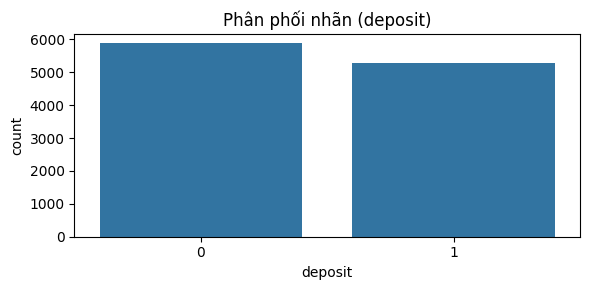

In [2]:
import seaborn as sns

df = pd.read_csv('../data/raw/bank.csv')
df['deposit'] = df['deposit'].map({'yes': 1, 'no': 0})
cat_cols = df.select_dtypes(include=['object']).columns
df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True)

X = df_encoded.drop('deposit', axis=1).values
y = df_encoded['deposit'].values

print('='*55)
print('      THÔNG TIN BỘ DỮ LIỆU BANK MARKETING')
print('='*55)
print(f'  Số mẫu       : {X.shape[0]}')
print(f'  Số đặc trưng : {X.shape[1]} (sau One-Hot Encoding)')
print(f'  Số lớp       : {len(np.unique(y))} (Gửi:1, Không:0)')
print(f'  Phân phối    : {dict(zip(*np.unique(y, return_counts=True)))}')
print('='*55)

plt.figure(figsize=(6, 3))
sns.countplot(data=df, x='deposit')
plt.title('Phân phối nhãn (deposit)')
plt.tight_layout()
plt.show()

## ⚙️ Giai đoạn 2 — Tiền xử lý

In [3]:
RANDOM_SEED = 42

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_SEED, stratify=y
)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

print('✅ Tiền xử lý hoàn tất')
print(f'   Train : {X_train_sc.shape[0]} mẫu')
print(f'   Test  : {X_test_sc.shape[0]} mẫu')

✅ Tiền xử lý hoàn tất
   Train : 8929 mẫu
   Test  : 2233 mẫu


## 🔧 Giai đoạn 3 — Định nghĩa không gian tìm kiếm & Hàm fitness


In [4]:
LOW  = np.array([16,  -4.0, -5.0])
HIGH = np.array([256, -1.0, -1.0])
DIM  = 3

def decode_position(x):
    n_neurons = int(np.clip(round(x[0]), 16, 256))
    lr        = float(10 ** np.clip(x[1], -4.0, -1.0))
    alpha     = float(10 ** np.clip(x[2], -5.0, -1.0))
    return n_neurons, lr, alpha

def fitness_single(x, X_tr, y_tr, cv_obj, seed):
    
    n_neurons, lr, alpha = decode_position(x)
    model = MLPClassifier(
        hidden_layer_sizes=(n_neurons, n_neurons),
        activation='relu',
        learning_rate_init=lr,
        alpha=alpha,
        max_iter=500,
        random_state=seed,
        early_stopping=True,
        n_iter_no_change=15
    )
    scores = cross_val_score(model, X_tr, y_tr, cv=cv_obj,
                             scoring='accuracy', n_jobs=-1)
    return scores.mean()

def fitness_averaged(x, X_tr, y_tr, cv_obj, seed, k=3):
    
    scores_all = []
    for run in range(k):
        n_neurons, lr, alpha = decode_position(x)
        model = MLPClassifier(
            hidden_layer_sizes=(n_neurons, n_neurons),
            activation='relu',
            learning_rate_init=lr,
            alpha=alpha,
            max_iter=500,
            random_state=seed + run, 
            early_stopping=True,
            n_iter_no_change=15
        )
        s = cross_val_score(model, X_tr, y_tr, cv=cv_obj,
                            scoring='accuracy', n_jobs=-1)
        scores_all.append(s.mean())
    return np.mean(scores_all)

print('✅ Không gian tìm kiếm (3 chiều):')
print(f'   x[0] = n_neurons    ∈ [16, 256]')
print(f'   x[1] = log10(lr)    ∈ [-4, -1]  →  lr    ∈ [0.0001, 0.1]')
print(f'   x[2] = log10(alpha) ∈ [-5, -1]  →  alpha ∈ [0.00001, 0.1]')

✅ Không gian tìm kiếm (3 chiều):
   x[0] = n_neurons    ∈ [16, 256]
   x[1] = log10(lr)    ∈ [-4, -1]  →  lr    ∈ [0.0001, 0.1]
   x[2] = log10(alpha) ∈ [-5, -1]  →  alpha ∈ [0.00001, 0.1]


## 🔵 Giai đoạn 4 — Standard PSO


In [ ]:
def run_standard_pso(
    X_tr, y_tr,
    n_particles=12, n_iter=20,
    w=0.7,       
    n1=1.5,      
    n2=1.5,      
    v_max_ratio=0.2,
    seed=42
):
    rng    = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    v_max  = v_max_ratio * (HIGH - LOW)

    positions  = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    velocities = rng.uniform(-(HIGH-LOW)*0.1, (HIGH-LOW)*0.1, size=(n_particles, DIM))
    pbest_pos   = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos   = None
    gbest_score = -np.inf
    convergence = []
    history     = []

    print(f'🔵 Standard PSO | w={w} (cố định) | n1={n1}, n2={n2}')
    print(f'   {n_particles} particles × {n_iter} iterations')
    print('─'*60)
    t_start = time.time()

    for it in range(n_iter):
        for i in range(n_particles):
            score = fitness_single(positions[i], X_tr, y_tr, cv_obj, seed)
            n, lr, al = decode_position(positions[i])
            history.append({'iter': it, 'particle': i, 'score': score,
                            'n_neurons': n, 'lr': lr, 'alpha': al})
            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i]   = positions[i].copy()
            if score > gbest_score:
                gbest_score = score
                gbest_pos   = positions[i].copy()

        r1 = rng.random(size=(n_particles, DIM))
        r2 = rng.random(size=(n_particles, DIM))
        velocities = (
            w  * velocities
            + n1 * r1 * (pbest_pos - positions)
            + n2 * r2 * (gbest_pos - positions)
        )
        
        velocities = np.clip(velocities, -v_max, v_max)
        positions  = np.clip(positions + velocities, LOW, HIGH)

        convergence.append(gbest_score)
        n, lr, al = decode_position(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | gbest={gbest_score:.4f} | '
              f'neurons={n:3d}, lr={lr:.5f}, alpha={al:.6f} | [{time.time()-t_start:.0f}s]')

    print('─'*60)
    print(f'✅ Hoàn thành! Thời gian: {time.time()-t_start:.1f}s')
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history)


gbest_std, cv_std, conv_std, hist_std = run_standard_pso(
    X_train_sc, y_train,
    n_particles=12, n_iter=20,
    w=0.7, n1=1.5, n2=1.5,
    seed=RANDOM_SEED
)
n_std, lr_std, al_std = decode_position(gbest_std)
print(f'\n  Best: neurons={n_std}, lr={lr_std:.5f}, alpha={al_std:.6f}')
print(f'  CV Accuracy: {cv_std:.4f}')

In [ ]:
import joblib, os

os.makedirs('pso_results', exist_ok=True)

joblib.dump({
    'gbest_pos': gbest_std,
    'cv_score':  cv_std,
    'convergence': conv_std,
    'history':   hist_std
}, 'pso_results/standard_pso.pkl')

print('✅ Đã lưu: pso_results/standard_pso.pkl')

## 🟢 Giai đoạn 5 — PSO với Linear Decay Inertia Weight

In [ ]:
def run_pso_linear_decay(
    X_tr, y_tr,
    n_particles=12, n_iter=20,
    w_start=0.9,  
    w_end=0.4,    
    n1=1.5,
    n2=1.5,
    v_max_ratio=0.2,
    seed=42
):
    
    rng    = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    v_max  = v_max_ratio * (HIGH - LOW)

    positions  = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    velocities = rng.uniform(-(HIGH-LOW)*0.1, (HIGH-LOW)*0.1, size=(n_particles, DIM))
    pbest_pos   = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos   = None
    gbest_score = -np.inf
    convergence = []
    history     = []
    w_history   = []  

    print(f'🟢 PSO + Linear Decay w | w_start={w_start} → w_end={w_end}')
    print(f'   {n_particles} particles × {n_iter} iterations')
    print('─'*60)
    t_start = time.time()

    for it in range(n_iter):
        w_current = w_start - (w_start - w_end) / n_iter * it
        w_history.append(w_current)

        for i in range(n_particles):
            score = fitness_single(positions[i], X_tr, y_tr, cv_obj, seed)
            n, lr, al = decode_position(positions[i])
            history.append({'iter': it, 'particle': i, 'score': score,
                            'n_neurons': n, 'lr': lr, 'alpha': al, 'w': w_current})
            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i]   = positions[i].copy()
            if score > gbest_score:
                gbest_score = score
                gbest_pos   = positions[i].copy()

        r1 = rng.random(size=(n_particles, DIM))
        r2 = rng.random(size=(n_particles, DIM))
        velocities = (
            w_current * velocities
            + n1 * r1 * (pbest_pos - positions)
            + n2 * r2 * (gbest_pos - positions)
        )
        velocities = np.clip(velocities, -v_max, v_max)
        positions  = np.clip(positions + velocities, LOW, HIGH)

        convergence.append(gbest_score)
        n, lr, al = decode_position(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | w={w_current:.3f} | gbest={gbest_score:.4f} | '
              f'neurons={n:3d}, lr={lr:.5f} | [{time.time()-t_start:.0f}s]')

    print('─'*60)
    print(f'✅ Hoàn thành! Thời gian: {time.time()-t_start:.1f}s')
    df_hist = pd.DataFrame(history)
    return gbest_pos, gbest_score, convergence, df_hist, w_history


gbest_ld, cv_ld, conv_ld, hist_ld, w_hist_ld = run_pso_linear_decay(
    X_train_sc, y_train,
    n_particles=12, n_iter=20,
    w_start=0.9, w_end=0.4,
    n1=1.5, n2=1.5,
    seed=RANDOM_SEED
)
n_ld, lr_ld, al_ld = decode_position(gbest_ld)
print(f'\n  Best: neurons={n_ld}, lr={lr_ld:.5f}, alpha={al_ld:.6f}')
print(f'  CV Accuracy: {cv_ld:.4f}')

🟢 PSO + Linear Decay w | w_start=0.9 → w_end=0.4
   12 particles × 20 iterations
────────────────────────────────────────────────────────────
  Iter  1/20 | w=0.900 | gbest=0.8438 | neurons=203, lr=0.00038 | [35s]
  Iter  2/20 | w=0.875 | gbest=0.8452 | neurons=218, lr=0.00579 | [78s]
  Iter  3/20 | w=0.850 | gbest=0.8452 | neurons=218, lr=0.00579 | [121s]
  Iter  4/20 | w=0.825 | gbest=0.8452 | neurons=218, lr=0.00579 | [169s]
  Iter  5/20 | w=0.800 | gbest=0.8452 | neurons=218, lr=0.00579 | [213s]
  Iter  6/20 | w=0.775 | gbest=0.8452 | neurons=214, lr=0.00678 | [253s]
  Iter  7/20 | w=0.750 | gbest=0.8457 | neurons=200, lr=0.00047 | [296s]
  Iter  8/20 | w=0.725 | gbest=0.8457 | neurons=200, lr=0.00047 | [342s]
  Iter  9/20 | w=0.700 | gbest=0.8457 | neurons=200, lr=0.00047 | [404s]
  Iter 10/20 | w=0.675 | gbest=0.8457 | neurons=200, lr=0.00047 | [468s]
  Iter 11/20 | w=0.650 | gbest=0.8457 | neurons=200, lr=0.00047 | [519s]
  Iter 12/20 | w=0.625 | gbest=0.8459 | neurons=196, lr=0

In [ ]:
import joblib
joblib.dump({
    'gbest_pos':  gbest_ld,
    'cv_score':   cv_ld,
    'convergence': conv_ld,
    'history':    hist_ld,
    'w_history':  w_hist_ld
}, '../results/linear_decay_pso.pkl')

print('Đã lưu: results/linear_decay_pso.pkl')

## 🟡 Giai đoạn 6 — PSO với Fitness Averaging


In [ ]:
def run_pso_fitness_avg(
    X_tr, y_tr,
    n_particles=12, n_iter=20,
    w_start=0.9, w_end=0.4,
    n1=1.5, n2=1.5,
    v_max_ratio=0.2,
    k_avg=3,     
    seed=42
):
    
    rng    = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    v_max  = v_max_ratio * (HIGH - LOW)

    positions  = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    velocities = rng.uniform(-(HIGH-LOW)*0.1, (HIGH-LOW)*0.1, size=(n_particles, DIM))
    pbest_pos   = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos   = None
    gbest_score = -np.inf
    convergence = []
    history     = []

    print(f'🟡 PSO + Fitness Averaging (k={k_avg}) | w_start={w_start} → w_end={w_end}')
    print(f'   {n_particles} particles × {n_iter} iterations | tổng fitness calls ≈ {n_particles*n_iter*k_avg}')
    print('─'*60)
    t_start = time.time()

    for it in range(n_iter):
        w_current = w_start - (w_start - w_end) / n_iter * it

        for i in range(n_particles):
            score = fitness_averaged(positions[i], X_tr, y_tr, cv_obj, seed, k=k_avg)
            n, lr, al = decode_position(positions[i])
            history.append({'iter': it, 'particle': i, 'score': score,
                            'n_neurons': n, 'lr': lr, 'alpha': al})
            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i]   = positions[i].copy()
            if score > gbest_score:
                gbest_score = score
                gbest_pos   = positions[i].copy()

        r1 = rng.random(size=(n_particles, DIM))
        r2 = rng.random(size=(n_particles, DIM))
        velocities = (
            w_current * velocities
            + n1 * r1 * (pbest_pos - positions)
            + n2 * r2 * (gbest_pos - positions)
        )
        velocities = np.clip(velocities, -v_max, v_max)
        positions  = np.clip(positions + velocities, LOW, HIGH)

        convergence.append(gbest_score)
        n, lr, al = decode_position(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | w={w_current:.3f} | gbest={gbest_score:.4f} | '
              f'neurons={n:3d}, lr={lr:.5f} | [{time.time()-t_start:.0f}s]')

    print('─'*60)
    print(f'✅ Hoàn thành! Thời gian: {time.time()-t_start:.1f}s')
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history)


gbest_fa, cv_fa, conv_fa, hist_fa = run_pso_fitness_avg(
    X_train_sc, y_train,
    n_particles=12, n_iter=20,
    w_start=0.9, w_end=0.4,
    n1=1.5, n2=1.5,
    k_avg=3,
    seed=RANDOM_SEED
)
n_fa, lr_fa, al_fa = decode_position(gbest_fa)
print(f'\n  Best: neurons={n_fa}, lr={lr_fa:.5f}, alpha={al_fa:.6f}')
print(f'  CV Accuracy: {cv_fa:.4f}')

🟡 PSO + Fitness Averaging (k=3) | w_start=0.9 → w_end=0.4
   12 particles × 20 iterations | tổng fitness calls ≈ 720
────────────────────────────────────────────────────────────
  Iter  1/20 | w=0.900 | gbest=0.8423 | neurons=124, lr=0.00130 | [111s]
  Iter  2/20 | w=0.875 | gbest=0.8435 | neurons=173, lr=0.00043 | [207s]
  Iter  3/20 | w=0.850 | gbest=0.8440 | neurons=163, lr=0.00086 | [307s]
  Iter  4/20 | w=0.825 | gbest=0.8440 | neurons=163, lr=0.00086 | [449s]
  Iter  5/20 | w=0.800 | gbest=0.8440 | neurons=163, lr=0.00086 | [597s]
  Iter  6/20 | w=0.775 | gbest=0.8449 | neurons=162, lr=0.00048 | [746s]
  Iter  7/20 | w=0.750 | gbest=0.8449 | neurons=162, lr=0.00048 | [909s]
  Iter  8/20 | w=0.725 | gbest=0.8449 | neurons=162, lr=0.00048 | [1080s]
  Iter  9/20 | w=0.700 | gbest=0.8449 | neurons=162, lr=0.00048 | [1248s]
  Iter 10/20 | w=0.675 | gbest=0.8449 | neurons=162, lr=0.00048 | [1402s]
  Iter 11/20 | w=0.650 | gbest=0.8449 | neurons=162, lr=0.00048 | [1539s]
  Iter 12/20 | 

In [ ]:
joblib.dump({
    'gbest_pos':  gbest_fa,
    'cv_score':   cv_fa,
    'convergence': conv_fa,
    'history':    hist_fa
}, 'pso_results/fitness_avg_pso.pkl')

print('✅ Đã lưu: pso_results/fitness_avg_pso.pkl')

✅ Đã lưu: pso_results/fitness_avg_pso.pkl


## 🟠 Giai đoạn 7 — Constriction-type PSO (CPSO)


In [ ]:
def compute_constriction_factor(n1, n2):
    """
    Tính Constriction Factor K — Equation (5) từ Meissner et al. 2006.
    Yêu cầu: phi = n1 + n2 > 4
    """
    phi = n1 + n2
    if phi <= 4:
        raise ValueError(f'φ = n1 + n2 = {phi} phải > 4 để K có nghĩa (Eq.6)')
    K = 2.0 / abs(2 - phi - np.sqrt(phi**2 - 4*phi))
    return K


def run_cpso(
    X_tr, y_tr,
    n_particles=12, n_iter=20,
    n1=2.05,     
    n2=2.05,     
    seed=42
):
    """
    Constriction-type PSO (CPSO) — Equations (4)(5)(6) từ Meissner et al. 2006.
    Không dùng Vmax riêng vì K đã kiểm soát vận tốc.
    """
    K      = compute_constriction_factor(n1, n2)
    phi    = n1 + n2
    rng    = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

    positions  = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    velocities = rng.uniform(-(HIGH-LOW)*0.1, (HIGH-LOW)*0.1, size=(n_particles, DIM))
    pbest_pos   = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos   = None
    gbest_score = -np.inf
    convergence = []
    history     = []

    print(f'🟠 CPSO | n1={n1}, n2={n2} | φ={phi:.2f} | K={K:.4f}')
    print(f'   {n_particles} particles × {n_iter} iterations')
    print('─'*60)
    t_start = time.time()

    for it in range(n_iter):
        for i in range(n_particles):
            score = fitness_single(positions[i], X_tr, y_tr, cv_obj, seed)
            n, lr, al = decode_position(positions[i])
            history.append({'iter': it, 'particle': i, 'score': score,
                            'n_neurons': n, 'lr': lr, 'alpha': al})
            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i]   = positions[i].copy()
            if score > gbest_score:
                gbest_score = score
                gbest_pos   = positions[i].copy()

        r1 = rng.random(size=(n_particles, DIM))
        r2 = rng.random(size=(n_particles, DIM))
        velocities = K * (
            velocities
            + n1 * r1 * (pbest_pos - positions)
            + n2 * r2 * (gbest_pos - positions)
        )
        positions = np.clip(positions + velocities, LOW, HIGH)

        convergence.append(gbest_score)
        n, lr, al = decode_position(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | K={K:.4f} | gbest={gbest_score:.4f} | '
              f'neurons={n:3d}, lr={lr:.5f} | [{time.time()-t_start:.0f}s]')

    print('─'*60)
    print(f'✅ Hoàn thành! Thời gian: {time.time()-t_start:.1f}s')
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history), K


gbest_cp, cv_cp, conv_cp, hist_cp, K_val = run_cpso(
    X_train_sc, y_train,
    n_particles=12, n_iter=20,
    n1=2.05, n2=2.05,
    seed=RANDOM_SEED
)
n_cp, lr_cp, al_cp = decode_position(gbest_cp)
print(f'\n  Best: neurons={n_cp}, lr={lr_cp:.5f}, alpha={al_cp:.6f}')
print(f'  CV Accuracy: {cv_cp:.4f}')

🟠 CPSO | n1=2.05, n2=2.05 | φ=4.10 | K=0.7298
   12 particles × 20 iterations
────────────────────────────────────────────────────────────
  Iter  1/20 | K=0.7298 | gbest=0.8438 | neurons=203, lr=0.00038 | [50s]
  Iter  2/20 | K=0.7298 | gbest=0.8438 | neurons=203, lr=0.00038 | [108s]
  Iter  3/20 | K=0.7298 | gbest=0.8438 | neurons=203, lr=0.00038 | [174s]
  Iter  4/20 | K=0.7298 | gbest=0.8438 | neurons=203, lr=0.00038 | [320s]
  Iter  5/20 | K=0.7298 | gbest=0.8468 | neurons=206, lr=0.00017 | [480s]
  Iter  6/20 | K=0.7298 | gbest=0.8468 | neurons=206, lr=0.00017 | [647s]
  Iter  7/20 | K=0.7298 | gbest=0.8468 | neurons=206, lr=0.00017 | [803s]
  Iter  8/20 | K=0.7298 | gbest=0.8468 | neurons=206, lr=0.00017 | [994s]
  Iter  9/20 | K=0.7298 | gbest=0.8468 | neurons=206, lr=0.00017 | [1201s]
  Iter 10/20 | K=0.7298 | gbest=0.8468 | neurons=206, lr=0.00017 | [1393s]
  Iter 11/20 | K=0.7298 | gbest=0.8468 | neurons=206, lr=0.00017 | [1604s]
  Iter 12/20 | K=0.7298 | gbest=0.8468 | neur

In [ ]:
joblib.dump({
    'gbest_pos':  gbest_cp,
    'cv_score':   cv_cp,
    'convergence': conv_cp,
    'history':    hist_cp,
    'K_val':      K_val
}, 'result/cpso.pkl')

print('Đã lưu: ../results/cpso.pkl')

Đã lưu: pso_results/cpso.pkl


## 🟣 Giai đoạn 11 — FO-PSO (Fractional-Order Particle Swarm Optimization)

In [ ]:
def run_fopso(
    X_tr, y_tr,
    n_particles=12, n_iter=20,
    alpha=0.6,    # Hệ số đạo hàm bậc phân số
    r=4,          # Số lượng v_t trong quá khứ được giữ lại
    n1=1.5, n2=1.5,
    v_max_ratio=0.2,
    seed=42
):
    rng    = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    v_max  = v_max_ratio * (HIGH - LOW)

    positions  = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    velocities = rng.uniform(-(HIGH-LOW)*0.1, (HIGH-LOW)*0.1, size=(n_particles, DIM))
    pbest_pos   = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos   = None
    gbest_score = -np.inf
    convergence = []
    history     = []

    # Khởi tạo bộ nhớ cho các vận tốc trong quá khứ: v_{t}, v_{t-1}, v_{t-2}, v_{t-3}
    v_memory = np.zeros((r, n_particles, DIM))
    v_memory[0] = velocities

    # Tính các hệ số trọng lượng phân số (Fractional Coefficients)
    c_w = np.zeros(r)
    c_w[0] = alpha
    for k in range(1, r):
        c_w[k] = c_w[k-1] * (k - alpha) / (k + 1)

    print(f'🟣 FO-PSO | alpha: {alpha} | r: {r} | c_w: {np.round(c_w, 4)}')
    print(f'   {n_particles} particles × {n_iter} iterations')
    print('─'*60)
    import time
    t_start = time.time()

    for it in range(n_iter):
        for i in range(n_particles):
            score = fitness_single(positions[i], X_tr, y_tr, cv_obj, seed)  # General fitness
            n_neur, lr, al = decode_position(positions[i])
            history.append({'iter': it, 'particle': i, 'score': score,
                            'n_neurons': n_neur, 'lr': lr, 'alpha': al})
            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i]   = positions[i].copy()
            if score > gbest_score:
                gbest_score = score
                gbest_pos   = positions[i].copy()

        r1 = rng.random(size=(n_particles, DIM))
        r2 = rng.random(size=(n_particles, DIM))
        
        # Tính thành phần quán tính dựa trên đạo hàm bậc phân số
        inertial_velocity = np.zeros((n_particles, DIM))
        for k in range(r):
            inertial_velocity += c_w[k] * v_memory[k]
        
        velocities = (
            inertial_velocity
            + n1 * r1 * (pbest_pos - positions)
            + n2 * r2 * (gbest_pos - positions)
        )
        velocities = np.clip(velocities, -v_max, v_max)
        
        # Cập nhật bộ nhớ vận tốc (dịch chuyển các vận tốc cũ xuống)
        for k in range(r - 1, 0, -1):
            v_memory[k] = v_memory[k-1]
        v_memory[0] = velocities

        positions  = np.clip(positions + velocities, LOW, HIGH)
        convergence.append(gbest_score)
        
        n_neur, lr, al = decode_position(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | gbest={gbest_score:.4f} | '
              f'neurons={n_neur:3d}, lr={lr:.5f} | [{time.time()-t_start:.0f}s]')

    print('─'*60)
    print(f'✅ Hoàn thành! Thời gian: {time.time()-t_start:.1f}s')
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history)

# Chạy thử nghiệm thuật toán FO-PSO
gbest_fo, cv_fo, conv_fo, hist_fo = run_fopso(
    X_train_sc, y_train,
    n_particles=12, n_iter=20,
    alpha=0.6, r=4,
    n1=1.5, n2=1.5,
    seed=RANDOM_SEED
)

n_fo, lr_fo, al_fo = decode_position(gbest_fo)
print(f'\n  Best FO-PSO: neurons={n_fo}, lr={lr_fo:.5f}, alpha={al_fo:.6f}')
print(f'  CV Accuracy: {cv_fo:.4f}')


In [ ]:
import joblib, os

os.makedirs('pso_results', exist_ok=True)
joblib.dump({
    'gbest_pos':  gbest_fo,
    'cv_score':   cv_fo,
    'convergence': conv_fo,
    'history':    hist_fo
}, 'pso_results/fopso.pkl')

print('✅ Đã lưu: pso_results/fopso.pkl')


## 🟣 Giai đoạn 12 — A-PSO (Angle-based Velocity Adjustment Particle Swarm Optimization)

In [ ]:
def run_apso(
    X_tr, y_tr,
    n_particles=12, n_iter=20,
    w_max=0.9, w_min=0.2,
    c1=1.5, c2=1.5,
    v_max_ratio=0.2,
    seed=42
):
    rng    = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    v_max  = v_max_ratio * (HIGH - LOW)

    positions  = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    velocities = rng.uniform(-(HIGH-LOW)*0.1, (HIGH-LOW)*0.1, size=(n_particles, DIM))
    pbest_pos   = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos   = None
    gbest_score = -np.inf
    convergence = []
    history     = []

    print(f'🟣 A-PSO | Điều hướng theo góc | w: {w_max} -> {w_min} (dựa vào góc)')
    print(f'   {n_particles} particles × {n_iter} iterations')
    print('─'*60)
    import time
    t_start = time.time()

    for it in range(n_iter):
        for i in range(n_particles):
            score = fitness_single(positions[i], X_tr, y_tr, cv_obj, seed)
            n_neur, lr, al = decode_position(positions[i])
            history.append({'iter': it, 'particle': i, 'score': score,
                            'n_neurons': n_neur, 'lr': lr, 'alpha': al})
            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i]   = positions[i].copy()
            if score > gbest_score:
                gbest_score = score
                gbest_pos   = positions[i].copy()

        # Tính góc giữa véc-tơ vận tốc và véc-tơ hướng về gbest
        direction_to_gbest = gbest_pos - positions
        dot_product = np.sum(velocities * direction_to_gbest, axis=1)
        norm_v = np.linalg.norm(velocities, axis=1) + 1e-8
        norm_d = np.linalg.norm(direction_to_gbest, axis=1) + 1e-8
        cos_theta = dot_product / (norm_v * norm_d)  

        # Ánh xạ cos_theta từ [-1, 1] sang w từ [w_min, w_max]
        w_dynamic = w_min + (w_max - w_min) * ((cos_theta + 1.0) / 2.0)
        w_matrix = np.tile(w_dynamic, (DIM, 1)).T

        r1 = rng.random(size=(n_particles, DIM))
        r2 = rng.random(size=(n_particles, DIM))

        velocities = (
            w_matrix * velocities
            + c1 * r1 * (pbest_pos - positions)
            + c2 * r2 * (gbest_pos - positions)
        )
        velocities = np.clip(velocities, -v_max, v_max)
        positions  = np.clip(positions + velocities, LOW, HIGH)

        convergence.append(gbest_score)

        n_neur, lr, al = decode_position(gbest_pos)
        avg_w = np.mean(w_dynamic)
        print(f'  Iter {it+1:2d}/{n_iter} | gbest={gbest_score:.4f} | '
              f'neurons={n_neur:3d}, lr={lr:.5f} | avg_w={avg_w:.3f} | [{time.time()-t_start:.0f}s]')

    print('─'*60)
    print(f'✅ Hoàn thành! Thời gian: {time.time()-t_start:.1f}s')
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history)

# Chạy thử nghiệm thuật toán A-PSO
gbest_apso, cv_apso, conv_apso, hist_apso = run_apso(
    X_train_sc, y_train,
    n_particles=12, n_iter=20,
    w_max=0.9, w_min=0.2,
    c1=1.5, c2=1.5,
    seed=RANDOM_SEED
)

n_apso, lr_apso, al_apso = decode_position(gbest_apso)
print(f'\n  Best A-PSO: neurons={n_apso}, lr={lr_apso:.5f}, alpha={al_apso:.6f}')
print(f'  CV Accuracy: {cv_apso:.4f}')


In [ ]:
import joblib, os

os.makedirs('pso_results', exist_ok=True)
joblib.dump({
    'gbest_pos':  gbest_apso,
    'cv_score':   cv_apso,
    'convergence': conv_apso,
    'history':    hist_apso
}, 'pso_results/apso.pkl')

print('✅ Đã lưu: pso_results/apso.pkl')


## 🟣 Giai đoạn 13 — Lực hút phi tuyến (Non-linear Attraction - NL-PSO)

In [ ]:
def run_nl_pso(
    X_tr, y_tr,
    n_particles=12, n_iter=20,
    w=0.729, c1=1.49445, c2=1.49445,
    gamma=2.0, # Hệ số phi tuyến (gamma càng lớn, đường cong lực hút càng cong)
    v_max_ratio=0.2,
    seed=42
):
    rng    = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    v_max  = v_max_ratio * (HIGH - LOW)
    space_range = (HIGH - LOW) + 1e-8 # Tránh chia cho 0

    positions  = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    velocities = rng.uniform(-(HIGH-LOW)*0.1, (HIGH-LOW)*0.1, size=(n_particles, DIM))
    pbest_pos   = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos   = None
    gbest_score = -np.inf
    convergence = []
    history     = []

    print(f'🟣 NL-PSO | Lực hút phi tuyến | w={w}, c1={c1}, c2={c2}, gamma={gamma}')
    print(f'   {n_particles} particles × {n_iter} iterations')
    print('─'*60)
    import time
    t_start = time.time()

    for it in range(n_iter):
        for i in range(n_particles):
            score = fitness_single(positions[i], X_tr, y_tr, cv_obj, seed)
            n_neur, lr, al = decode_position(positions[i])
            history.append({'iter': it, 'particle': i, 'score': score,
                            'n_neurons': n_neur, 'lr': lr, 'alpha': al})
            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i]   = positions[i].copy()
            if score > gbest_score:
                gbest_score = score
                gbest_pos   = positions[i].copy()

        r1 = rng.random(size=(n_particles, DIM))
        r2 = rng.random(size=(n_particles, DIM))
        
        # --- NON-LINEAR ATTRACTION LOGIC ---
        # 1. Khoảng cách vật lý
        dist_p = pbest_pos - positions
        dist_g = gbest_pos - positions
        
        # 2. Chuẩn hóa khoảng cách về [0, 1] so với không gian
        norm_dist_p = np.abs(dist_p) / space_range
        norm_dist_g = np.abs(dist_g) / space_range
        
        # 3. Tính lực phi tuyến qua hàm (1 - e^(-gamma * x)) và khôi phục tỷ lệ
        nl_attraction_p = np.sign(dist_p) * (1 - np.exp(-gamma * norm_dist_p)) * space_range
        nl_attraction_g = np.sign(dist_g) * (1 - np.exp(-gamma * norm_dist_g)) * space_range

        velocities = (
            w * velocities
            + c1 * r1 * nl_attraction_p
            + c2 * r2 * nl_attraction_g
        )
        velocities = np.clip(velocities, -v_max, v_max)
        positions  = np.clip(positions + velocities, LOW, HIGH)

        convergence.append(gbest_score)
        
        n_neur, lr, al = decode_position(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | gbest={gbest_score:.4f} | '
              f'neurons={n_neur:3d}, lr={lr:.5f} | [{time.time()-t_start:.0f}s]')

    print('─'*60)
    print(f'✅ Hoàn thành! Thời gian: {time.time()-t_start:.1f}s')
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history)

# Chạy thử nghiệm thuật toán NL-PSO
gbest_nl, cv_nl, conv_nl, hist_nl = run_nl_pso(
    X_train_sc, y_train,
    n_particles=12, n_iter=20,
    seed=RANDOM_SEED
)


🟣 NL-PSO | Lực hút phi tuyến | w=0.729, c1=1.49445, c2=1.49445, gamma=2.0
   12 particles × 20 iterations
────────────────────────────────────────────────────────────
  Iter  1/20 | gbest=0.8438 | neurons=203, lr=0.00038 | [71s]
  Iter  2/20 | gbest=0.8439 | neurons=119, lr=0.00494 | [156s]
  Iter  3/20 | gbest=0.8444 | neurons=141, lr=0.00207 | [219s]
  Iter  4/20 | gbest=0.8444 | neurons=141, lr=0.00207 | [279s]
  Iter  5/20 | gbest=0.8453 | neurons=154, lr=0.00165 | [318s]
  Iter  6/20 | gbest=0.8453 | neurons=154, lr=0.00165 | [354s]
  Iter  7/20 | gbest=0.8453 | neurons=154, lr=0.00165 | [387s]
  Iter  8/20 | gbest=0.8453 | neurons=154, lr=0.00165 | [416s]
  Iter  9/20 | gbest=0.8456 | neurons=130, lr=0.00177 | [448s]
  Iter 10/20 | gbest=0.8456 | neurons=130, lr=0.00177 | [473s]
  Iter 11/20 | gbest=0.8456 | neurons=130, lr=0.00177 | [501s]
  Iter 12/20 | gbest=0.8456 | neurons=130, lr=0.00177 | [528s]
  Iter 13/20 | gbest=0.8456 | neurons=130, lr=0.00177 | [556s]
  Iter 14/20 | 

In [ ]:
import joblib, os
os.makedirs('pso_results', exist_ok=True)
joblib.dump({
    'gbest_pos':  gbest_nl,
    'cv_score':   cv_nl,
    'convergence': conv_nl,
    'history':    hist_nl
}, 'pso_results/nl_pso.pkl')
print('✅ Đã lưu: pso_results/nl_pso.pkl')

✅ Đã lưu: pso_results/nl_pso.pkl


## 🟣 Giai đoạn 15 — Khoảng cách kết hợp trọng tâm (Mean-based / Top-K Attraction)

In [ ]:
def run_mb_pso(
    X_tr, y_tr,
    n_particles=12, n_iter=20,
    w=0.729, c1=1.0, c2=1.0, c3=1.0, 
    top_k=4, 
    v_max_ratio=0.2,
    seed=42
):
    rng    = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    v_max  = v_max_ratio * (HIGH - LOW)

    positions  = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    velocities = rng.uniform(-(HIGH-LOW)*0.1, (HIGH-LOW)*0.1, size=(n_particles, DIM))
    pbest_pos   = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos   = None
    gbest_score = -np.inf
    convergence = []
    history     = []

    print(f'🟣 MB-PSO | Mean-based (Top-{top_k}) Attraction | w={w}, c1=c2=c3={c1}')
    print(f'   {n_particles} particles × {n_iter} iterations')
    print('─'*60)
    import time
    t_start = time.time()

    for it in range(n_iter):
        for i in range(n_particles):
            score = fitness_single(positions[i], X_tr, y_tr, cv_obj, seed)
            n_neur, lr, al = decode_position(positions[i])
            history.append({'iter': it, 'particle': i, 'score': score,
                            'n_neurons': n_neur, 'lr': lr, 'alpha': al})
            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i]   = positions[i].copy()
            if score > gbest_score:
                gbest_score = score
                gbest_pos   = positions[i].copy()

        
        top_indices = np.argsort(pbest_score)[-top_k:]
        
        mbest = np.mean(pbest_pos[top_indices], axis=0)

        # 3. Ba ma trận ngẫu nhiên cho 3 lực kéo
        r1 = rng.random(size=(n_particles, DIM))
        r2 = rng.random(size=(n_particles, DIM))
        r3 = rng.random(size=(n_particles, DIM))
        
        # Cập nhật vận tốc với 3 lực kéo (pbest, gbest, mbest)
        velocities = (
            w * velocities
            + c1 * r1 * (pbest_pos - positions)
            + c2 * r2 * (gbest_pos - positions)
            + c3 * r3 * (mbest - positions)
        )
        velocities = np.clip(velocities, -v_max, v_max)
        positions  = np.clip(positions + velocities, LOW, HIGH)

        convergence.append(gbest_score)
        
        n_neur, lr, al = decode_position(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | gbest={gbest_score:.4f} | '
              f'neurons={n_neur:3d}, lr={lr:.5f} | [{time.time()-t_start:.0f}s]')

    print('─'*60)
    print(f'✅ Hoàn thành! Thời gian: {time.time()-t_start:.1f}s')
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history)

# Chạy thử nghiệm thuật toán MB-PSO
gbest_mb, cv_mb, conv_mb, hist_mb = run_mb_pso(X_train_sc, y_train, seed=RANDOM_SEED)


🟣 MB-PSO | Mean-based (Top-4) Attraction | w=0.729, c1=c2=c3=1.0
   12 particles × 20 iterations
────────────────────────────────────────────────────────────
  Iter  1/20 | gbest=0.8438 | neurons=203, lr=0.00038 | [44s]
  Iter  2/20 | gbest=0.8438 | neurons=203, lr=0.00038 | [81s]
  Iter  3/20 | gbest=0.8438 | neurons=203, lr=0.00038 | [139s]
  Iter  4/20 | gbest=0.8450 | neurons=206, lr=0.00022 | [271s]
  Iter  5/20 | gbest=0.8450 | neurons=206, lr=0.00022 | [397s]
  Iter  6/20 | gbest=0.8450 | neurons=206, lr=0.00022 | [543s]
  Iter  7/20 | gbest=0.8450 | neurons=206, lr=0.00022 | [672s]
  Iter  8/20 | gbest=0.8450 | neurons=203, lr=0.00040 | [787s]
  Iter  9/20 | gbest=0.8462 | neurons=206, lr=0.00041 | [855s]
  Iter 10/20 | gbest=0.8462 | neurons=206, lr=0.00041 | [1002s]
  Iter 11/20 | gbest=0.8462 | neurons=206, lr=0.00041 | [1136s]
  Iter 12/20 | gbest=0.8462 | neurons=206, lr=0.00041 | [1275s]
  Iter 13/20 | gbest=0.8462 | neurons=206, lr=0.00041 | [1411s]
  Iter 14/20 | gbest=

In [ ]:
import joblib, os
os.makedirs('pso_results', exist_ok=True)
joblib.dump({
    'gbest_pos':  gbest_mb,
    'cv_score':   cv_mb,
    'convergence': conv_mb,
    'history':    hist_mb
}, 'pso_results/mbpso.pkl')
print('✅ Đã lưu: pso_results/mbpso.pkl')

✅ Đã lưu: pso_results/mbpso.pkl


## 🟣 Giai đoạn 16 — QPSO (Quantum-inspired Particle Swarm Optimization) tối ưu siêu tham số cho RNN

In [ ]:
def run_qpso(
    X_tr, y_tr,
    n_particles=12, n_iter=20,
    beta_start=1.0,   # Hệ số co giãn beta ban đầu (exploration)
    beta_end=0.5,      # Hệ số co giãn beta cuối (exploitation)
    seed=42
):
    """
    Quantum-inspired Particle Swarm Optimization (QPSO).

    Khác biệt cốt lõi so với tất cả biến thể PSO velocity-based:
      - KHÔNG sử dụng velocity (V) — hạt di chuyển theo phân phối xác suất lượng tử
      - Chỉ cần 1 tham số điều khiển duy nhất: beta (thay vì w, c1, c2)
      - Cập nhật vị trí dựa trên mean best position (mbest) và attractor point

    Công thức cập nhật vị trí (Quantum Position Update):
      mbest = (1/N) * sum(pbest_i)            # Trung bình các pbest
      p_i   = phi * pbest_i + (1-phi) * gbest # Điểm hút (attractor)
      x_i   = p_i +/- beta * |mbest - x_i| * ln(1/u)  # Nhảy lượng tử

    Tham số:
      beta_start: beta ban đầu (lớn = khám phá rộng)
      beta_end:   beta cuối cùng (nhỏ = khai thác sâu)
      beta giảm tuyến tính qua các iteration

    Tham khảo:
      Khan et al. (2025) - "Optimizing load demand forecasting in educational
      buildings using QPSO with RNNs" - Scientific Reports 15:19349
    """ 
    rng    = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

    # Khởi tạo vị trí ngẫu nhiên (KHÔNG khởi tạo velocity — QPSO không dùng!)
    positions   = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    pbest_pos   = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos   = None
    gbest_score = -np.inf
    convergence = []
    history     = []
    beta_history = []

    print(f'QPSO (Quantum-inspired PSO) | beta: {beta_start} -> {beta_end}')
    print(f'   {n_particles} particles x {n_iter} iterations')
    print(f'   Velocity-free: cap nhat vi tri bang quantum probability')
    print('-' * 60)
    t_start = time.time()

    for it in range(n_iter):
        # --- Tính beta hiện tại (linear decay: exploration -> exploitation) ---
        beta = beta_start - (beta_start - beta_end) * (it / max(n_iter - 1, 1))
        beta_history.append(beta)

        # --- Đánh giá fitness cho từng hạt ---
        for i in range(n_particles):
            score = fitness_single(positions[i], X_tr, y_tr, cv_obj, seed)
            n_neur, lr, al = decode_position(positions[i])
            history.append({
                'iter': it, 'particle': i, 'score': score,
                'n_neurons': n_neur, 'lr': lr, 'alpha': al, 'beta': beta
            })

            # Cập nhật pbest
            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i]   = positions[i].copy()

            # Cập nhật gbest
            if score > gbest_score:
                gbest_score = score
                gbest_pos   = positions[i].copy()

        # ================================================================
        # QUANTUM POSITION UPDATE — Điểm khác biệt cốt lõi của QPSO
        # ================================================================

        # Bước 1: Tính Mean Best Position (mbest)
        # mbest = trung bình vị trí tốt nhất cá nhân của tất cả hạt
        mbest = np.mean(pbest_pos, axis=0)  # shape: (DIM,)

        # Bước 2: Cập nhật vị trí từng hạt theo cơ chế lượng tử
        for i in range(n_particles):
            # 2a. Tính attractor point: nội suy giữa pbest và gbest
            phi = rng.random(size=DIM)     # phi in [0,1] cho mỗi chiều
            p = phi * pbest_pos[i] + (1 - phi) * gbest_pos  # Điểm hút

            # 2b. Quantum jump: hạt "nhảy" quanh điểm hút
            u = rng.random(size=DIM)       # u in (0,1) — tránh ln(0)
            u = np.clip(u, 1e-10, 1.0)     # Đảm bảo u > 0

            # Khoảng cách từ mbest đến vị trí hiện tại
            distance = np.abs(mbest - positions[i])

            # Dấu +/- ngẫu nhiên (50/50 cho mỗi chiều)
            sign = np.where(rng.random(size=DIM) < 0.5, 1.0, -1.0)

            # Công thức quantum update: x = p +/- beta * |mbest - x| * ln(1/u)
            positions[i] = p + sign * beta * distance * np.log(1.0 / u)

        # Bước 3: Clip vị trí về bounds hợp lệ
        positions = np.clip(positions, LOW, HIGH)

        # ================================================================

        convergence.append(gbest_score)
        n_neur, lr, al = decode_position(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | beta={beta:.3f} | gbest={gbest_score:.4f} | '
              f'neurons={n_neur:3d}, lr={lr:.5f}, alpha={al:.6f} | [{time.time()-t_start:.0f}s]')

    print('-' * 60)
    print(f'Hoan thanh QPSO! Thoi gian: {time.time()-t_start:.1f}s')
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history), beta_history


# --- Chạy thử nghiệm QPSO ---
gbest_qpso, cv_qpso, conv_qpso, hist_qpso, beta_hist_qpso = run_qpso(
    X_train_sc, y_train,
    n_particles=12, n_iter=20,
    beta_start=1.0, beta_end=0.5,
    seed=RANDOM_SEED
)
n_qpso, lr_qpso, al_qpso = decode_position(gbest_qpso)
print(f'\n  Best QPSO: neurons={n_qpso}, lr={lr_qpso:.5f}, alpha={al_qpso:.6f}')
print(f'  CV Accuracy: {cv_qpso:.4f}')


QPSO (Quantum-inspired PSO) | beta: 1.0 -> 0.5
   12 particles x 20 iterations
   Velocity-free: cap nhat vi tri bang quantum probability
------------------------------------------------------------
  Iter  1/20 | beta=1.000 | gbest=0.8438 | neurons=203, lr=0.00038, alpha=0.000736 | [64s]
  Iter  2/20 | beta=0.974 | gbest=0.8438 | neurons=203, lr=0.00038, alpha=0.000736 | [130s]
  Iter  3/20 | beta=0.947 | gbest=0.8450 | neurons=195, lr=0.04715, alpha=0.000505 | [258s]
  Iter  4/20 | beta=0.921 | gbest=0.8450 | neurons=195, lr=0.04715, alpha=0.000505 | [339s]
  Iter  5/20 | beta=0.895 | gbest=0.8450 | neurons=195, lr=0.04715, alpha=0.000505 | [418s]
  Iter  6/20 | beta=0.868 | gbest=0.8450 | neurons=195, lr=0.04715, alpha=0.000505 | [513s]
  Iter  7/20 | beta=0.842 | gbest=0.8450 | neurons=195, lr=0.04715, alpha=0.000505 | [632s]
  Iter  8/20 | beta=0.816 | gbest=0.8450 | neurons=195, lr=0.04715, alpha=0.000505 | [730s]
  Iter  9/20 | beta=0.789 | gbest=0.8450 | neurons=195, lr=0.04715

In [ ]:
import joblib, os

os.makedirs('../results/checkpoints', exist_ok=True)
joblib.dump({
    'gbest_pos':    gbest_qpso,
    'cv_score':     cv_qpso,
    'convergence':  conv_qpso,
    'history':      hist_qpso,
    'beta_history': beta_hist_qpso
}, '../results/checkpoints/qpso.pkl')

print('Da luu: ../results/checkpoints/qpso.pkl')


Da luu: ../results/checkpoints/qpso.pkl


## 📈 Giai đoạn 8 — Đánh giá trên tập Test

In [6]:
import joblib
def load_all_results():
    std  = joblib.load('../results/checkpoints/standard_pso.pkl')
    ld   = joblib.load('../results/checkpoints/linear_decay_pso.pkl')
    fa   = joblib.load('../results/checkpoints/fitness_avg_pso.pkl')
    cp   = joblib.load('../results/checkpoints/cpso.pkl')
    fo   = joblib.load('../results/checkpoints/fopso.pkl')
    apso = joblib.load('../results/checkpoints/apso.pkl')
    nl   = joblib.load('../results/checkpoints/nl_pso.pkl')
    mb   = joblib.load('../results/checkpoints/mbpso.pkl')
    qp   = joblib.load('../results/checkpoints/qpso.pkl')       # <-- THEM QPSO

    global gbest_std, cv_std, conv_std, hist_std
    global gbest_ld,  cv_ld,  conv_ld,  hist_ld,  w_hist_ld
    global gbest_fa,  cv_fa,  conv_fa,  hist_fa
    global gbest_cp,  cv_cp,  conv_cp,  hist_cp,  K_val
    global gbest_fo,  cv_fo,  conv_fo,  hist_fo
    global gbest_apso,cv_apso,conv_apso,hist_apso
    global gbest_nl,  cv_nl,  conv_nl,  hist_nl
    global gbest_mb,  cv_mb,  conv_mb,  hist_mb
    global gbest_qpso,cv_qpso,conv_qpso,hist_qpso,beta_hist_qpso  # <-- THEM

    gbest_std, cv_std, conv_std, hist_std = (std['gbest_pos'], std['cv_score'], std['convergence'], std['history'])
    gbest_ld, cv_ld, conv_ld, hist_ld, w_hist_ld = (ld['gbest_pos'], ld['cv_score'], ld['convergence'], ld['history'], ld['w_history'])
    gbest_fa, cv_fa, conv_fa, hist_fa = (fa['gbest_pos'], fa['cv_score'], fa['convergence'], fa['history'])
    gbest_cp, cv_cp, conv_cp, hist_cp, K_val = (cp['gbest_pos'], cp['cv_score'], cp['convergence'], cp['history'], cp['K_val'])
    gbest_fo, cv_fo, conv_fo, hist_fo = (fo['gbest_pos'], fo['cv_score'], fo['convergence'], fo['history'])
    gbest_apso, cv_apso, conv_apso, hist_apso = (apso['gbest_pos'], apso['cv_score'], apso['convergence'], apso['history'])
    gbest_nl, cv_nl, conv_nl, hist_nl = (nl['gbest_pos'], nl['cv_score'], nl['convergence'], nl['history'])
    gbest_mb, cv_mb, conv_mb, hist_mb = (mb['gbest_pos'], mb['cv_score'], mb['convergence'], mb['history'])
    # QPSO
    gbest_qpso, cv_qpso, conv_qpso, hist_qpso, beta_hist_qpso = (
        qp['gbest_pos'], qp['cv_score'], qp['convergence'], qp['history'], qp['beta_history']
    )
    print('Load thanh cong ket qua cua 9 bien the PSO! (bao gom QPSO)')

load_all_results()

# Decode tat ca
n_std, lr_std, al_std = decode_position(gbest_std)
n_ld,  lr_ld,  al_ld  = decode_position(gbest_ld)
n_fa,  lr_fa,  al_fa  = decode_position(gbest_fa)
n_cp,  lr_cp,  al_cp  = decode_position(gbest_cp)
n_fo,  lr_fo,  al_fo  = decode_position(gbest_fo)
n_apso, lr_apso, al_apso = decode_position(gbest_apso)
n_nl,  lr_nl,  al_nl  = decode_position(gbest_nl)
n_mb,  lr_mb,  al_mb  = decode_position(gbest_mb)
n_qpso, lr_qpso, al_qpso = decode_position(gbest_qpso)


Load thanh cong ket qua cua 9 bien the PSO! (bao gom QPSO)


In [7]:
import os
import pandas as pd

# Đường dẫn file CSV lưu trữ kết quả Test Accuracy của tất cả thuật toán
RESULT_CSV_PATH = '../results/test_results/test_accuracy.csv'

def save_test_accuracy(algo_name, test_acc, best_params=None, cv_score=None, filepath=RESULT_CSV_PATH):
    """
    Hàm lưu kết quả Test Accuracy và các siêu tham số tối ưu vào file CSV chung.
    Nếu thuật toán đã có trong file thì cập nhật (update), nếu chưa thì thêm mới (append).
    """
    os.makedirs(os.path.dirname(filepath), exist_ok=True)
    row_data = {
        'Algorithm': [algo_name],
        'Test_Accuracy': [round(float(test_acc), 4)],
        'CV_Score': [round(float(cv_score), 4) if cv_score is not None else None]
    }
    if best_params is not None:
        if isinstance(best_params, dict):
            for k, v in best_params.items():
                row_data[k] = [v]
        elif isinstance(best_params, (list, tuple)):
            if len(best_params) >= 3:
                row_data['n_neurons'] = [best_params[0]]
                row_data['lr'] = [round(float(best_params[1]), 5)]
                row_data['alpha'] = [round(float(best_params[2]), 5)]
            if len(best_params) >= 5:
                row_data['n_layers'] = [best_params[3]]
                row_data['batch_size'] = [best_params[4]]
            else:
                row_data['n_layers'] = [2]
                row_data['batch_size'] = [200]
                
    new_df = pd.DataFrame(row_data)
    
    if os.path.exists(filepath):
        df_existing = pd.read_csv(filepath)
        if algo_name in df_existing['Algorithm'].values:
            for col in new_df.columns:
                df_existing.loc[df_existing['Algorithm'] == algo_name, col] = new_df[col].values[0]
            df_existing.to_csv(filepath, index=False)
        else:
            df_combined = pd.concat([df_existing, new_df], ignore_index=True)
            df_combined.to_csv(filepath, index=False)
    else:
        new_df.to_csv(filepath, index=False)
    print(f"  💾 Đã lưu kết quả '{algo_name}' (Test Acc: {test_acc:.4f}) vào {filepath}")

def train_and_evaluate(n_neurons, lr, alpha, X_tr, y_tr, X_te, y_te, seed, label, cv_score=None):
    model = MLPClassifier(
        hidden_layer_sizes=(n_neurons, n_neurons),
        activation='relu',
        learning_rate_init=lr,
        alpha=alpha,
        max_iter=1000,
        random_state=seed,
        early_stopping=True,
        n_iter_no_change=20
    )
    model.fit(X_tr, y_tr)
    acc = model.score(X_te, y_te)
    print(f'  {label:<30} Test Accuracy = {acc:.4f}')
    save_test_accuracy(label, acc, (n_neurons, lr, alpha), cv_score=cv_score)
    return model, acc

In [28]:
print('\nDanh gia Test Accuracy cho TAT CA cac mo hinh:')
print('-' * 60)
mlp_std, test_std = train_and_evaluate(n_std, lr_std, al_std, X_train_sc, y_train, X_test_sc, y_test, RANDOM_SEED, 'Standard PSO', cv_score=cv_std)
mlp_ld,  test_ld  = train_and_evaluate(n_ld,  lr_ld,  al_ld,  X_train_sc, y_train, X_test_sc, y_test, RANDOM_SEED, 'PSO + Linear Decay w', cv_score=cv_ld)
mlp_fa,  test_fa  = train_and_evaluate(n_fa,  lr_fa,  al_fa,  X_train_sc, y_train, X_test_sc, y_test, RANDOM_SEED, 'PSO + Fitness Avg', cv_score=cv_fa)
mlp_cp,  test_cp  = train_and_evaluate(n_cp,  lr_cp,  al_cp,  X_train_sc, y_train, X_test_sc, y_test, RANDOM_SEED, 'CPSO', cv_score=cv_cp)
mlp_fo,  test_fo  = train_and_evaluate(n_fo,  lr_fo,  al_fo,  X_train_sc, y_train, X_test_sc, y_test, RANDOM_SEED, 'FO-PSO', cv_score=cv_fo)
mlp_apso,test_apso= train_and_evaluate(n_apso, lr_apso, al_apso, X_train_sc, y_train, X_test_sc, y_test, RANDOM_SEED, 'A-PSO', cv_score=cv_apso)
mlp_nl,  test_nl  = train_and_evaluate(n_nl,  lr_nl,  al_nl,  X_train_sc, y_train, X_test_sc, y_test, RANDOM_SEED, 'NL-PSO', cv_score=cv_nl)
mlp_mb,  test_mb  = train_and_evaluate(n_mb,  lr_mb,  al_mb,  X_train_sc, y_train, X_test_sc, y_test, RANDOM_SEED, 'MB-PSO', cv_score=cv_mb)
mlp_qpso,test_qpso= train_and_evaluate(n_qpso, lr_qpso, al_qpso, X_train_sc, y_train, X_test_sc, y_test, RANDOM_SEED, 'QPSO', cv_score=cv_qpso)


Danh gia Test Accuracy cho TAT CA cac mo hinh:
------------------------------------------------------------
  Standard PSO                   Test Accuracy = 0.8518
  PSO + Linear Decay w           Test Accuracy = 0.8580
  PSO + Fitness Avg              Test Accuracy = 0.8554
  CPSO                           Test Accuracy = 0.8558
  FO-PSO                         Test Accuracy = 0.8562
  A-PSO                          Test Accuracy = 0.8522
  NL-PSO                         Test Accuracy = 0.8531
  MB-PSO                         Test Accuracy = 0.8549
  QPSO                           Test Accuracy = 0.8348


## 📊 Giai đoạn 9 — Visualization tổng hợp

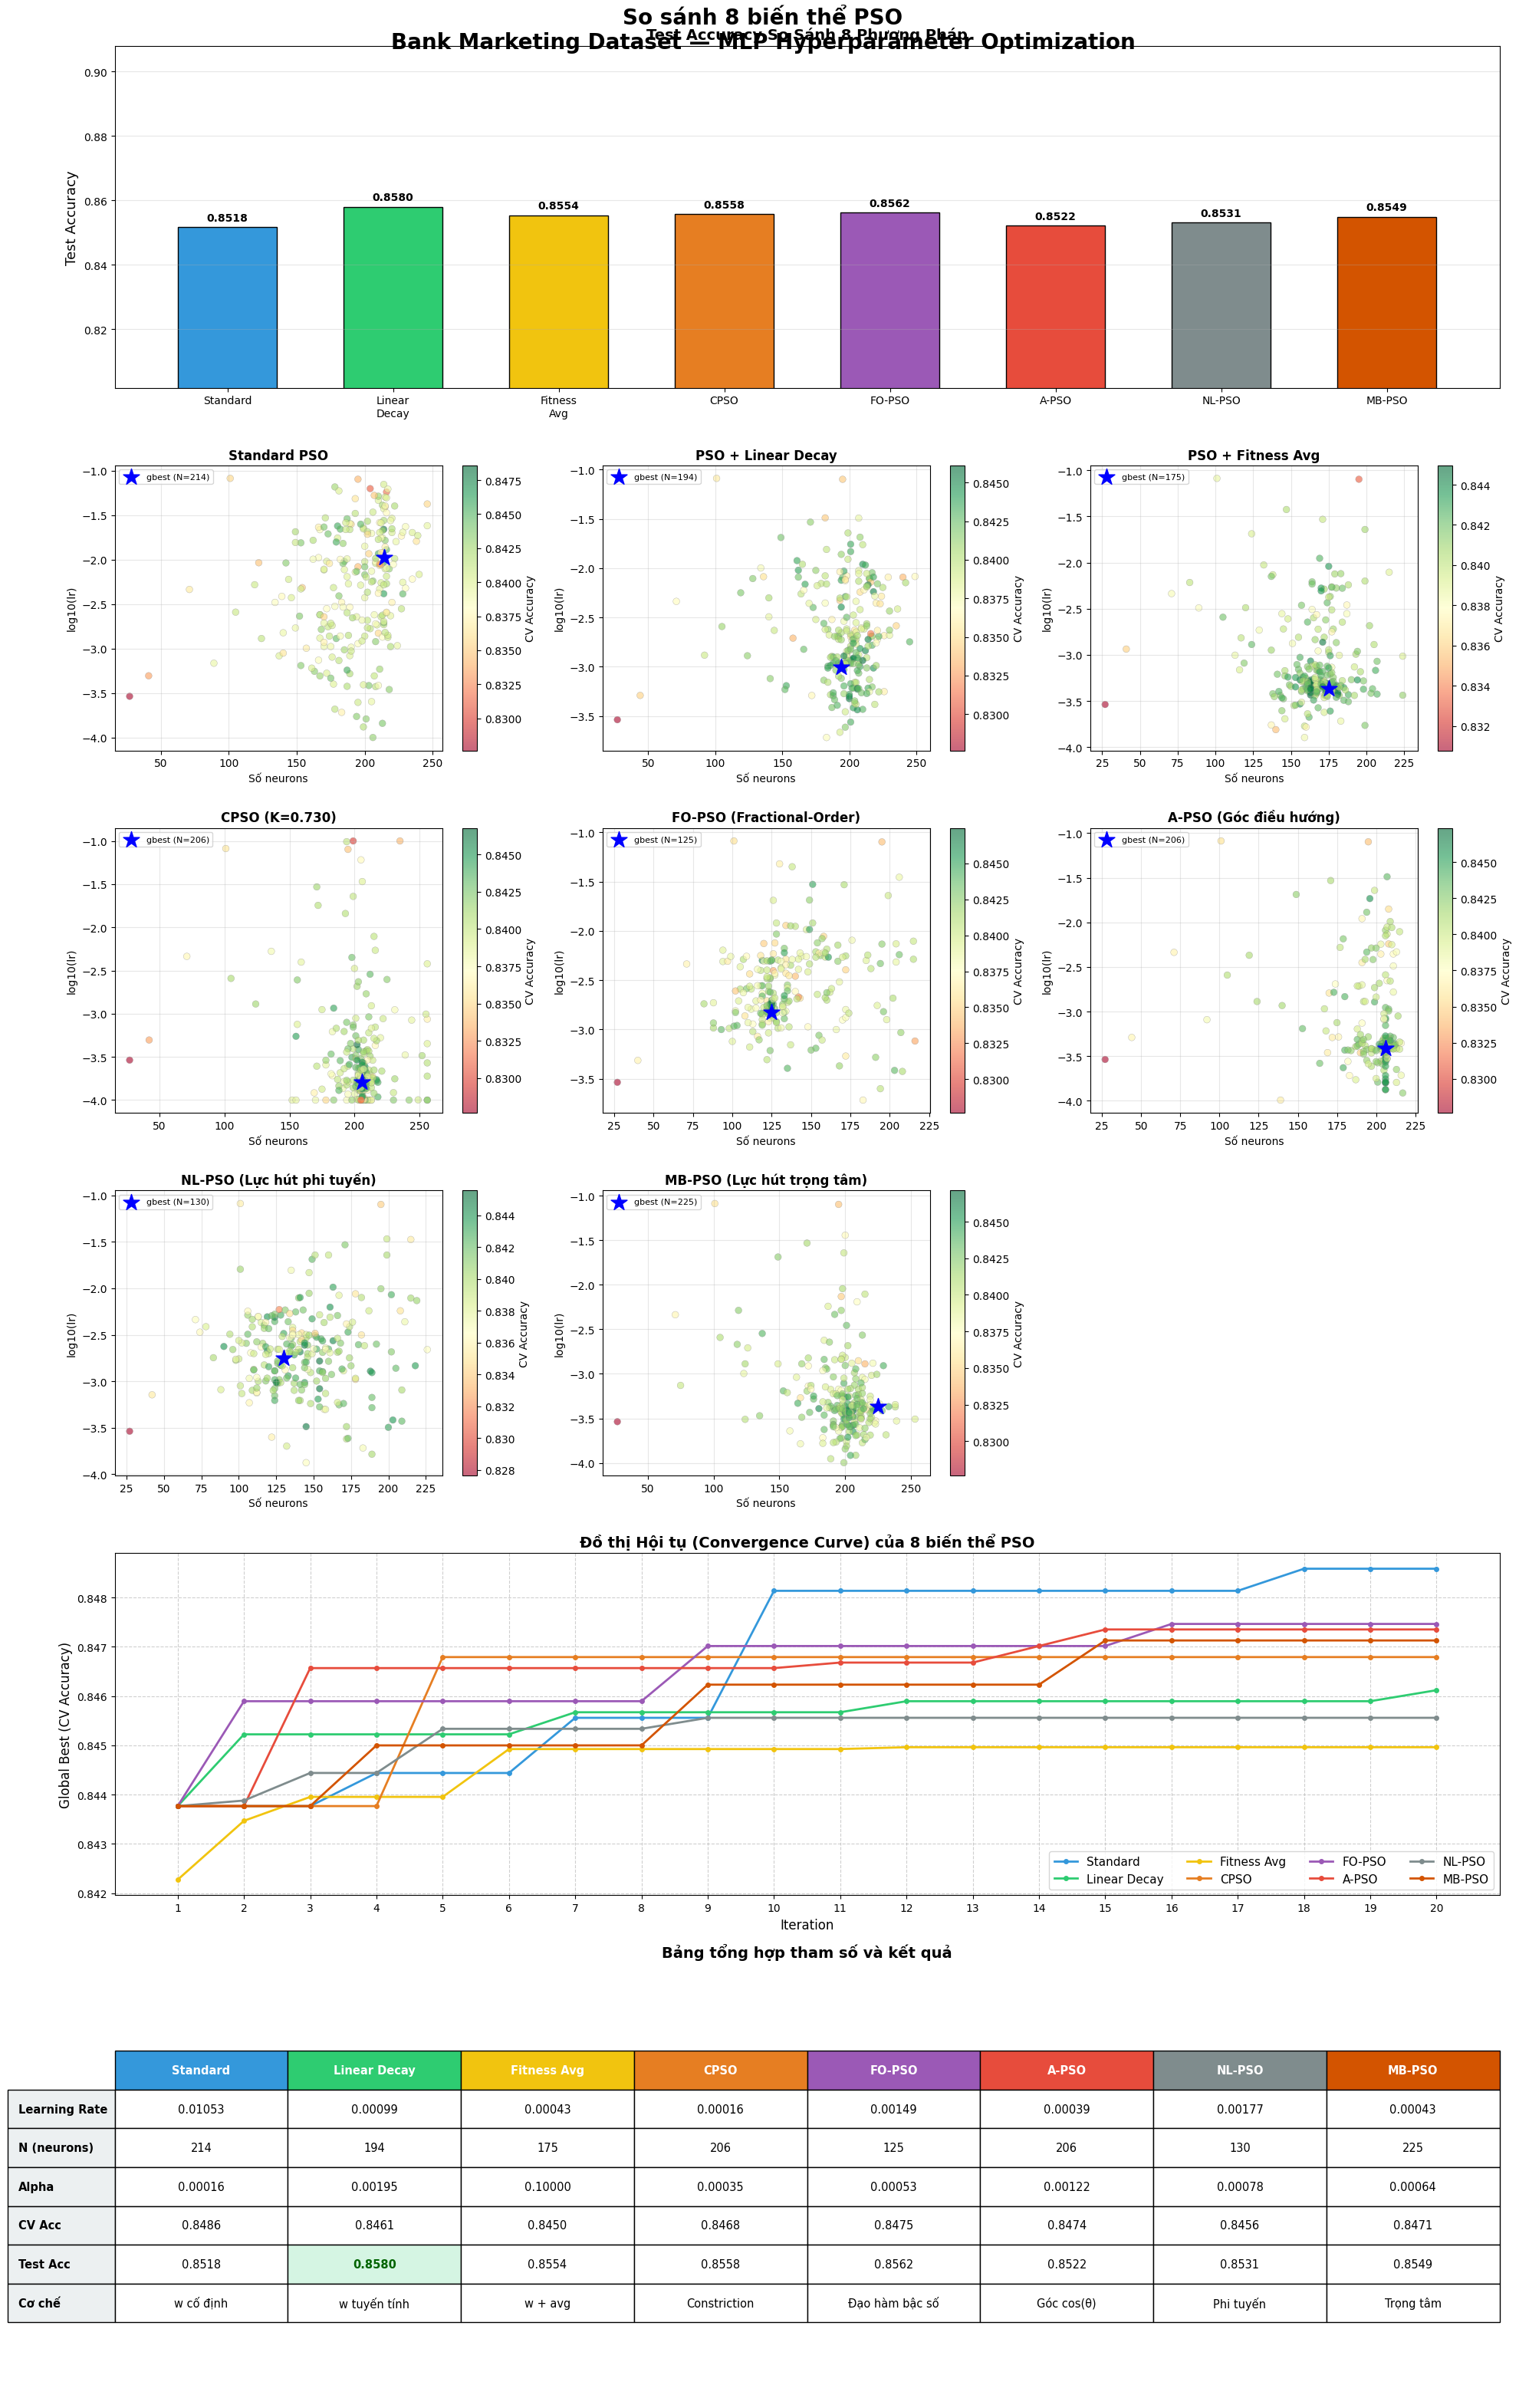

In [29]:
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np

fig = plt.figure(figsize=(20, 32)) # Tăng chiều cao lên 32 để chứa biểu đồ hội tụ
gs = gridspec.GridSpec(6, 3, figure=fig, height_ratios=[1.2, 1, 1, 1, 1.2, 1.5])
fig.suptitle('So sánh 8 biến thể PSO\nBank Marketing Dataset — MLP Hyperparameter Optimization',
             fontsize=20, fontweight='bold', y=0.98)

COLORS = {
    'Standard': '#3498db', 'Linear Decay': '#2ecc71', 'Fitness Avg': '#f1c40f',
    'CPSO': '#e67e22', 'FO-PSO': '#9b59b6', 'A-PSO': '#e74c3c',
    'NL-PSO': '#7f8c8d', 'MB-PSO': '#d35400'
}

# 1. Biểu đồ cột (Test Accuracy)
ax1 = fig.add_subplot(gs[0, :])
methods = ['Standard', 'Linear\nDecay', 'Fitness\nAvg', 'CPSO', 'FO-PSO', 'A-PSO', 'NL-PSO', 'MB-PSO']
accs    = [test_std, test_ld, test_fa, test_cp, test_fo, test_apso, test_nl, test_mb]
bars = ax1.bar(methods, accs, color=list(COLORS.values()), edgecolor='black', linewidth=1, width=0.6)
for bar, acc in zip(bars, accs):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
             f'{acc:.4f}', ha='center', fontsize=10, fontweight='bold')
ax1.set_ylabel('Test Accuracy', fontsize=13)
ax1.set_title('Test Accuracy So Sánh 8 Phương Pháp', fontsize=14, fontweight='bold')
ax1.set_ylim([min(accs)-0.05, max(accs)+0.05])
ax1.grid(True, axis='y', alpha=0.3)

def plot_scatter(ax, hist, n_best, lr_best, title):
    sc = ax.scatter(hist['n_neurons'], np.log10(hist['lr']),
                    c=hist['score'], cmap='RdYlGn', alpha=0.6, s=40, edgecolors='grey', lw=0.3)
    ax.scatter(n_best, np.log10(lr_best), c='blue', s=250, marker='*', zorder=5, label=f'gbest (N={n_best})')
    plt.colorbar(sc, ax=ax, label='CV Accuracy')
    ax.set_xlabel('Số neurons')
    ax.set_ylabel('log10(lr)')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

# 2. 8 Biểu đồ phân tán (Chia đều vào các hàng)
plot_scatter(fig.add_subplot(gs[1, 0]), hist_std, n_std, lr_std, 'Standard PSO')
plot_scatter(fig.add_subplot(gs[1, 1]), hist_ld, n_ld, lr_ld, 'PSO + Linear Decay')
plot_scatter(fig.add_subplot(gs[1, 2]), hist_fa, n_fa, lr_fa, 'PSO + Fitness Avg')

plot_scatter(fig.add_subplot(gs[2, 0]), hist_cp, n_cp, lr_cp, f'CPSO (K={K_val:.3f})')
plot_scatter(fig.add_subplot(gs[2, 1]), hist_fo, n_fo, lr_fo, 'FO-PSO (Fractional-Order)')
plot_scatter(fig.add_subplot(gs[2, 2]), hist_apso, n_apso, lr_apso, 'A-PSO (Góc điều hướng)')

plot_scatter(fig.add_subplot(gs[3, 0]), hist_nl, n_nl, lr_nl, 'NL-PSO (Lực hút phi tuyến)')
plot_scatter(fig.add_subplot(gs[3, 1]), hist_mb, n_mb, lr_mb, 'MB-PSO (Lực hút trọng tâm)')

fig.add_subplot(gs[3, 2]).axis('off')

# 3. Đồ thị hội tụ (Convergence Curve)
ax_conv = fig.add_subplot(gs[4, :])
convergences = [conv_std, conv_ld, conv_fa, conv_cp, conv_fo, conv_apso, conv_nl, conv_mb]
for conv, method, color in zip(convergences, methods, list(COLORS.values())):
    label_name = method.replace('\n', ' ')
    ax_conv.plot(range(1, len(conv)+1), conv, marker='o', markersize=4, 
                 linewidth=2, label=label_name, color=color)

ax_conv.set_xlabel('Iteration', fontsize=12)
ax_conv.set_ylabel('Global Best (CV Accuracy)', fontsize=12)
ax_conv.set_title('Đồ thị Hội tụ (Convergence Curve) của 8 biến thể PSO', fontsize=14, fontweight='bold')
ax_conv.legend(loc='lower right', ncol=4, fontsize=11)
ax_conv.grid(True, linestyle='--', alpha=0.6)
ax_conv.set_xticks(range(1, len(convergences[0])+1))

# 4. Bảng tổng hợp (Hàng cuối cùng)
ax_tbl = fig.add_subplot(gs[5, :])
ax_tbl.axis('off')

col_labels = ['Standard', 'Linear Decay', 'Fitness Avg', 'CPSO', 'FO-PSO', 'A-PSO', 'NL-PSO', 'MB-PSO']
row_labels = ['Learning Rate', 'N (neurons)', 'Alpha', 'CV Acc', 'Test Acc', 'Cơ chế']
table_data = [
    [f'{lr_std:.5f}', f'{lr_ld:.5f}', f'{lr_fa:.5f}', f'{lr_cp:.5f}', f'{lr_fo:.5f}', f'{lr_apso:.5f}', f'{lr_nl:.5f}', f'{lr_mb:.5f}'],
    [f'{n_std}',      f'{n_ld}',      f'{n_fa}',      f'{n_cp}',      f'{n_fo}',      f'{n_apso}',      f'{n_nl}',      f'{n_mb}'],
    [f'{al_std:.5f}', f'{al_ld:.5f}', f'{al_fa:.5f}', f'{al_cp:.5f}', f'{al_fo:.5f}', f'{al_apso:.5f}', f'{al_nl:.5f}', f'{al_mb:.5f}'],
    [f'{cv_std:.4f}', f'{cv_ld:.4f}', f'{cv_fa:.4f}', f'{cv_cp:.4f}', f'{cv_fo:.4f}', f'{cv_apso:.4f}', f'{cv_nl:.4f}', f'{cv_mb:.4f}'],
    [f'{test_std:.4f}',f'{test_ld:.4f}',f'{test_fa:.4f}',f'{test_cp:.4f}',f'{test_fo:.4f}',f'{test_apso:.4f}',f'{test_nl:.4f}',f'{test_mb:.4f}'],
    ['w cố định', 'w tuyến tính', 'w + avg', 'Constriction', 'Đạo hàm bậc số', 'Góc cos(θ)', 'Phi tuyến', 'Trọng tâm'],
]

tbl = ax_tbl.table(cellText=table_data, rowLabels=row_labels, colLabels=col_labels, loc='center', cellLoc='center')
tbl.auto_set_font_size(False)
# Giảm font chữ 1 chút để 8 cột vừa khít màn hình
tbl.set_fontsize(10.5) 
tbl.scale(1.0, 2.5)

for j, color in enumerate(list(COLORS.values())):
    tbl[0, j].set_facecolor(color)
    tbl[0, j].set_text_props(color='white', fontweight='bold')
for i in range(len(row_labels)):
    tbl[i+1, -1].set_facecolor('#ecf0f1')
    tbl[i+1, -1].set_text_props(fontweight='bold')

best_test = max(accs)
for j, acc in enumerate(accs):
    if acc == best_test:
        tbl[5, j].set_facecolor('#d5f5e3')
        tbl[5, j].set_text_props(fontweight='bold', color='darkgreen')

ax_tbl.set_title('Bảng tổng hợp tham số và kết quả', fontsize=14, fontweight='bold', pad=15)

plt.tight_layout()
plt.savefig('pso_variants_comparison_with_convergence.png', dpi=150, bbox_inches='tight')
plt.show()


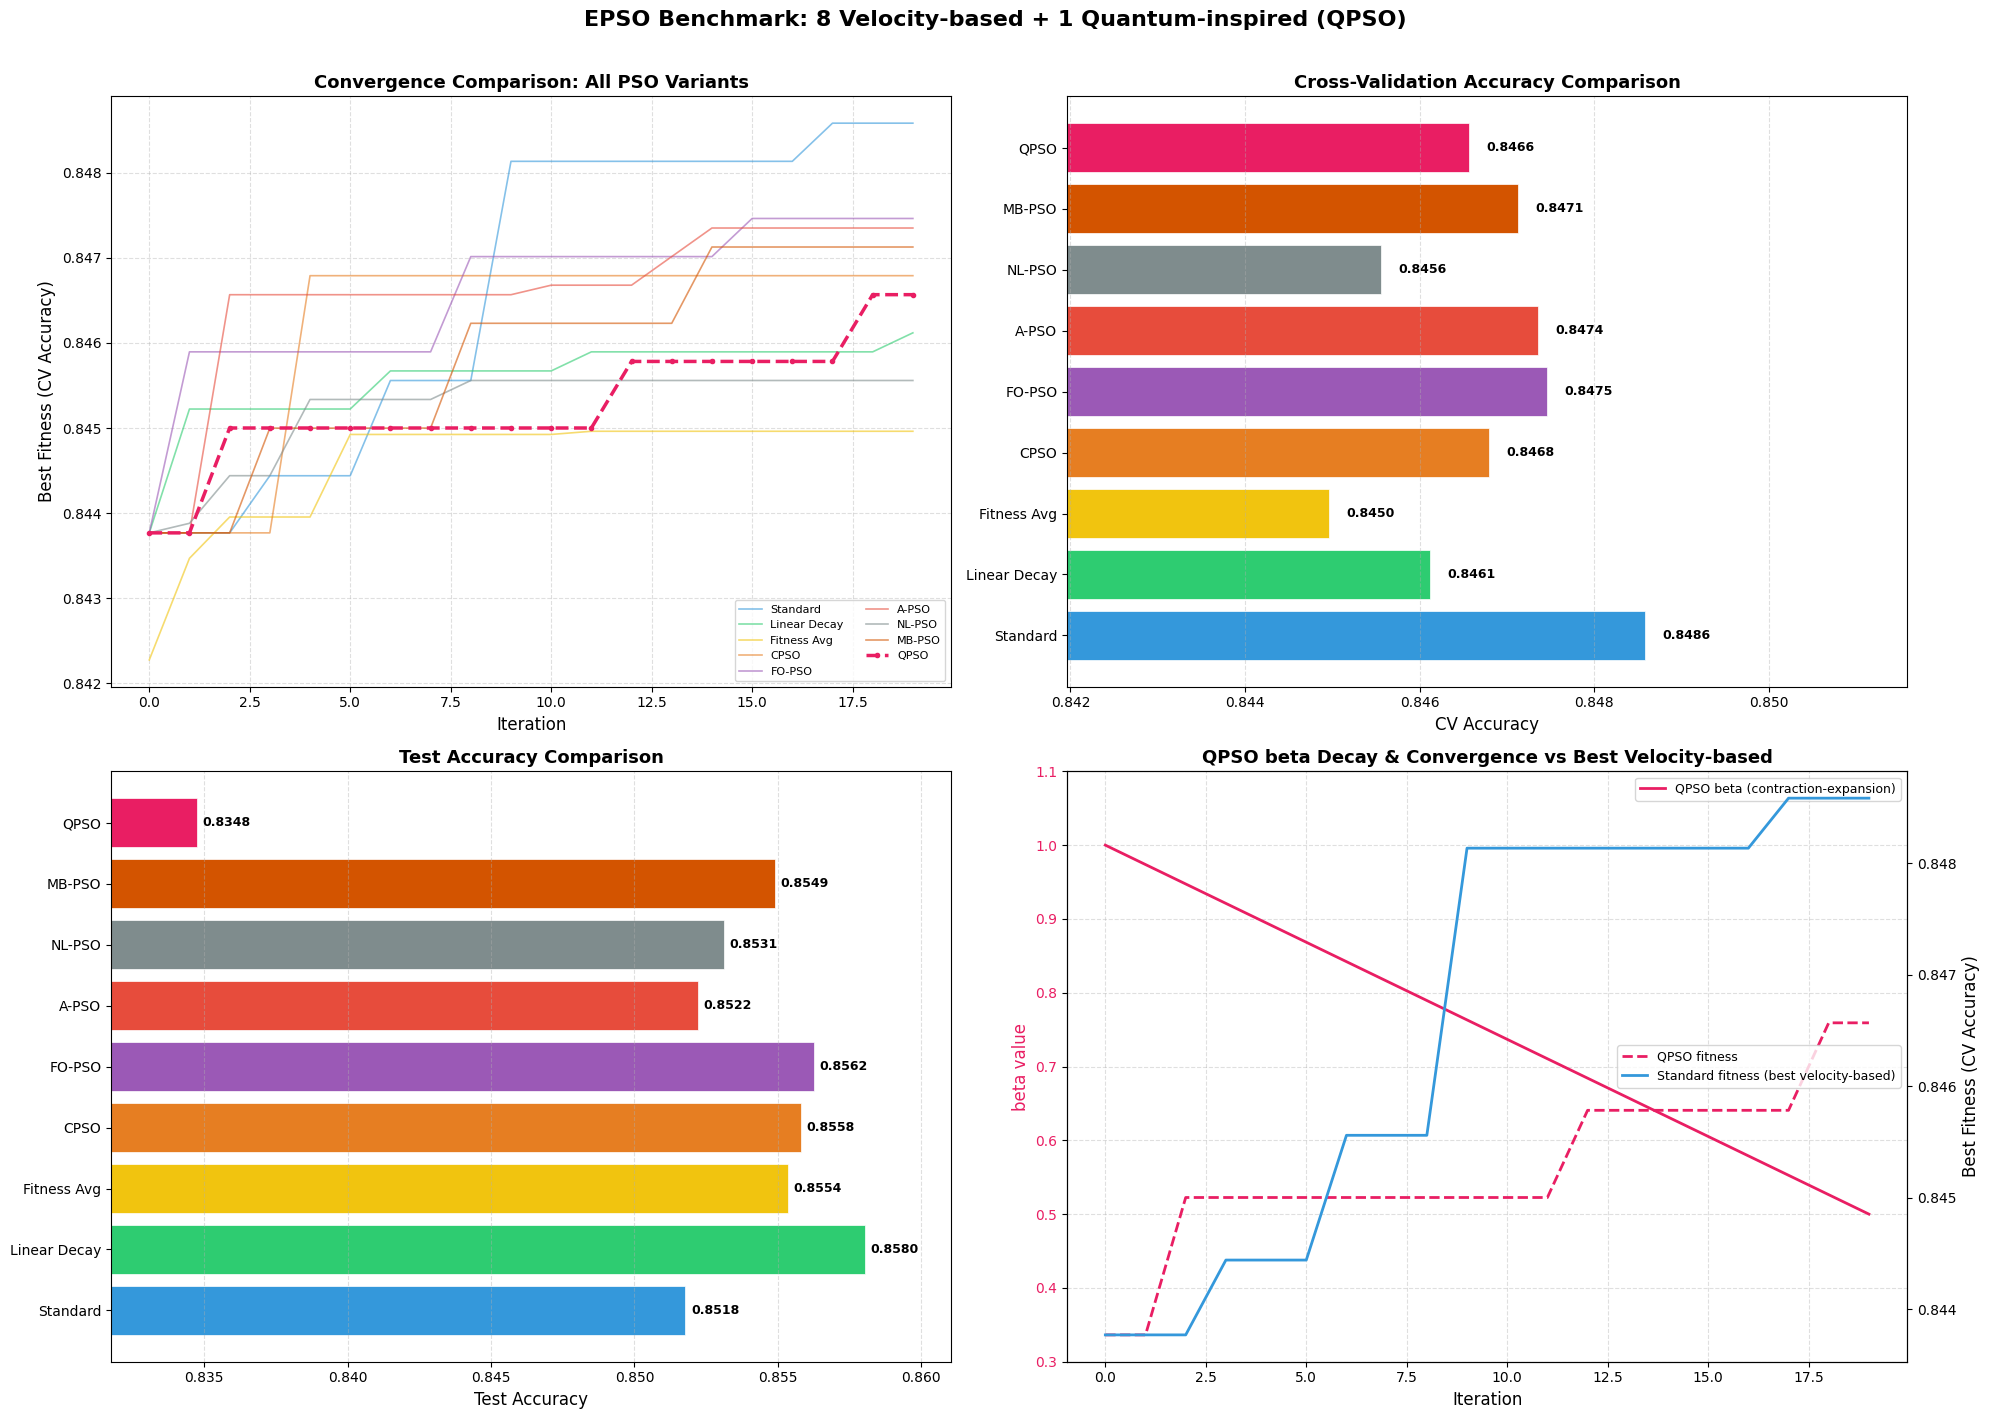

Da luu: ../results/figures/convergence_all_with_qpso.png


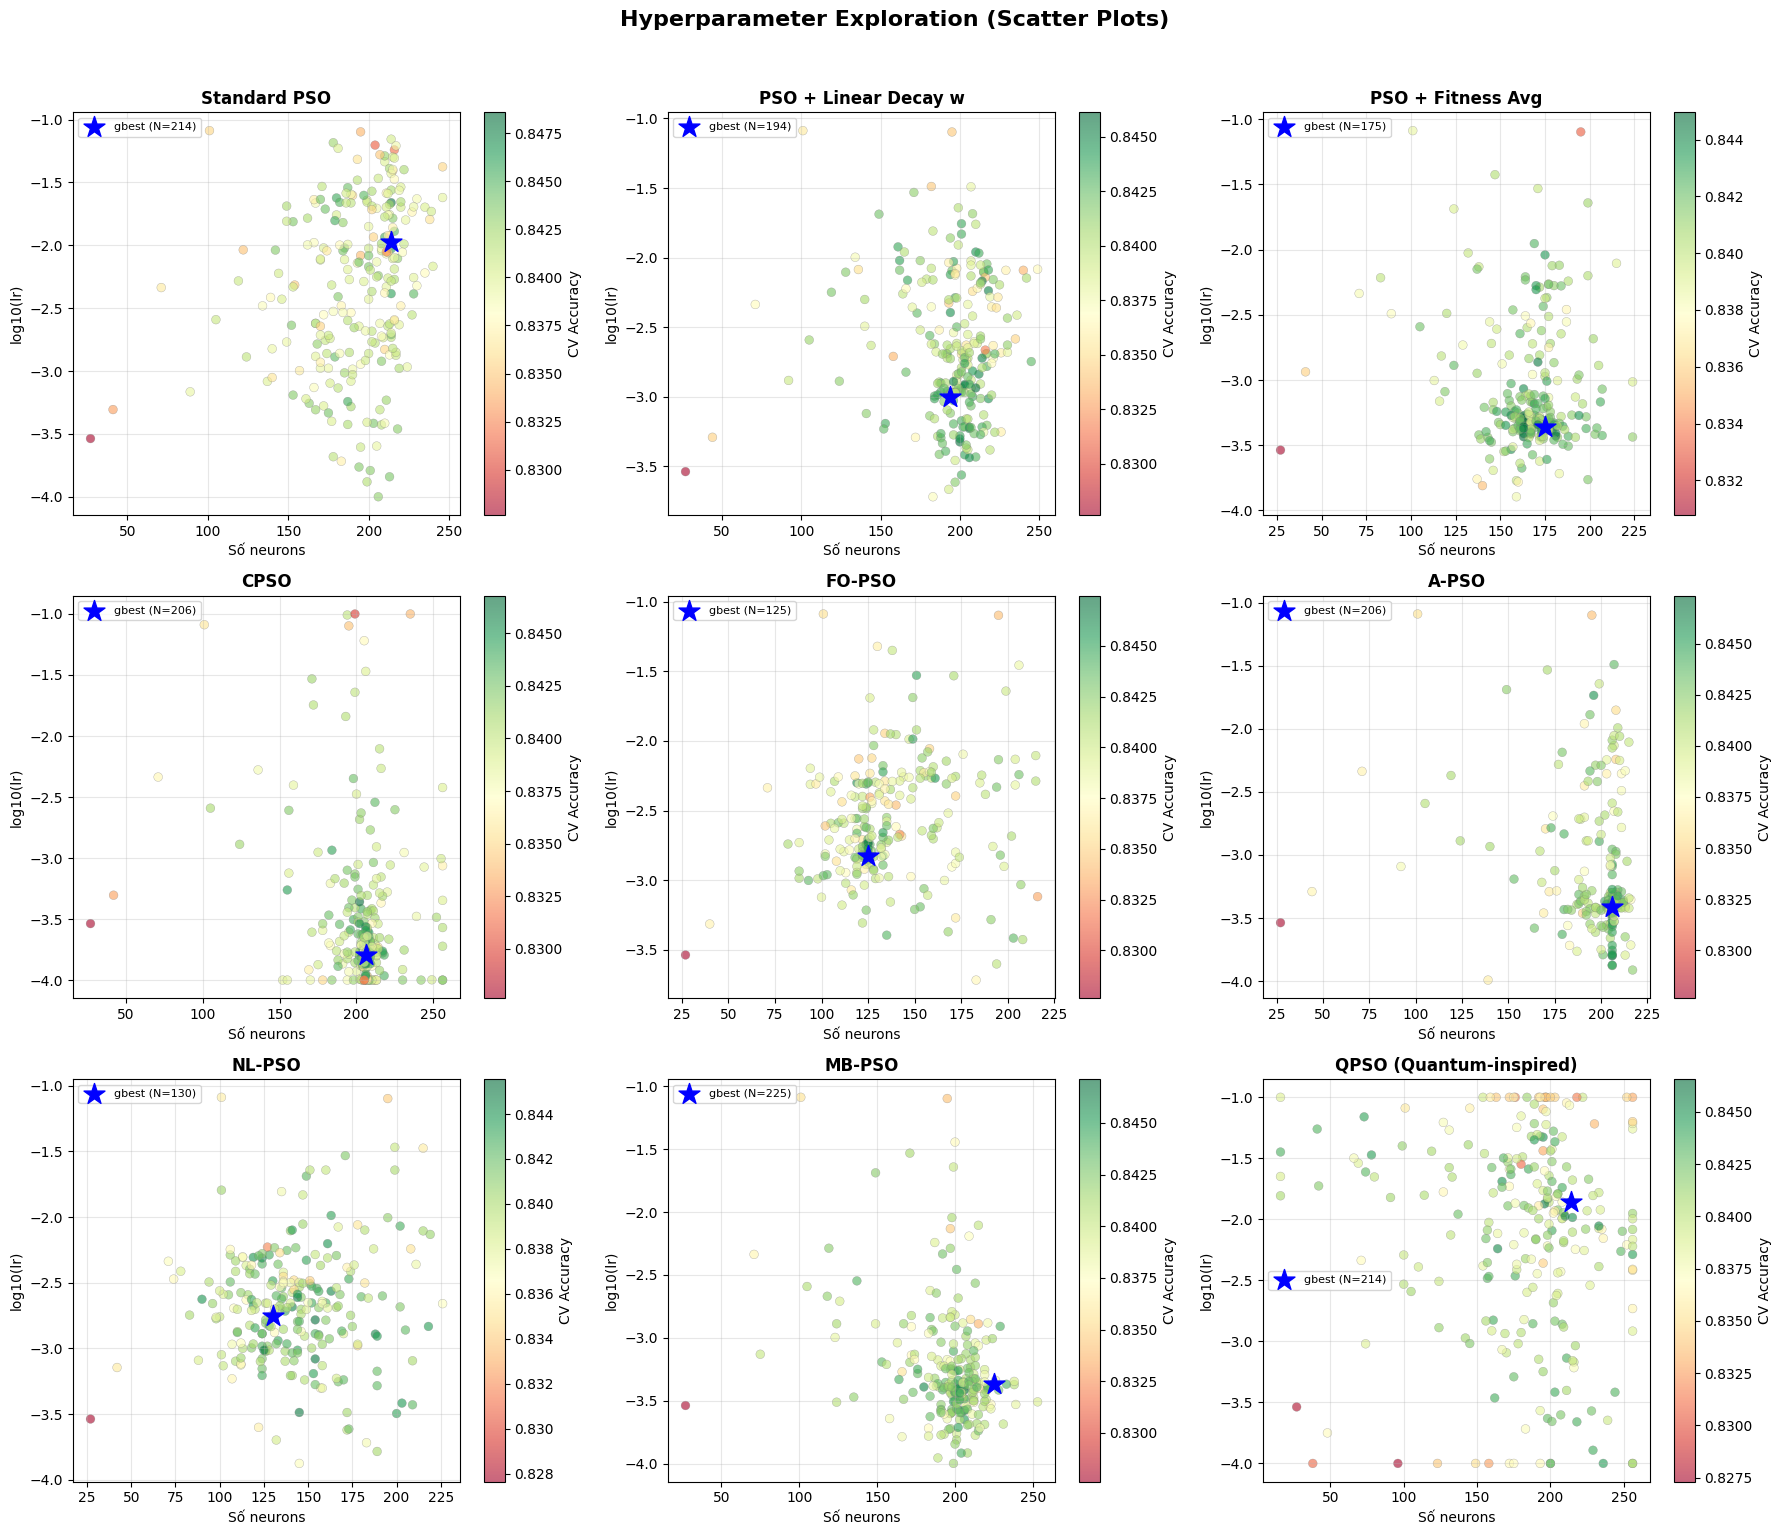

Da luu: ../results/figures/scatter_individual.png


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(20, 14))

# -- Dinh nghia du lieu cho tat ca 9 bien the --
# Cac bien the velocity-based (8 cai) - mau sac khop voi COLORS trong notebook
velocity_variants = [
    ('Standard',    conv_std,  '#3498db'),
    ('Linear Decay',conv_ld,   '#2ecc71'),
    ('Fitness Avg', conv_fa,   '#f1c40f'),
    ('CPSO',        conv_cp,   '#e67e22'),
    ('FO-PSO',      conv_fo,   '#9b59b6'),
    ('A-PSO',       conv_apso, '#e74c3c'),
    ('NL-PSO',      conv_nl,   '#7f8c8d'),
    ('MB-PSO',      conv_mb,   '#d35400'),
]
# QPSO (velocity-free) — noi bat rieng
qpso_color = '#e91e63'  # Magenta/pink noi bat

# -- 1. Bieu do hoi tu — TAT CA bien the --
ax1 = axes[0, 0]
for name, conv, color in velocity_variants:
    ax1.plot(conv, label=name, color=color, alpha=0.6, linewidth=1.2)
# QPSO ve noi bat hon (dam, day)
ax1.plot(conv_qpso, label='QPSO', color=qpso_color, linewidth=2.5, linestyle='--', marker='o', markersize=3)
ax1.set_xlabel('Iteration', fontsize=12)
ax1.set_ylabel('Best Fitness (CV Accuracy)', fontsize=12)
ax1.set_title('Convergence Comparison: All PSO Variants', fontsize=13, fontweight='bold')
ax1.legend(fontsize=8, loc='lower right', ncol=2)
ax1.grid(True, linestyle='--', alpha=0.4)

# -- 2. Bar chart — CV Accuracy --
ax2 = axes[0, 1]
all_names = [v[0] for v in velocity_variants] + ['QPSO']
all_cv = [cv_std, cv_ld, cv_fa, cv_cp, cv_fo, cv_apso, cv_nl, cv_mb, cv_qpso]
all_colors = [v[2] for v in velocity_variants] + [qpso_color]

bars = ax2.barh(all_names, all_cv, color=all_colors, edgecolor='white', linewidth=0.5)
for bar, score in zip(bars, all_cv):
    ax2.text(bar.get_width() + 0.0002, bar.get_y() + bar.get_height()/2,
             f'{score:.4f}', va='center', fontsize=9, fontweight='bold')
ax2.set_xlabel('CV Accuracy', fontsize=12)
ax2.set_title('Cross-Validation Accuracy Comparison', fontsize=13, fontweight='bold')
ax2.set_xlim(min(all_cv) - 0.003, max(all_cv) + 0.003)
ax2.grid(True, axis='x', linestyle='--', alpha=0.4)

# -- 3. Bar chart — Test Accuracy --
ax3 = axes[1, 0]
all_test = [test_std, test_ld, test_fa, test_cp, test_fo, test_apso, test_nl, test_mb, test_qpso]

bars3 = ax3.barh(all_names, all_test, color=all_colors, edgecolor='white', linewidth=0.5)
for bar, score in zip(bars3, all_test):
    ax3.text(bar.get_width() + 0.0002, bar.get_y() + bar.get_height()/2,
             f'{score:.4f}', va='center', fontsize=9, fontweight='bold')
ax3.set_xlabel('Test Accuracy', fontsize=12)
ax3.set_title('Test Accuracy Comparison', fontsize=13, fontweight='bold')
ax3.set_xlim(min(all_test) - 0.003, max(all_test) + 0.003)
ax3.grid(True, axis='x', linestyle='--', alpha=0.4)

# -- 4. QPSO beta Decay + So sanh paradigm --
ax4 = axes[1, 1]

# Ve beta decay cua QPSO
ax4_twin = ax4.twinx()
ax4.plot(beta_hist_qpso, color=qpso_color, linewidth=2, label='QPSO beta (contraction-expansion)')
ax4.set_xlabel('Iteration', fontsize=12)
ax4.set_ylabel('beta value', fontsize=12, color=qpso_color)
ax4.tick_params(axis='y', labelcolor=qpso_color)
ax4.set_ylim(0.3, 1.1)

# Ve convergence QPSO vs bien the tot nhat trong velocity-based
best_vel_name, best_vel_conv, best_vel_color = max(
    velocity_variants, key=lambda x: x[1][-1] if x[1] else 0
)
ax4_twin.plot(conv_qpso, color=qpso_color, linewidth=2, linestyle='--', label='QPSO fitness')
ax4_twin.plot(best_vel_conv, color=best_vel_color, linewidth=2, linestyle='-', label=f'{best_vel_name} fitness (best velocity-based)')
ax4_twin.set_ylabel('Best Fitness (CV Accuracy)', fontsize=12)
ax4_twin.legend(fontsize=9, loc='center right')
ax4.legend(fontsize=9, loc='upper right')
ax4.set_title('QPSO beta Decay & Convergence vs Best Velocity-based', fontsize=13, fontweight='bold')
ax4.grid(True, linestyle='--', alpha=0.4)

plt.suptitle('EPSO Benchmark: 8 Velocity-based + 1 Quantum-inspired (QPSO)',
             fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('../results/figures/convergence_all_with_qpso.png', dpi=300, bbox_inches='tight')
plt.show()
print('Da luu: ../results/figures/convergence_all_with_qpso.png')

# --- Ket thuc cell 5 ---

# ==============================================================================
# Cell 6: Bieu do phan tan (Scatter plot) cho tung bien the (3x3 grid)
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np

def plot_scatter(ax, hist, n_best, lr_best, title):
    if hist is None:
        ax.set_title(f'{title} (No data)', fontsize=12)
        ax.axis('off')
        return
        
    sc = ax.scatter(hist['n_neurons'], np.log10(hist['lr']),
                    c=hist['score'], cmap='RdYlGn', alpha=0.6, s=40, edgecolors='grey', lw=0.3)
    ax.scatter(n_best, np.log10(lr_best), c='blue', s=250, marker='*', zorder=5, label=f'gbest (N={n_best})')
    plt.colorbar(sc, ax=ax, label='CV Accuracy')
    ax.set_xlabel('Số neurons')
    ax.set_ylabel('log10(lr)')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

scatter_data = [
    (hist_std, n_std, lr_std, 'Standard PSO'),
    (hist_ld, n_ld, lr_ld, 'PSO + Linear Decay w'),
    (hist_fa, n_fa, lr_fa, 'PSO + Fitness Avg'),
    (hist_cp, n_cp, lr_cp, 'CPSO'),
    (hist_fo, n_fo, lr_fo, 'FO-PSO'),
    (hist_apso, n_apso, lr_apso, 'A-PSO'),
    (hist_nl, n_nl, lr_nl, 'NL-PSO'),
    (hist_mb, n_mb, lr_mb, 'MB-PSO'),
    (hist_qpso, n_qpso, lr_qpso, 'QPSO (Quantum-inspired)')
]

fig, axes = plt.subplots(3, 3, figsize=(18, 15))
axes = axes.flatten()

for i, (hist, n_best, lr_best, title) in enumerate(scatter_data):
    plot_scatter(axes[i], hist, n_best, lr_best, title)

plt.suptitle('Hyperparameter Exploration (Scatter Plots)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../results/figures/scatter_individual.png', dpi=300, bbox_inches='tight')
plt.show()
print('Da luu: ../results/figures/scatter_individual.png')

In [14]:
import time
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
# ==================== Q-LDPSO (Quantum + Linear Decay) ====================
# Kết hợp THẬT SỰ giữa QPSO và PSO Linear Decay:
#   - Cơ chế quantum: cập nhật vị trí bằng mbest, beta, ln(1/u) (KHÔNG có velocity)
#   - Cơ chế Linear Decay: trọng số w giảm tuyến tính từ w_start → w_end
#     để điều phối tỷ lệ trộn giữa pbest và gbest khi tính attractor point p.
#     + w lớn (đầu): p nghiêng về pbest → khám phá (exploration)
#     + w nhỏ (cuối): p nghiêng về gbest → khai thác (exploitation)
# ===========================================================================
def run_q_ldpso(X_tr, y_tr, n_particles=12, n_iter=20,
                beta_start=1.0, beta_end=0.5,
                w_start=0.9, w_end=0.4,
                seed=42):
    rng = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    positions = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    pbest_pos = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos = None
    gbest_score = -np.inf
    convergence = []
    history = []
    print(f'🟢 Q-LDPSO (Quantum + Linear Decay)')
    print(f'   beta: {beta_start} → {beta_end} | w: {w_start} → {w_end}')
    t_start = time.time()
    for it in range(n_iter):
        beta = beta_start - (beta_start - beta_end) * (it / max(n_iter - 1, 1))
        # ===== ĐÂY LÀ CƠ CHẾ LINEAR DECAY THẬT SỰ =====
        w = w_start - (w_start - w_end) * (it / max(n_iter - 1, 1))
        for i in range(n_particles):
            score = fitness_single(positions[i], X_tr, y_tr, cv_obj, seed)
            n_neur, lr, al = decode_position(positions[i])
            history.append({
                'iter': it, 'particle': i, 'score': score,
                'n_neurons': n_neur, 'lr': lr, 'alpha': al
            })
            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i] = positions[i].copy()
            if score > gbest_score:
                gbest_score = score
                gbest_pos = positions[i].copy()
        mbest = np.mean(pbest_pos, axis=0)
        for i in range(n_particles):
            phi = rng.random(size=DIM)
            # ===== ATTRACTOR POINT DÙNG w ĐỂ ĐIỀU PHỐI =====
            # w lớn → p thiên về pbest (exploration)
            # w nhỏ → p thiên về gbest (exploitation)
            p = w * phi * pbest_pos[i] + (1 - w * phi) * gbest_pos
            u = np.clip(rng.random(size=DIM), 1e-10, 1.0)
            distance = np.abs(mbest - positions[i])
            sign = np.where(rng.random(size=DIM) < 0.5, 1.0, -1.0)
            positions[i] = p + sign * beta * distance * np.log(1.0 / u)
        positions = np.clip(positions, LOW, HIGH)
        convergence.append(gbest_score)
        n_neur_best, lr_best, al_best = decode_position(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | beta={beta:.3f} | w={w:.3f} | gbest={gbest_score:.4f} | neurons={n_neur_best:3d}, lr={lr_best:.5f}')
    print(f'✅ Hoàn thành Q-LDPSO! Thời gian: {time.time()-t_start:.1f}s')
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history)

In [15]:
gbest_qld, cv_qld, conv_qld, hist_qld = run_q_ldpso(
    X_train_sc, y_train, n_particles=12, n_iter=20,
    beta_start=1.0, beta_end=0.5,
    w_start=0.9, w_end=0.4,
    seed=RANDOM_SEED
)

🟢 Q-LDPSO (Quantum + Linear Decay)
   beta: 1.0 → 0.5 | w: 0.9 → 0.4
  Iter  1/20 | beta=1.000 | w=0.900 | gbest=0.8438 | neurons=203, lr=0.00038
  Iter  2/20 | beta=0.974 | w=0.874 | gbest=0.8442 | neurons= 51, lr=0.03376
  Iter  3/20 | beta=0.947 | w=0.847 | gbest=0.8450 | neurons= 81, lr=0.03046
  Iter  4/20 | beta=0.921 | w=0.821 | gbest=0.8453 | neurons= 81, lr=0.00697
  Iter  5/20 | beta=0.895 | w=0.795 | gbest=0.8453 | neurons= 81, lr=0.00697
  Iter  6/20 | beta=0.868 | w=0.768 | gbest=0.8453 | neurons= 81, lr=0.00697
  Iter  7/20 | beta=0.842 | w=0.742 | gbest=0.8453 | neurons= 81, lr=0.00697
  Iter  8/20 | beta=0.816 | w=0.716 | gbest=0.8454 | neurons= 16, lr=0.02471
  Iter  9/20 | beta=0.789 | w=0.689 | gbest=0.8454 | neurons= 16, lr=0.02471
  Iter 10/20 | beta=0.763 | w=0.663 | gbest=0.8454 | neurons= 16, lr=0.02471
  Iter 11/20 | beta=0.737 | w=0.637 | gbest=0.8462 | neurons= 38, lr=0.01615
  Iter 12/20 | beta=0.711 | w=0.611 | gbest=0.8462 | neurons= 38, lr=0.01615
  Iter 

In [ ]:
import joblib, os

# Lưu kết quả
os.makedirs('../results/checkpoints', exist_ok=True)
joblib.dump({
    'gbest_pos':    gbest_qld,
    'cv_score':     cv_qld,
    'convergence':  conv_qld,
    'history':      hist_qld
}, '../results/checkpoints/q_ldpso.pkl')
print('✅ Đã lưu kết quả Q-LDPSO vào: ../results/checkpoints/q_ldpso.pkl')



✅ Đã lưu kết quả Q-LDPSO vào: ../results/checkpoints/q_ldpso.pkl

🔄 Đang tải và đánh giá Q-LDPSO trên tập Test...
  Q-LDPSO (Quantum Linear Decay) Test Accuracy = 0.8424


In [31]:
# Đánh giá Test
print('\n🔄 Đang tải và đánh giá Q-LDPSO trên tập Test...')
qldpso_data = joblib.load('../results/checkpoints/q_ldpso.pkl')
gbest_qld_loaded = qldpso_data['gbest_pos']
conv_qld = qldpso_data['convergence']
hist_qld = qldpso_data['history']

n_qld, lr_qld, al_qld = decode_position(gbest_qld_loaded)
mlp_qld, test_qld = train_and_evaluate(
    n_qld, lr_qld, al_qld, 
    X_train_sc, y_train, X_test_sc, y_test, 
    RANDOM_SEED, 'Q-LDPSO (Quantum Linear Decay)',
    cv_score=qldpso_data.get('cv_score')
)


🔄 Đang tải và đánh giá Q-LDPSO trên tập Test...
  Q-LDPSO (Quantum Linear Decay) Test Accuracy = 0.8424


In [ ]:
def run_q_mbpso(X_tr, y_tr, n_particles=12, n_iter=20, beta_start=1.0, beta_end=0.5, top_k=3, seed=42):
    rng = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    positions = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    pbest_pos = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos = None
    gbest_score = -np.inf
    convergence = []
    history = [] 
    print(f'🌀 Q-MBPSO (Quantum MB-PSO) | mbest = Top-{top_k} pbest')
    t_start = time.time()
    for it in range(n_iter):
        beta = beta_start - (beta_start - beta_end) * (it / max(n_iter - 1, 1))
        for i in range(n_particles):
            score = fitness_single(positions[i], X_tr, y_tr, cv_obj, seed)
            
            n_neur, lr, al = decode_position(positions[i])
            history.append({
                'iter': it, 'particle': i, 'score': score,
                'n_neurons': n_neur, 'lr': lr, 'alpha': al
            })
            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i] = positions[i].copy()
            if score > gbest_score:
                gbest_score = score
                gbest_pos = positions[i].copy()
        top_k_idx = np.argsort(pbest_score)[-top_k:]
        mbest_topk = np.mean(pbest_pos[top_k_idx], axis=0)
        
        for i in range(n_particles):
            phi = rng.random(size=DIM)
            p = phi * pbest_pos[i] + (1 - phi) * gbest_pos
            u = np.clip(rng.random(size=DIM), 1e-10, 1.0)
            
            distance = np.abs(mbest_topk - positions[i])
            sign = np.where(rng.random(size=DIM) < 0.5, 1.0, -1.0)
            
            positions[i] = p + sign * beta * distance * np.log(1.0 / u)
        positions = np.clip(positions, LOW, HIGH)
        convergence.append(gbest_score)
        
        # --- ĐÃ THÊM DÒNG IN TIẾN ĐỘ Ở ĐÂY ---
        n_neur_best, lr_best, al_best = decode_position(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | beta={beta:.3f} | gbest={gbest_score:.4f} | neurons={n_neur_best:3d}, lr={lr_best:.5f}')
        
    print(f'✅ Hoàn thành Q-MBPSO! Thời gian: {time.time()-t_start:.1f}s')
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history)

In [ ]:
# Chạy huấn luyện Q-MBPSO
gbest_qmb, cv_qmb, conv_qmb, hist_qmb = run_q_mbpso(
    X_train_sc, y_train, n_particles=12, n_iter=20, top_k=3, beta_start=1.0, beta_end=0.5, seed=RANDOM_SEED
)

🌀 Q-MBPSO (Quantum MB-PSO) | mbest = Top-3 pbest
  Iter  1/20 | beta=1.000 | gbest=0.8438 | neurons=203, lr=0.00038
  Iter  2/20 | beta=0.974 | gbest=0.8465 | neurons=188, lr=0.00098
  Iter  3/20 | beta=0.947 | gbest=0.8465 | neurons=188, lr=0.00098
  Iter  4/20 | beta=0.921 | gbest=0.8465 | neurons=188, lr=0.00098
  Iter  5/20 | beta=0.895 | gbest=0.8465 | neurons=188, lr=0.00098
  Iter  6/20 | beta=0.868 | gbest=0.8465 | neurons=188, lr=0.00098
  Iter  7/20 | beta=0.842 | gbest=0.8465 | neurons=188, lr=0.00098
  Iter  8/20 | beta=0.816 | gbest=0.8465 | neurons=188, lr=0.00098
  Iter  9/20 | beta=0.789 | gbest=0.8465 | neurons=188, lr=0.00098
  Iter 10/20 | beta=0.763 | gbest=0.8465 | neurons=188, lr=0.00098
  Iter 11/20 | beta=0.737 | gbest=0.8465 | neurons=188, lr=0.00098
  Iter 12/20 | beta=0.711 | gbest=0.8465 | neurons=188, lr=0.00098
  Iter 13/20 | beta=0.684 | gbest=0.8465 | neurons=188, lr=0.00098
  Iter 14/20 | beta=0.658 | gbest=0.8465 | neurons=188, lr=0.00098
  Iter 15/20 

In [ ]:
import joblib, os
# Lưu kết quả
os.makedirs('../results/checkpoints', exist_ok=True)
joblib.dump({
    'gbest_pos':    gbest_qmb,
    'cv_score':     cv_qmb,
    'convergence':  conv_qmb,
    'history':      hist_qmb
}, '../results/checkpoints/q_mbpso.pkl')
print('✅ Đã lưu kết quả Q-MBPSO vào: ../results/checkpoints/q_mbpso.pkl')

In [32]:
# Đánh giá Test
print('\n🔄 Đang tải và đánh giá Q-MBPSO trên tập Test...')
qmbpso_data = joblib.load('../results/checkpoints/q_mbpso.pkl')
gbest_qmb_loaded = qmbpso_data['gbest_pos']
conv_qmb = qmbpso_data['convergence']
hist_qmb = qmbpso_data['history']
n_qmb, lr_qmb, al_qmb = decode_position(gbest_qmb_loaded)
mlp_qmb, test_qmb = train_and_evaluate(
    n_qmb, lr_qmb, al_qmb, 
    X_train_sc, y_train, X_test_sc, y_test, 
    RANDOM_SEED, 'Q-MBPSO (Quantum Top-K MB)',
    cv_score=qmbpso_data.get('cv_score')
)


🔄 Đang tải và đánh giá Q-MBPSO trên tập Test...
  Q-MBPSO (Quantum Top-K MB)     Test Accuracy = 0.8562


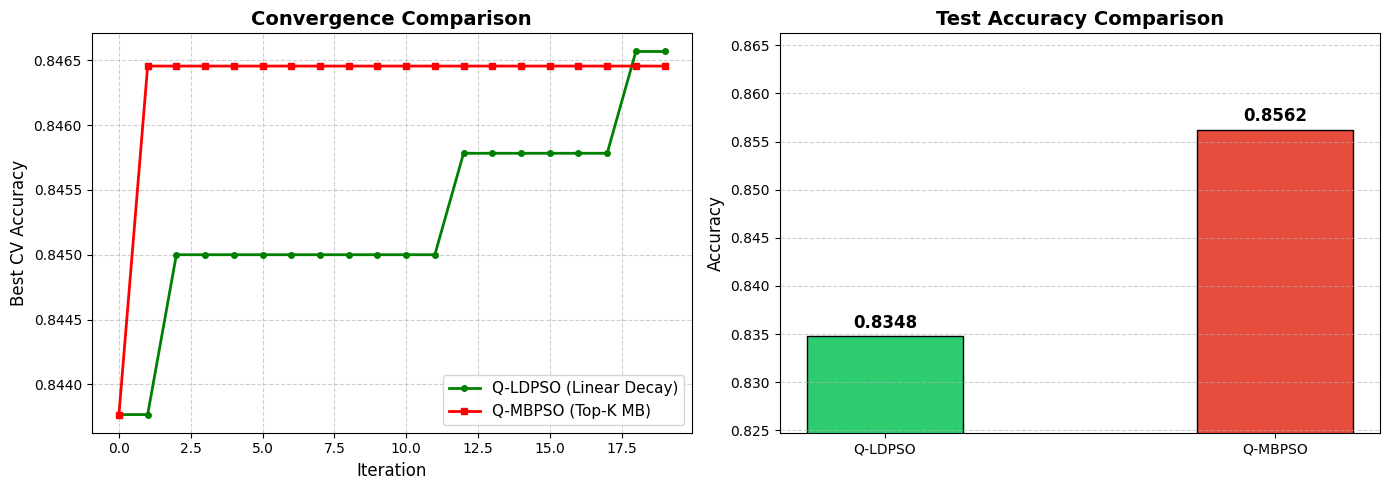

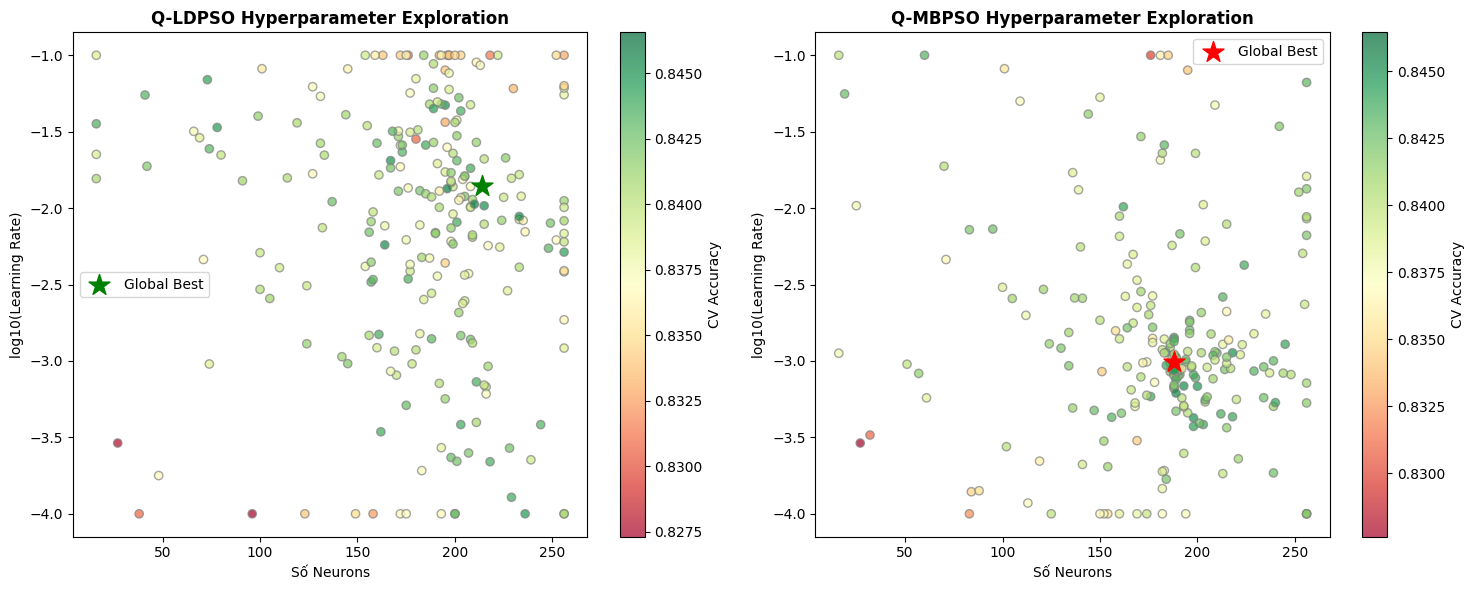

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


fig1, axes1 = plt.subplots(1, 2, figsize=(14, 5))

# 1. Biểu đồ hội tụ
axes1[0].plot(conv_qld, label='Q-LDPSO (Linear Decay)', color='green', linewidth=2, marker='o', markersize=4)
axes1[0].plot(conv_qmb, label='Q-MBPSO (Top-K MB)', color='red', linewidth=2, marker='s', markersize=4)
axes1[0].set_title('Convergence Comparison', fontsize=14, fontweight='bold')
axes1[0].set_xlabel('Iteration', fontsize=12)
axes1[0].set_ylabel('Best CV Accuracy', fontsize=12)
axes1[0].legend(fontsize=11)
axes1[0].grid(True, linestyle='--', alpha=0.6)

# 2. Biểu đồ Test Accuracy
labels = ['Q-LDPSO', 'Q-MBPSO']
test_scores = [test_qld, test_qmb]
colors = ['#2ecc71', '#e74c3c']

bars = axes1[1].bar(labels, test_scores, color=colors, edgecolor='black', width=0.4)
axes1[1].set_title('Test Accuracy Comparison', fontsize=14, fontweight='bold')
axes1[1].set_ylabel('Accuracy', fontsize=12)

for bar, score in zip(bars, test_scores):
    axes1[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.0005, 
                 f'{score:.4f}', ha='center', va='bottom', fontsize=12, fontweight='bold')

axes1[1].set_ylim(min(test_scores) - 0.01, max(test_scores) + 0.01)
axes1[1].grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# ============================================================================
# PHẦN 2: BIỂU ĐỒ PHÂN TÁN (SCATTER PLOT)
# ============================================================================
fig2, axes2 = plt.subplots(1, 2, figsize=(15, 6))

# Plot cho Q-LDPSO
sc1 = axes2[0].scatter(hist_qld['n_neurons'], np.log10(hist_qld['lr']),
                      c=hist_qld['score'], cmap='RdYlGn', alpha=0.7, edgecolors='grey')
axes2[0].scatter(n_qld, np.log10(lr_qld), c='green', s=250, marker='*', label='Global Best')
axes2[0].set_title('Q-LDPSO Hyperparameter Exploration', fontweight='bold')
axes2[0].set_xlabel('Số Neurons')
axes2[0].set_ylabel('log10(Learning Rate)')
axes2[0].legend()
plt.colorbar(sc1, ax=axes2[0], label='CV Accuracy')

# Plot cho Q-MBPSO
sc2 = axes2[1].scatter(hist_qmb['n_neurons'], np.log10(hist_qmb['lr']),
                      c=hist_qmb['score'], cmap='RdYlGn', alpha=0.7, edgecolors='grey')
axes2[1].scatter(n_qmb, np.log10(lr_qmb), c='red', s=250, marker='*', label='Global Best')
axes2[1].set_title('Q-MBPSO Hyperparameter Exploration', fontweight='bold')
axes2[1].set_xlabel('Số Neurons')
axes2[1].set_ylabel('log10(Learning Rate)')
axes2[1].legend()
plt.colorbar(sc2, ax=axes2[1], label='CV Accuracy')

plt.tight_layout()
plt.show()



## 🚀 Ý tưởng 3: Mở rộng không gian tìm kiếm (5D Space)

Thay vì 3D (n_neurons, lr, alpha), không gian được mở rộng thành 5D:
- `n_neurons`
- `lr`
- `alpha`
- `n_layers`
- `batch_size`

In [38]:
LOW_5D  = np.array([16,  -4.0, -5.0, 1, 16])
HIGH_5D = np.array([256, -1.0, -1.0, 4, 128])
DIM_5D  = 5

def decode_position_5d(x):
    n_neurons = int(np.clip(round(x[0]), 16, 256))
    lr        = float(10 ** np.clip(x[1], -4.0, -1.0))
    alpha     = float(10 ** np.clip(x[2], -5.0, -1.0))
    n_layers  = int(np.clip(round(x[3]), 1, 4))
    batch_size = int(np.clip(round(x[4]), 16, 128))
    return n_neurons, lr, alpha, n_layers, batch_size

def fitness_single_5d(x, X_tr, y_tr, cv_obj, seed):
    n_neurons, lr, alpha, n_layers, batch_size = decode_position_5d(x)
    hidden_layer_sizes = tuple([n_neurons] * n_layers)
    model = MLPClassifier(
        hidden_layer_sizes=hidden_layer_sizes,
        activation='relu',
        learning_rate_init=lr,
        alpha=alpha,
        batch_size=batch_size,
        max_iter=500,
        random_state=seed,
        early_stopping=True,
        n_iter_no_change=15
    )
    scores = cross_val_score(model, X_tr, y_tr, cv=cv_obj,
                             scoring='accuracy', n_jobs=-1)
    return scores.mean()

### 1. Train PSO trên không gian 5D

In [8]:
def run_pso_5d(X_tr, y_tr, n_particles=12, n_iter=20, w=0.7, n1=1.5, n2=1.5, v_max_ratio=0.2, seed=42):
    rng    = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    v_max  = v_max_ratio * (HIGH_5D - LOW_5D)

    positions  = rng.uniform(LOW_5D, HIGH_5D, size=(n_particles, DIM_5D))
    velocities = rng.uniform(-(HIGH_5D-LOW_5D)*0.1, (HIGH_5D-LOW_5D)*0.1, size=(n_particles, DIM_5D))
    pbest_pos   = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos   = None
    gbest_score = -np.inf
    convergence = []
    history     = []

    print(f'🚀 Standard PSO (5D) | w={w} | n1={n1}, n2={n2}')
    print(f'   {n_particles} particles × {n_iter} iterations')
    print('─'*60)
    import time
    t_start = time.time()

    for it in range(n_iter):
        for i in range(n_particles):
            score = fitness_single_5d(positions[i], X_tr, y_tr, cv_obj, seed)
            n, lr, al, nl, bs = decode_position_5d(positions[i])
            history.append({'iter': it, 'particle': i, 'score': score,
                            'n_neurons': n, 'lr': lr, 'alpha': al, 'n_layers': nl, 'batch_size': bs})
            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i]   = positions[i].copy()
            if score > gbest_score:
                gbest_score = score
                gbest_pos   = positions[i].copy()

        r1 = rng.random(size=(n_particles, DIM_5D))
        r2 = rng.random(size=(n_particles, DIM_5D))
        velocities = (
            w  * velocities
            + n1 * r1 * (pbest_pos - positions)
            + n2 * r2 * (gbest_pos - positions)
        )
        velocities = np.clip(velocities, -v_max, v_max)
        positions  = np.clip(positions + velocities, LOW_5D, HIGH_5D)

        convergence.append(gbest_score)
        n, lr, al, nl, bs = decode_position_5d(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | gbest={gbest_score:.4f} | '
              f'neurons={n}, lr={lr:.5f}, alpha={al:.5f}, layers={nl}, bs={bs}')

    print('─'*60)
    print(f'✅ Hoàn thành! Thời gian: {time.time()-t_start:.1f}s')
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history)

gbest_5d, cv_5d, conv_5d, hist_5d = run_pso_5d(
    X_train_sc, y_train,
    n_particles=12, n_iter=20,
    seed=RANDOM_SEED
)
n_5d, lr_5d, al_5d, nl_5d, bs_5d = decode_position_5d(gbest_5d)
print(f'\n  Best 5D: neurons={n_5d}, lr={lr_5d:.5f}, alpha={al_5d:.5f}, layers={nl_5d}, bs={bs_5d}')
print(f'  CV Accuracy: {cv_5d:.4f}')

🚀 Standard PSO (5D) | w=0.7 | n1=1.5, n2=1.5
   12 particles × 20 iterations
────────────────────────────────────────────────────────────
  Iter  1/20 | gbest=0.8446 | neurons=202, lr=0.00207, alpha=0.02719, layers=3, bs=27
  Iter  2/20 | gbest=0.8446 | neurons=202, lr=0.00207, alpha=0.02719, layers=3, bs=27
  Iter  3/20 | gbest=0.8478 | neurons=201, lr=0.00410, alpha=0.02271, layers=3, bs=27
  Iter  4/20 | gbest=0.8478 | neurons=201, lr=0.00410, alpha=0.02271, layers=3, bs=27
  Iter  5/20 | gbest=0.8478 | neurons=201, lr=0.00410, alpha=0.02271, layers=3, bs=27
  Iter  6/20 | gbest=0.8478 | neurons=201, lr=0.00410, alpha=0.02271, layers=3, bs=27
  Iter  7/20 | gbest=0.8478 | neurons=201, lr=0.00410, alpha=0.02271, layers=3, bs=27
  Iter  8/20 | gbest=0.8500 | neurons=203, lr=0.00385, alpha=0.01762, layers=3, bs=28
  Iter  9/20 | gbest=0.8500 | neurons=203, lr=0.00385, alpha=0.01762, layers=3, bs=28
  Iter 10/20 | gbest=0.8500 | neurons=203, lr=0.00385, alpha=0.01762, layers=3, bs=28
  

### 2. Lưu kết quả Train

In [ ]:
import joblib, os
os.makedirs('../results/checkpoints', exist_ok=True)
joblib.dump({
    'gbest_pos': gbest_5d,
    'cv_score':  cv_5d,
    'convergence': conv_5d,
    'history':   hist_5d
}, '../results/checkpoints/pso_5d.pkl')
print('✅ Đã lưu kết quả train 5D tại: ../results/checkpoints/pso_5d.pkl')

### 3. Test trên tập dữ liệu

In [42]:
print('\n🔄 Đang đánh giá mô hình tốt nhất (5D) trên tập Test...')
pso_5d_data = joblib.load('../results/checkpoints/pso_5d.pkl')
gbest_5d_loaded = pso_5d_data['gbest_pos']
n_5d, lr_5d, al_5d, nl_5d, bs_5d = decode_position_5d(gbest_5d_loaded)
hidden_layer_sizes = tuple([n_5d] * nl_5d)

model_5d = MLPClassifier(
    hidden_layer_sizes=hidden_layer_sizes,
    activation='relu',
    learning_rate_init=lr_5d,
    alpha=al_5d,
    batch_size=bs_5d,
    max_iter=500,
    random_state=RANDOM_SEED,
    early_stopping=True,
    n_iter_no_change=15
)

model_5d.fit(X_train_sc, y_train)
y_pred_5d = model_5d.predict(X_test_sc)
test_acc_5d = np.mean(y_pred_5d == y_test)

print(f'✅ Test Accuracy (5D): {test_acc_5d:.4f}')
print('\nBáo cáo phân loại:')
print(classification_report(y_test, y_pred_5d))

# Lưu vào file CSV chung
save_test_accuracy(
    '5D PSO', test_acc_5d,
    {'n_neurons': n_5d, 'lr': round(float(lr_5d), 5), 'alpha': round(float(al_5d), 5), 'n_layers': nl_5d, 'batch_size': bs_5d},
    cv_score=pso_5d_data.get('cv_score')
)


🔄 Đang đánh giá mô hình tốt nhất (5D) trên tập Test...
✅ Test Accuracy (5D): 0.8513

Báo cáo phân loại:
              precision    recall  f1-score   support

           0       0.90      0.81      0.85      1175
           1       0.81      0.90      0.85      1058

    accuracy                           0.85      2233
   macro avg       0.85      0.85      0.85      2233
weighted avg       0.86      0.85      0.85      2233



### 4. Visualization (Biểu đồ phân tán, Hội tụ, Cột Accuracy)

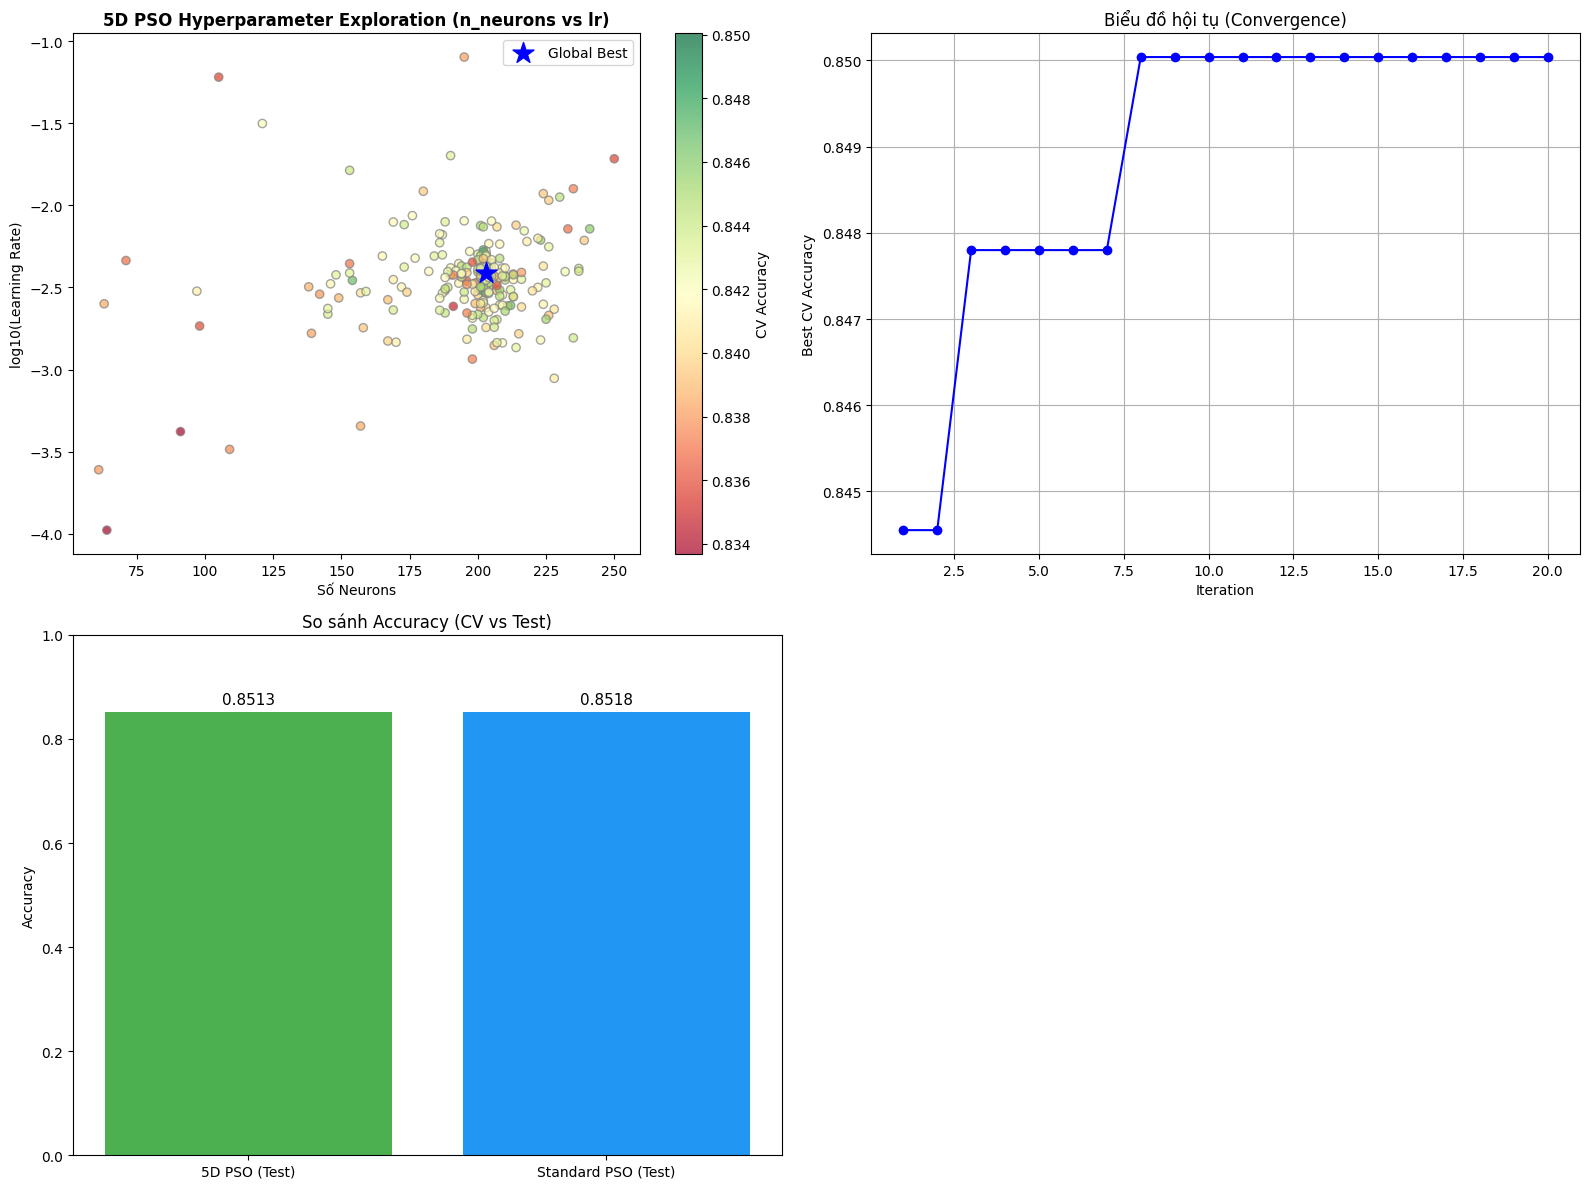

In [18]:
# Lấy lịch sử để vẽ biểu đồ
history_df = pd.DataFrame(pso_5d_data['history'])
convergence = pso_5d_data['convergence']

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()
axes[3].axis('off')

# 1. Biểu đồ phân tán (Scatter plot)
scatter = axes[0].scatter(history_df['n_neurons'], np.log10(history_df['lr']), c=history_df['score'], cmap='RdYlGn', alpha=0.7, edgecolors='grey')
axes[0].scatter(n_5d, np.log10(lr_5d), c='blue', s=250, marker='*', zorder=5, label='Global Best')
axes[0].set_xlabel('Số Neurons')
axes[0].set_ylabel('log10(Learning Rate)')
axes[0].set_title('5D PSO Hyperparameter Exploration (n_neurons vs lr)', fontweight='bold')
axes[0].legend()
fig.colorbar(scatter, ax=axes[0], label='CV Accuracy')

# 2. Biểu đồ hội tụ
axes[1].plot(range(1, len(convergence) + 1), convergence, marker='o', linestyle='-', color='b')
axes[1].set_xlabel('Iteration')
axes[1].set_ylabel('Best CV Accuracy')
axes[1].set_title('Biểu đồ hội tụ (Convergence)')
axes[1].grid(True)

# 3. Biểu đồ cột Accuracy (So sánh CV và Test)
labels = ['5D PSO (Test)', 'Standard PSO (Test)']
acc_values = [test_acc_5d, test_std]
bars = axes[2].bar(labels, acc_values, color=['#4CAF50', '#2196F3'])
axes[2].set_ylim(0, 1.0)
axes[2].set_ylabel('Accuracy')
axes[2].set_title('So sánh Accuracy (CV vs Test)')
for bar in bars:
    yval = bar.get_height()
    axes[2].text(bar.get_x() + bar.get_width()/2, yval + 0.01, f'{yval:.4f}', ha='center', va='bottom', fontsize=11)

plt.tight_layout()
plt.show()


## 🚀 Ý tưởng 4: Adaptive β (Non-linear Beta Decay cho QPSO)
Thay vì giảm $\beta$ tuyến tính, ta sử dụng **Cosine Annealing** để tạo sự chuyển đổi mượt mà giữa quá trình khám phá (Exploration) và khai thác (Exploitation).

In [15]:
import math
import time

def run_qpso_nonlinear(
    X_tr, y_tr,
    n_particles=12, n_iter=20,
    beta_start=1.0,
    beta_end=0.5,
    seed=42
):
    rng    = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

    positions   = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    pbest_pos   = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos   = None
    gbest_score = -np.inf
    convergence = []
    history     = []
    beta_history = []

    print(f'QPSO (Non-linear Cosine Decay) | beta: {beta_start} -> {beta_end}')
    print(f'   {n_particles} particles x {n_iter} iterations')
    print('-' * 60)
    t_start = time.time()

    for it in range(n_iter):
        # --- Cosine Annealing Beta ---
        beta = beta_end + 0.5 * (beta_start - beta_end) * (1 + math.cos(math.pi * it / n_iter))
        beta_history.append(beta)

        for i in range(n_particles):
            score = fitness_single(positions[i], X_tr, y_tr, cv_obj, seed)
            n_neur, lr, al = decode_position(positions[i])
            history.append({
                'iter': it, 'particle': i, 'score': score,
                'n_neurons': n_neur, 'lr': lr, 'alpha': al, 'beta': beta
            })

            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i]   = positions[i].copy()

            if score > gbest_score:
                gbest_score = score
                gbest_pos   = positions[i].copy()

        mbest = np.mean(pbest_pos, axis=0)

        for i in range(n_particles):
            phi = rng.random(size=DIM)
            p = phi * pbest_pos[i] + (1 - phi) * gbest_pos
            u = rng.random(size=DIM)
            u = np.clip(u, 1e-10, 1.0)
            distance = np.abs(mbest - positions[i])
            sign = np.where(rng.random(size=DIM) < 0.5, 1.0, -1.0)
            positions[i] = p + sign * beta * distance * np.log(1.0 / u)

        positions = np.clip(positions, LOW, HIGH)
        convergence.append(gbest_score)
        n_neur, lr, al = decode_position(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | beta={beta:.3f} | gbest={gbest_score:.4f} | neurons={n_neur:3d}, lr={lr:.5f}, alpha={al:.6f} | [{time.time()-t_start:.0f}s]')

    print('-' * 60)
    print(f'Hoan thanh QPSO Non-linear! Thoi gian: {time.time()-t_start:.1f}s')
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history), beta_history

gbest_qpso_nl, cv_qpso_nl, conv_qpso_nl, hist_qpso_nl, beta_hist_qpso_nl = run_qpso_nonlinear(
    X_train_sc, y_train,
    n_particles=12, n_iter=20,
    beta_start=1.0, beta_end=0.5,
    seed=RANDOM_SEED
)
n_qpso_nl, lr_qpso_nl, al_qpso_nl = decode_position(gbest_qpso_nl)
print(f'\nBest QPSO (Non-linear): neurons={n_qpso_nl}, lr={lr_qpso_nl:.5f}, alpha={al_qpso_nl:.6f}')
print(f'CV Accuracy: {cv_qpso_nl:.4f}')


QPSO (Non-linear Cosine Decay) | beta: 1.0 -> 0.5
   12 particles x 20 iterations
------------------------------------------------------------
  Iter  1/20 | beta=1.000 | gbest=0.8438 | neurons=203, lr=0.00038, alpha=0.000736 | [49s]
  Iter  2/20 | beta=0.997 | gbest=0.8438 | neurons=203, lr=0.00038, alpha=0.000736 | [105s]
  Iter  3/20 | beta=0.988 | gbest=0.8438 | neurons=203, lr=0.00038, alpha=0.000736 | [166s]
  Iter  4/20 | beta=0.973 | gbest=0.8466 | neurons=202, lr=0.00026, alpha=0.100000 | [218s]
  Iter  5/20 | beta=0.952 | gbest=0.8466 | neurons=202, lr=0.00026, alpha=0.100000 | [270s]
  Iter  6/20 | beta=0.927 | gbest=0.8470 | neurons=243, lr=0.00643, alpha=0.100000 | [330s]
  Iter  7/20 | beta=0.897 | gbest=0.8470 | neurons=243, lr=0.00643, alpha=0.100000 | [385s]
  Iter  8/20 | beta=0.863 | gbest=0.8470 | neurons=243, lr=0.00643, alpha=0.100000 | [443s]
  Iter  9/20 | beta=0.827 | gbest=0.8470 | neurons=243, lr=0.00643, alpha=0.100000 | [504s]
  Iter 10/20 | beta=0.789 | gb

In [16]:
### 2. Lưu kết quả Train
import joblib

joblib.dump({
    'gbest_pos':  gbest_qpso_nl,
    'cv_score':   cv_qpso_nl,
    'convergence': conv_qpso_nl,
    'history':    hist_qpso_nl.to_dict('records'),
    'beta_history': beta_hist_qpso_nl
}, '../results/checkpoints/qpso_nonlinear.pkl')

print('✅ Đã lưu: ../results/checkpoints/qpso_nonlinear.pkl')


✅ Đã lưu: ../results/checkpoints/qpso_nonlinear.pkl


In [33]:
### 3. Test trên tập dữ liệu
pso_qpso_nl_data = joblib.load('../results/checkpoints/qpso_nonlinear.pkl')
gbest_qpso_nl_loaded = pso_qpso_nl_data['gbest_pos']
n_nl_best, lr_nl_best, al_nl_best = decode_position(gbest_qpso_nl_loaded)

model_qpso_nl = MLPClassifier(
    hidden_layer_sizes=(n_nl_best, n_nl_best),
    activation='relu',
    learning_rate_init=lr_nl_best,
    alpha=al_nl_best,
    max_iter=500,
    random_state=RANDOM_SEED,
    early_stopping=True,
    n_iter_no_change=15
)

model_qpso_nl.fit(X_train_sc, y_train)
y_pred_qpso_nl = model_qpso_nl.predict(X_test_sc)
test_acc_qpso_nl = np.mean(y_pred_qpso_nl == y_test)

print('Đánh giá QPSO Non-linear trên tập Test:')
print(f'Test Accuracy: {test_acc_qpso_nl:.4f}')
print(classification_report(y_test, y_pred_qpso_nl))

# Lưu vào file CSV chung
save_test_accuracy('Non-linear Beta QPSO', test_acc_qpso_nl, (n_nl_best, lr_nl_best, al_nl_best), cv_score=pso_qpso_nl_data.get('cv_score'))

Đánh giá QPSO Non-linear trên tập Test:
Test Accuracy: 0.8536
              precision    recall  f1-score   support

           0       0.89      0.82      0.86      1175
           1       0.82      0.89      0.85      1058

    accuracy                           0.85      2233
   macro avg       0.85      0.86      0.85      2233
weighted avg       0.86      0.85      0.85      2233



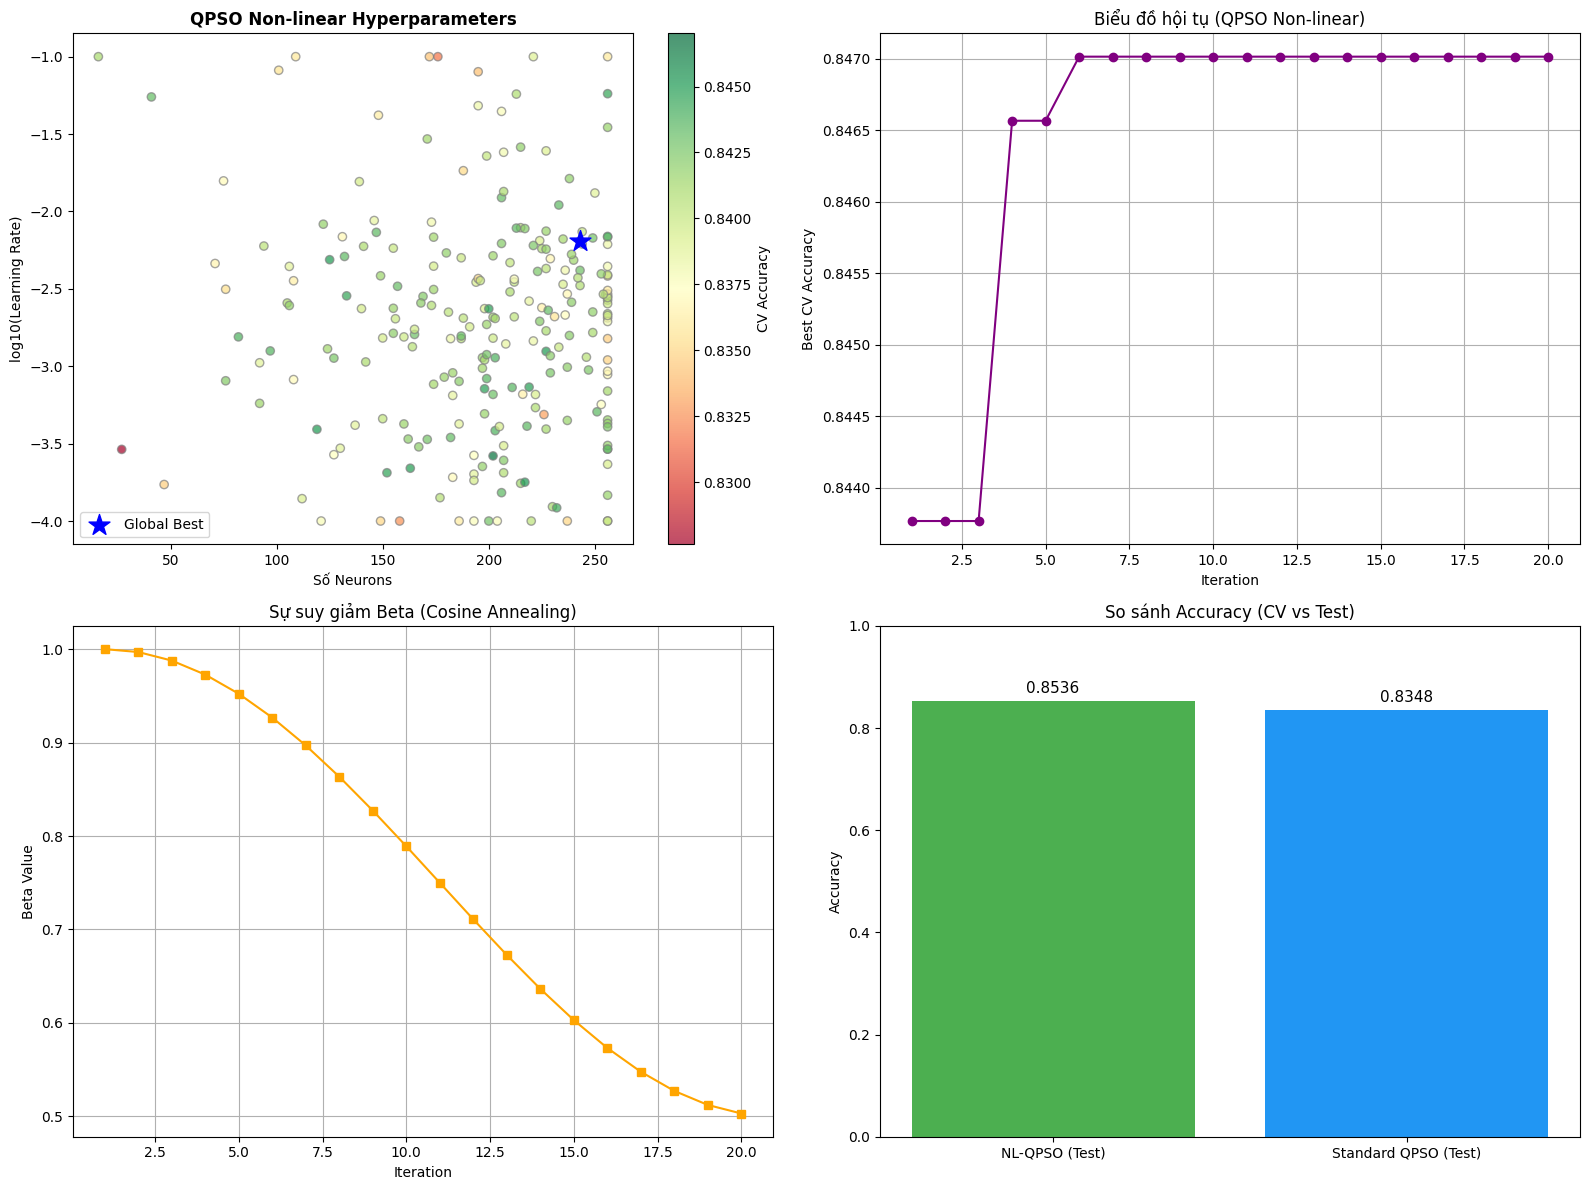

In [12]:
### 4. Visualization (Biểu đồ phân tán, Hội tụ, Cột Accuracy, và Beta curve)
history_df_nl = pd.DataFrame(pso_qpso_nl_data['history'])
convergence_nl = pso_qpso_nl_data['convergence']
beta_history_nl = pso_qpso_nl_data['beta_history']

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

# 1. Biểu đồ phân tán (Scatter plot)
scatter = axes[0].scatter(history_df_nl['n_neurons'], np.log10(history_df_nl['lr']), c=history_df_nl['score'], cmap='RdYlGn', alpha=0.7, edgecolors='grey')
axes[0].scatter(n_nl_best, np.log10(lr_nl_best), c='blue', s=250, marker='*', zorder=5, label='Global Best')
axes[0].set_xlabel('Số Neurons')
axes[0].set_ylabel('log10(Learning Rate)')
axes[0].set_title('QPSO Non-linear Hyperparameters', fontweight='bold')
axes[0].legend()
fig.colorbar(scatter, ax=axes[0], label='CV Accuracy')

# 2. Biểu đồ hội tụ (Convergence)
axes[1].plot(range(1, len(convergence_nl) + 1), convergence_nl, marker='o', linestyle='-', color='purple')
axes[1].set_xlabel('Iteration')
axes[1].set_ylabel('Best CV Accuracy')
axes[1].set_title('Biểu đồ hội tụ (QPSO Non-linear)')
axes[1].grid(True)

# 3. Biểu đồ thay đổi Beta (Cosine Annealing)
axes[2].plot(range(1, len(beta_history_nl) + 1), beta_history_nl, marker='s', linestyle='-', color='orange')
axes[2].set_xlabel('Iteration')
axes[2].set_ylabel('Beta Value')
axes[2].set_title('Sự suy giảm Beta (Cosine Annealing)')
axes[2].grid(True)

# 4. Biểu đồ cột Accuracy (So sánh CV và Test)
labels = ['NL-QPSO (Test)', 'Standard QPSO (Test)']
acc_values = [test_acc_qpso_nl, test_qpso]
bars = axes[3].bar(labels, acc_values, color=['#4CAF50', '#2196F3'])
axes[3].set_ylim(0, 1.0)
axes[3].set_ylabel('Accuracy')
axes[3].set_title('So sánh Accuracy (CV vs Test)')
for bar in bars:
    yval = bar.get_height()
    axes[3].text(bar.get_x() + bar.get_width()/2, yval + 0.01, f'{yval:.4f}', ha='center', va='bottom', fontsize=11)

plt.tight_layout()
plt.show()


## 🚀 Ý tưởng 4: Fitness-adaptive β (Thích ứng theo điểm số cho QPSO)
Thay vì giảm $\beta$ một cách máy móc, chúng ta để $\beta$ thay đổi dựa trên tình trạng hội tụ:
- Nếu `gbest` không được cải thiện trong `stagnation_limit` vòng lặp liên tiếp, bầy đàn có thể đang mắc kẹt ở local optima. Thuật toán sẽ ngay lập tức đẩy $\beta$ lên cao (`beta_start`) để khám phá lại (Exploration).
- Nếu `gbest` liên tục cải thiện, $\beta$ sẽ giảm dần để tập trung khai thác điểm sáng đó (Exploitation).

In [19]:
import time

def run_qpso_adaptive(
    X_tr, y_tr,
    n_particles=12, n_iter=20,
    beta_start=1.0,
    beta_end=0.5,
    stagnation_limit=3,
    seed=42
):
    rng    = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

    positions   = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    pbest_pos   = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos   = None
    gbest_score = -np.inf
    convergence = []
    history     = []
    beta_history = []
    
    stagnation_counter = 0
    beta = beta_start # Khởi tạo beta ban đầu

    print(f'QPSO (Fitness-Adaptive Beta) | beta: {beta_start} -> {beta_end}')
    print(f'   {n_particles} particles x {n_iter} iterations | stagnation_limit={stagnation_limit}')
    print('-' * 60)
    t_start = time.time()

    for it in range(n_iter):
        improved = False
        for i in range(n_particles):
            score = fitness_single(positions[i], X_tr, y_tr, cv_obj, seed)
            n_neur, lr, al = decode_position(positions[i])
            history.append({
                'iter': it, 'particle': i, 'score': score,
                'n_neurons': n_neur, 'lr': lr, 'alpha': al, 'beta': beta
            })

            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i]   = positions[i].copy()

            if score > gbest_score:
                gbest_score = score
                gbest_pos   = positions[i].copy()
                improved = True

        # Lưu beta hiện tại của vòng lặp này
        beta_history.append(beta)

        # Logic điều chỉnh beta (Adaptive)
        if improved:
            stagnation_counter = 0
            beta = max(beta_end, beta * 0.9) # Giảm beta để tập trung khai thác
        else:
            stagnation_counter += 1
            beta = max(beta_end, beta * 0.9) # Vẫn giảm nhẹ
            
            # Nếu bế tắc quá số vòng lặp cho phép
            if stagnation_counter >= stagnation_limit:
                beta = beta_start # Bơm beta lên cao để khám phá lại
                stagnation_counter = 0

        mbest = np.mean(pbest_pos, axis=0)

        for i in range(n_particles):
            phi = rng.random(size=DIM)
            p = phi * pbest_pos[i] + (1 - phi) * gbest_pos
            u = rng.random(size=DIM)
            u = np.clip(u, 1e-10, 1.0)
            distance = np.abs(mbest - positions[i])
            sign = np.where(rng.random(size=DIM) < 0.5, 1.0, -1.0)
            positions[i] = p + sign * beta * distance * np.log(1.0 / u)

        positions = np.clip(positions, LOW, HIGH)
        convergence.append(gbest_score)
        n_neur, lr, al = decode_position(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | beta={beta_history[-1]:.3f} (stagnation={stagnation_counter}) | gbest={gbest_score:.4f} | neurons={n_neur:3d}, lr={lr:.5f}, alpha={al:.6f} | [{time.time()-t_start:.0f}s]')

    print('-' * 60)
    print(f'Hoan thanh QPSO Adaptive! Thoi gian: {time.time()-t_start:.1f}s')
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history), beta_history

gbest_qpso_ad, cv_qpso_ad, conv_qpso_ad, hist_qpso_ad, beta_hist_qpso_ad = run_qpso_adaptive(
    X_train_sc, y_train,
    n_particles=12, n_iter=20,
    beta_start=1.0, beta_end=0.5, stagnation_limit=3,
    seed=RANDOM_SEED
)
n_qpso_ad, lr_qpso_ad, al_qpso_ad = decode_position(gbest_qpso_ad)
print(f'\nBest QPSO (Adaptive): neurons={n_qpso_ad}, lr={lr_qpso_ad:.5f}, alpha={al_qpso_ad:.6f}')
print(f'CV Accuracy: {cv_qpso_ad:.4f}')


QPSO (Fitness-Adaptive Beta) | beta: 1.0 -> 0.5
   12 particles x 20 iterations | stagnation_limit=3
------------------------------------------------------------
  Iter  1/20 | beta=1.000 (stagnation=0) | gbest=0.8438 | neurons=203, lr=0.00038, alpha=0.000736 | [89s]
  Iter  2/20 | beta=0.900 (stagnation=0) | gbest=0.8444 | neurons=156, lr=0.00286, alpha=0.100000 | [218s]
  Iter  3/20 | beta=0.810 (stagnation=1) | gbest=0.8444 | neurons=156, lr=0.00286, alpha=0.100000 | [313s]
  Iter  4/20 | beta=0.729 (stagnation=0) | gbest=0.8466 | neurons=214, lr=0.00346, alpha=0.100000 | [398s]
  Iter  5/20 | beta=0.656 (stagnation=1) | gbest=0.8466 | neurons=214, lr=0.00346, alpha=0.100000 | [496s]
  Iter  6/20 | beta=0.590 (stagnation=2) | gbest=0.8466 | neurons=214, lr=0.00346, alpha=0.100000 | [586s]
  Iter  7/20 | beta=0.531 (stagnation=0) | gbest=0.8466 | neurons=214, lr=0.00346, alpha=0.100000 | [681s]
  Iter  8/20 | beta=1.000 (stagnation=1) | gbest=0.8466 | neurons=214, lr=0.00346, alpha=0

In [20]:
### 2. Lưu kết quả Train
import joblib

joblib.dump({
    'gbest_pos':  gbest_qpso_ad,
    'cv_score':   cv_qpso_ad,
    'convergence': conv_qpso_ad,
    'history':    hist_qpso_ad.to_dict('records'),
    'beta_history': beta_hist_qpso_ad
}, '../results/checkpoints/qpso_adaptive.pkl')

print('✅ Đã lưu: ../results/checkpoints/qpso_adaptive.pkl')


✅ Đã lưu: ../results/checkpoints/qpso_adaptive.pkl


In [34]:
### 3. Test trên tập dữ liệu
pso_qpso_ad_data = joblib.load('../results/checkpoints/qpso_adaptive.pkl')
gbest_qpso_ad_loaded = pso_qpso_ad_data['gbest_pos']
n_ad_best, lr_ad_best, al_ad_best = decode_position(gbest_qpso_ad_loaded)

model_qpso_ad = MLPClassifier(
    hidden_layer_sizes=(n_ad_best, n_ad_best),
    activation='relu',
    learning_rate_init=lr_ad_best,
    alpha=al_ad_best,
    max_iter=500,
    random_state=RANDOM_SEED,
    early_stopping=True,
    n_iter_no_change=15
)

model_qpso_ad.fit(X_train_sc, y_train)
y_pred_qpso_ad = model_qpso_ad.predict(X_test_sc)
test_acc_qpso_ad = np.mean(y_pred_qpso_ad == y_test)

print('Đánh giá QPSO Adaptive trên tập Test:')
print(f'Test Accuracy: {test_acc_qpso_ad:.4f}')
print(classification_report(y_test, y_pred_qpso_ad))

# Lưu vào file CSV chung
save_test_accuracy('Fitness-adaptive Beta QPSO', test_acc_qpso_ad, (n_ad_best, lr_ad_best, al_ad_best), cv_score=pso_qpso_ad_data.get('cv_score'))

Đánh giá QPSO Adaptive trên tập Test:
Test Accuracy: 0.8509
              precision    recall  f1-score   support

           0       0.90      0.81      0.85      1175
           1       0.81      0.90      0.85      1058

    accuracy                           0.85      2233
   macro avg       0.85      0.85      0.85      2233
weighted avg       0.86      0.85      0.85      2233



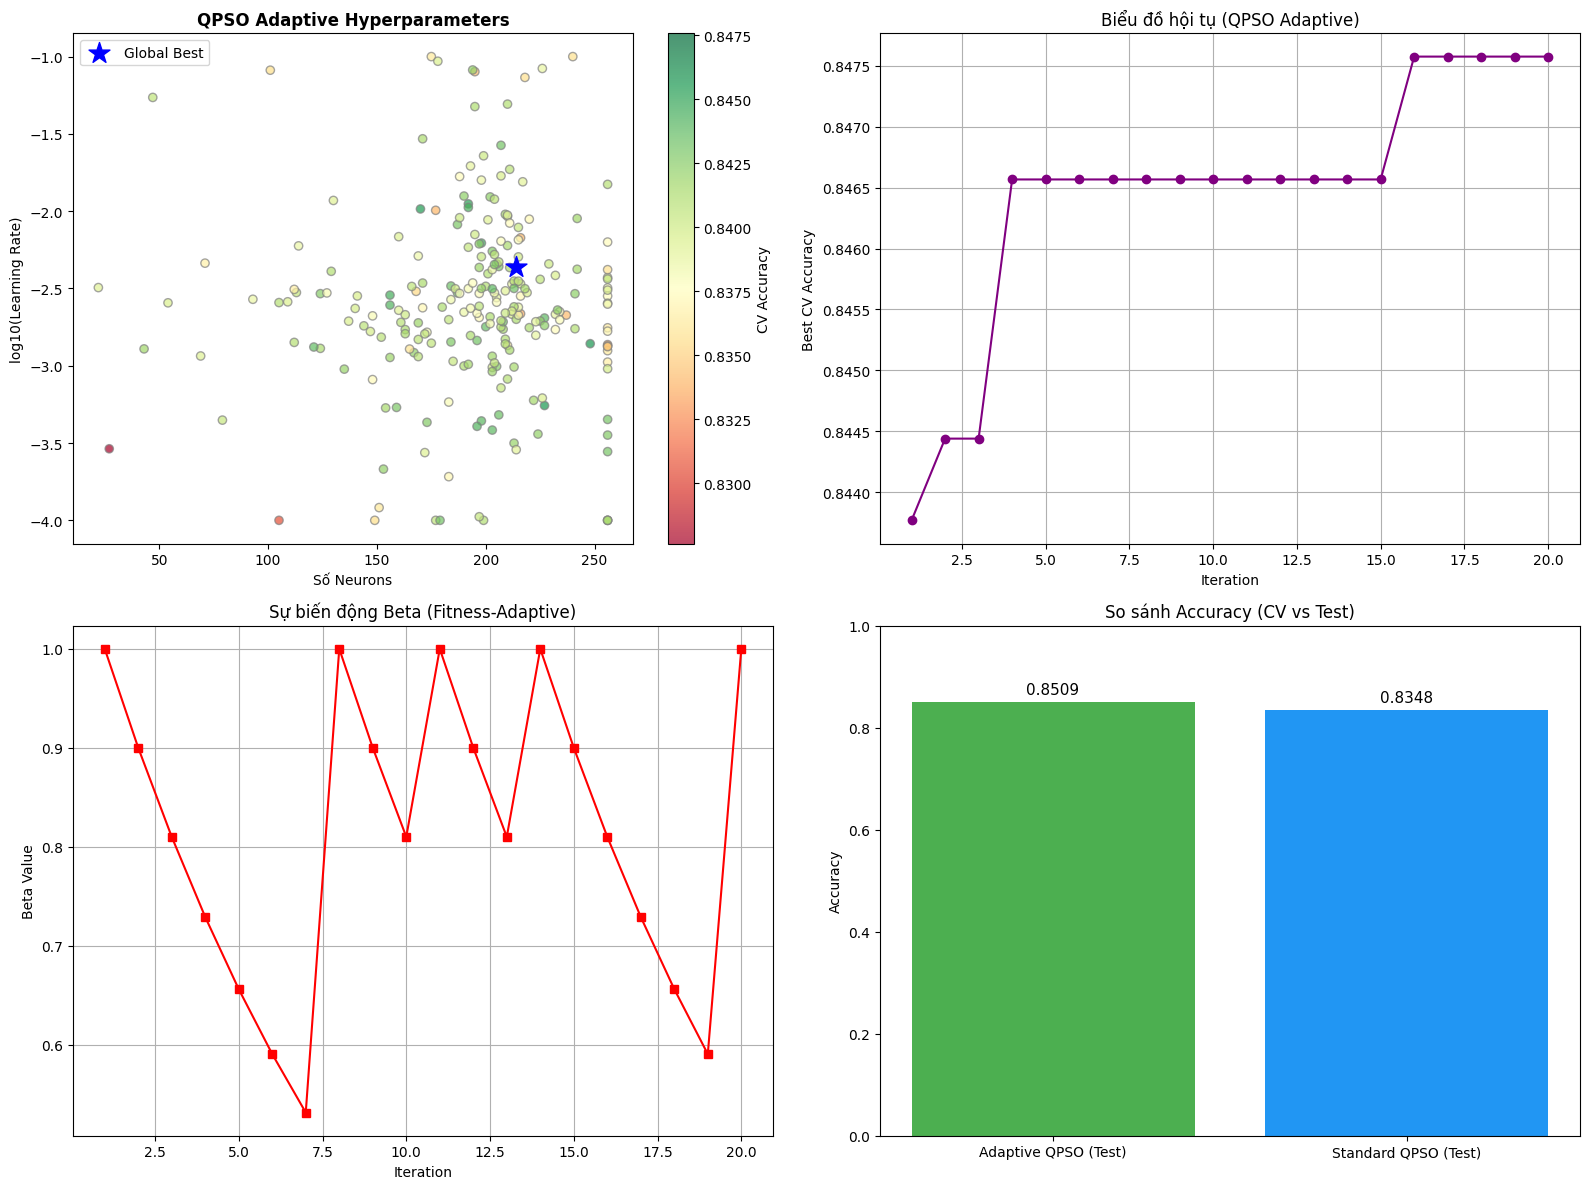

In [14]:
### 4. Visualization (Biểu đồ phân tán, Hội tụ, Cột Accuracy, và Beta curve)
history_df_ad = pd.DataFrame(pso_qpso_ad_data['history'])
convergence_ad = pso_qpso_ad_data['convergence']
beta_history_ad = pso_qpso_ad_data['beta_history']

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

# 1. Biểu đồ phân tán (Scatter plot)
scatter = axes[0].scatter(history_df_ad['n_neurons'], np.log10(history_df_ad['lr']), c=history_df_ad['score'], cmap='RdYlGn', alpha=0.7, edgecolors='grey')
axes[0].scatter(n_ad_best, np.log10(lr_ad_best), c='blue', s=250, marker='*', zorder=5, label='Global Best')
axes[0].set_xlabel('Số Neurons')
axes[0].set_ylabel('log10(Learning Rate)')
axes[0].set_title('QPSO Adaptive Hyperparameters', fontweight='bold')
axes[0].legend()
fig.colorbar(scatter, ax=axes[0], label='CV Accuracy')

# 2. Biểu đồ hội tụ (Convergence)
axes[1].plot(range(1, len(convergence_ad) + 1), convergence_ad, marker='o', linestyle='-', color='purple')
axes[1].set_xlabel('Iteration')
axes[1].set_ylabel('Best CV Accuracy')
axes[1].set_title('Biểu đồ hội tụ (QPSO Adaptive)')
axes[1].grid(True)

# 3. Biểu đồ thay đổi Beta (Fitness-Adaptive)
axes[2].plot(range(1, len(beta_history_ad) + 1), beta_history_ad, marker='s', linestyle='-', color='red')
axes[2].set_xlabel('Iteration')
axes[2].set_ylabel('Beta Value')
axes[2].set_title('Sự biến động Beta (Fitness-Adaptive)')
axes[2].grid(True)

# 4. Biểu đồ cột Accuracy (So sánh CV và Test)
labels = ['Adaptive QPSO (Test)', 'Standard QPSO (Test)']
acc_values = [test_acc_qpso_ad, test_qpso]
bars = axes[3].bar(labels, acc_values, color=['#4CAF50', '#2196F3'])
axes[3].set_ylim(0, 1.0)
axes[3].set_ylabel('Accuracy')
axes[3].set_title('So sánh Accuracy (CV vs Test)')
for bar in bars:
    yval = bar.get_height()
    axes[3].text(bar.get_x() + bar.get_width()/2, yval + 0.01, f'{yval:.4f}', ha='center', va='bottom', fontsize=11)

plt.tight_layout()
plt.show()


## 🚀 Ý tưởng 4: Per-particle β (Thích ứng theo khoảng cách từng hạt)
Thay vì áp dụng 1 hệ số $\beta$ chung cho toàn bầy, ở đây **mỗi hạt sẽ tự có một $\beta$ riêng**:
- Khoảng cách từ hạt tới `gbest` được chuẩn hóa về $[0, 1]$.
- Hạt ở **xa** `gbest` nhất sẽ có $\beta = 1.0$ (tối đa hóa khám phá - bay nhanh hơn về phía `gbest`).
- Hạt ở **gần** `gbest` nhất sẽ có $\beta = 0.5$ (khai thác cẩn thận vùng lân cận cực trị).
- Các hạt ở giữa nội suy tuyến tính giữa 0.5 và 1.0.

In [ ]:
import time
import numpy as np

def run_qpso_per_particle(
    X_tr, y_tr,
    n_particles=12, n_iter=20,
    beta_start=1.0,
    beta_end=0.5,
    seed=42
):
    rng    = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

    positions   = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    pbest_pos   = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos   = None
    gbest_score = -np.inf
    convergence = []
    history     = []
    avg_beta_history = []

    print(f'QPSO (Per-Particle Beta) | beta range: {beta_end} -> {beta_start}')
    print(f'   {n_particles} particles x {n_iter} iterations')
    print('-' * 60)
    t_start = time.time()

    for it in range(n_iter):
        scores = []
        for i in range(n_particles):
            score = fitness_single(positions[i], X_tr, y_tr, cv_obj, seed)
            scores.append(score)

            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i]   = positions[i].copy()

            if score > gbest_score:
                gbest_score = score
                gbest_pos   = positions[i].copy()

        # Tính khoảng cách Euclidean từ mỗi hạt tới gbest
        distances = np.linalg.norm(positions - gbest_pos, axis=1)
        dist_min = np.min(distances)
        dist_max = np.max(distances)
        
        # Chuẩn hóa khoảng cách về [0, 1]
        if dist_max == dist_min:
            norm_dist = np.full(n_particles, 0.5)
        else:
            norm_dist = (distances - dist_min) / (dist_max - dist_min)
            
        # Hạt càng xa (norm_dist lớn) -> beta càng lớn (gần beta_start)
        betas = beta_end + norm_dist * (beta_start - beta_end)
        avg_beta_history.append(np.mean(betas))
        
        # Ghi nhận lịch sử (lưu trữ beta của từng hạt)
        for i in range(n_particles):
            n_neur, lr, al = decode_position(positions[i])
            history.append({
                'iter': it, 'particle': i, 'score': scores[i],
                'n_neurons': n_neur, 'lr': lr, 'alpha': al, 'beta': betas[i]
            })

        # Cập nhật vị trí Lượng tử
        mbest = np.mean(pbest_pos, axis=0)

        for i in range(n_particles):
            phi = rng.random(size=DIM)
            p = phi * pbest_pos[i] + (1 - phi) * gbest_pos
            u = rng.random(size=DIM)
            u = np.clip(u, 1e-10, 1.0)
            distance = np.abs(mbest - positions[i])
            sign = np.where(rng.random(size=DIM) < 0.5, 1.0, -1.0)
            # SỬ DỤNG BETA RIÊNG CỦA HẠT i
            positions[i] = p + sign * betas[i] * distance * np.log(1.0 / u)

        positions = np.clip(positions, LOW, HIGH)
        convergence.append(gbest_score)
        n_neur, lr, al = decode_position(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | Avg Beta={np.mean(betas):.3f} | gbest={gbest_score:.4f} | neurons={n_neur:3d}, lr={lr:.5f}, alpha={al:.6f} | [{time.time()-t_start:.0f}s]')

    print('-' * 60)
    print(f'Hoan thanh QPSO Per-Particle! Thoi gian: {time.time()-t_start:.1f}s')
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history), avg_beta_history

gbest_qpso_pp, cv_qpso_pp, conv_qpso_pp, hist_qpso_pp, avg_beta_hist_pp = run_qpso_per_particle(
    X_train_sc, y_train,
    n_particles=12, n_iter=20,
    beta_start=1.0, beta_end=0.5,
    seed=RANDOM_SEED
)
n_qpso_pp, lr_qpso_pp, al_qpso_pp = decode_position(gbest_qpso_pp)
print(f'\nBest QPSO (Per-Particle): neurons={n_qpso_pp}, lr={lr_qpso_pp:.5f}, alpha={al_qpso_pp:.6f}')
print(f'CV Accuracy: {cv_qpso_pp:.4f}')


In [24]:
### 2. Lưu kết quả Train
import joblib

joblib.dump({
    'gbest_pos':  gbest_qpso_pp,
    'cv_score':   cv_qpso_pp,
    'convergence': conv_qpso_pp,
    'history':    hist_qpso_pp.to_dict('records'),
    'avg_beta_history': avg_beta_hist_pp
}, '../results/checkpoints/qpso_per_particle.pkl')

print('✅ Đã lưu: ../results/checkpoints/qpso_per_particle.pkl')


✅ Đã lưu: ../results/checkpoints/qpso_per_particle.pkl


In [35]:
### 3. Test trên tập dữ liệu
pso_qpso_pp_data = joblib.load('../results/checkpoints/qpso_per_particle.pkl')
gbest_qpso_pp_loaded = pso_qpso_pp_data['gbest_pos']
n_pp_best, lr_pp_best, al_pp_best = decode_position(gbest_qpso_pp_loaded)

model_qpso_pp = MLPClassifier(
    hidden_layer_sizes=(n_pp_best, n_pp_best),
    activation='relu',
    learning_rate_init=lr_pp_best,
    alpha=al_pp_best,
    max_iter=500,
    random_state=RANDOM_SEED,
    early_stopping=True,
    n_iter_no_change=15
)

model_qpso_pp.fit(X_train_sc, y_train)
y_pred_qpso_pp = model_qpso_pp.predict(X_test_sc)
test_acc_qpso_pp = np.mean(y_pred_qpso_pp == y_test)

print('Đánh giá QPSO Per-Particle trên tập Test:')
print(f'Test Accuracy: {test_acc_qpso_pp:.4f}')
print(classification_report(y_test, y_pred_qpso_pp))

# Lưu vào file CSV chung
save_test_accuracy('Per-particle Beta QPSO', test_acc_qpso_pp, (n_pp_best, lr_pp_best, al_pp_best), cv_score=pso_qpso_pp_data.get('cv_score'))

Đánh giá QPSO Per-Particle trên tập Test:
Test Accuracy: 0.8531
              precision    recall  f1-score   support

           0       0.89      0.82      0.85      1175
           1       0.82      0.89      0.85      1058

    accuracy                           0.85      2233
   macro avg       0.85      0.85      0.85      2233
weighted avg       0.86      0.85      0.85      2233



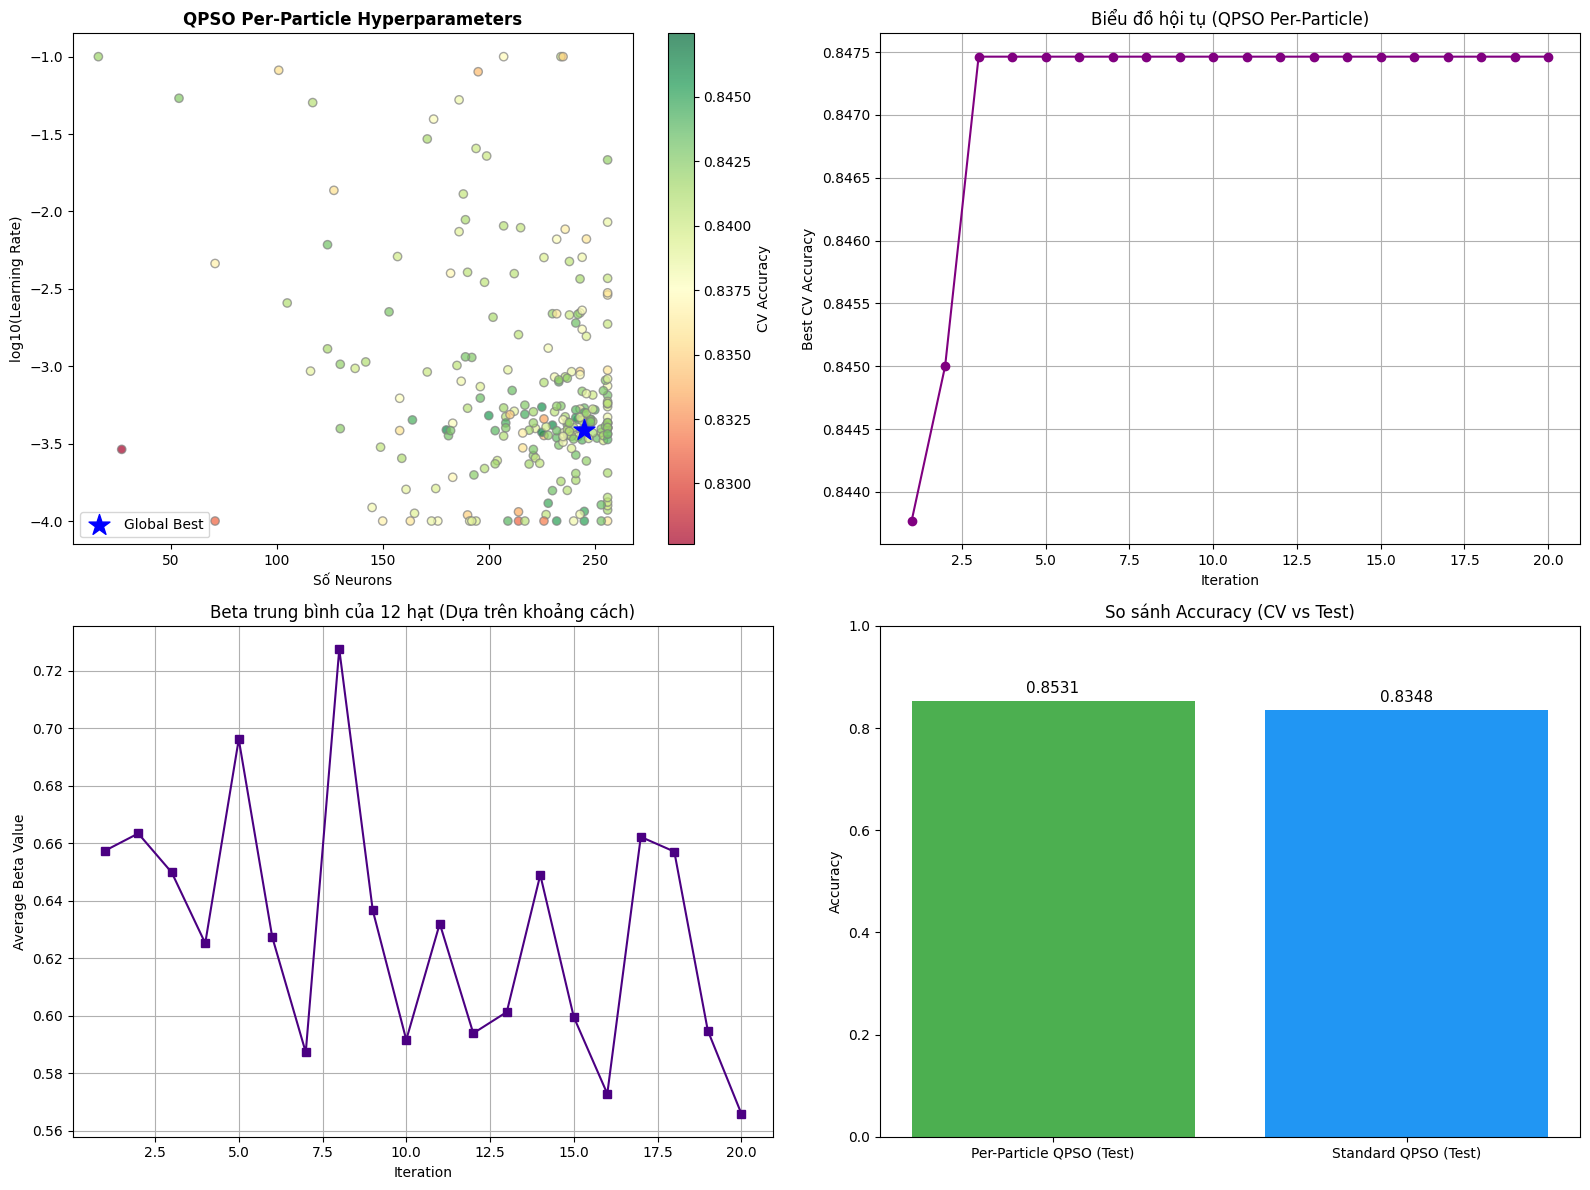

In [20]:
### 4. Visualization (Biểu đồ phân tán, Hội tụ, Cột Accuracy, và Trung bình Beta curve)
history_df_pp = pd.DataFrame(pso_qpso_pp_data['history'])
convergence_pp = pso_qpso_pp_data['convergence']
avg_beta_hist_pp = pso_qpso_pp_data['avg_beta_history']

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

# 1. Biểu đồ phân tán (Scatter plot)
scatter = axes[0].scatter(history_df_pp['n_neurons'], np.log10(history_df_pp['lr']), c=history_df_pp['score'], cmap='RdYlGn', alpha=0.7, edgecolors='grey')
axes[0].scatter(n_pp_best, np.log10(lr_pp_best), c='blue', s=250, marker='*', zorder=5, label='Global Best')
axes[0].set_xlabel('Số Neurons')
axes[0].set_ylabel('log10(Learning Rate)')
axes[0].set_title('QPSO Per-Particle Hyperparameters', fontweight='bold')
axes[0].legend()
fig.colorbar(scatter, ax=axes[0], label='CV Accuracy')

# 2. Biểu đồ hội tụ (Convergence)
axes[1].plot(range(1, len(convergence_pp) + 1), convergence_pp, marker='o', linestyle='-', color='purple')
axes[1].set_xlabel('Iteration')
axes[1].set_ylabel('Best CV Accuracy')
axes[1].set_title('Biểu đồ hội tụ (QPSO Per-Particle)')
axes[1].grid(True)

# 3. Biểu đồ thay đổi Beta (Trung bình của toàn bầy đàn)
axes[2].plot(range(1, len(avg_beta_hist_pp) + 1), avg_beta_hist_pp, marker='s', linestyle='-', color='indigo')
axes[2].set_xlabel('Iteration')
axes[2].set_ylabel('Average Beta Value')
axes[2].set_title('Beta trung bình của 12 hạt (Dựa trên khoảng cách)')
axes[2].grid(True)

# 4. Biểu đồ cột Accuracy (So sánh CV và Test)
labels = ['Per-Particle QPSO (Test)', 'Standard QPSO (Test)']
acc_values = [test_acc_qpso_pp, test_qpso]
bars = axes[3].bar(labels, acc_values, color=['#4CAF50', '#2196F3'])
axes[3].set_ylim(0, 1.0)
axes[3].set_ylabel('Accuracy')
axes[3].set_title('So sánh Accuracy (CV vs Test)')
for bar in bars:
    yval = bar.get_height()
    axes[3].text(bar.get_x() + bar.get_width()/2, yval + 0.01, f'{yval:.4f}', ha='center', va='bottom', fontsize=11)

plt.tight_layout()
plt.show()


## 🚀 Ý tưởng 5: Opposition-based QPSO (OQ-PSO)
Sự kết hợp hoàn hảo giữa **OBL (Opposition-Based Learning)** và cơ chế lượng tử **QPSO**:
- **Khởi tạo thông minh:** Tạo $N$ hạt ngẫu nhiên và $N$ hạt đối kháng. Đánh giá tất cả $2N$ hạt và chỉ chọn $N$ hạt xuất sắc nhất làm bầy đàn khởi đầu.
- **OBL Jumping:** Cứ mỗi `jump_rate` vòng lặp (ví dụ 5 vòng), thay vì để bầy đàn hội tụ quá nhanh vào local optima, ta tiếp tục tạo ra $N$ hạt đối kháng dựa trên không gian hiện tại của bầy đàn (dynamic bounds). Chắt lọc lại $N$ hạt tốt nhất từ $2N$ hạt để đi tiếp.
- Cập nhật vị trí vẫn hoàn toàn dựa trên Quantum Distribution (vận tốc = 0).

In [ ]:
import time
import numpy as np

def run_oq_pso(
    X_tr, y_tr,
    n_particles=12, n_iter=20,
    beta_start=1.0, beta_end=0.5,
    jump_rate=5,
    seed=42
):
    rng    = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

    # 1. Khởi tạo quần thể ban đầu & Đối kháng
    pos_init = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    pos_op = LOW + HIGH - pos_init
    combined_pos = np.vstack((pos_init, pos_op))
    combined_scores = np.zeros(2 * n_particles)
    
    print(f'OQ-PSO (Opposition-Based QPSO) | beta: {beta_start} -> {beta_end}')
    print(f'   Khởi tạo: Đánh giá {2*n_particles} hạt (OBL)')
    for i in range(2 * n_particles):
        combined_scores[i] = fitness_single(combined_pos[i], X_tr, y_tr, cv_obj, seed)
        
    best_indices = np.argsort(combined_scores)[-n_particles:]
    positions = combined_pos[best_indices].copy()
    
    pbest_pos = positions.copy()
    pbest_score = combined_scores[best_indices].copy()
    gbest_score = np.max(pbest_score)
    gbest_pos = pbest_pos[np.argmax(pbest_score)].copy()

    convergence = []
    history = []
    
    print(f'   {n_particles} particles x {n_iter} iterations | jump_rate={jump_rate}')
    print('-' * 60)
    t_start = time.time()

    for it in range(n_iter):
        beta = beta_start - (beta_start - beta_end) * (it / max(n_iter - 1, 1))

        # Cập nhật vị trí lượng tử
        mbest = np.mean(pbest_pos, axis=0)

        for i in range(n_particles):
            phi = rng.random(size=DIM)
            p = phi * pbest_pos[i] + (1 - phi) * gbest_pos
            u = rng.random(size=DIM)
            u = np.clip(u, 1e-10, 1.0)
            distance = np.abs(mbest - positions[i])
            sign = np.where(rng.random(size=DIM) < 0.5, 1.0, -1.0)
            positions[i] = p + sign * beta * distance * np.log(1.0 / u)

        positions = np.clip(positions, LOW, HIGH)

        # Đánh giá fitness
        for i in range(n_particles):
            score = fitness_single(positions[i], X_tr, y_tr, cv_obj, seed)
            
            n_neur, lr, al = decode_position(positions[i])
            history.append({
                'iter': it, 'particle': i, 'score': score,
                'n_neurons': n_neur, 'lr': lr, 'alpha': al, 'beta': beta,
                'type': 'normal'
            })
            
            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i] = positions[i].copy()
                
            if score > gbest_score:
                gbest_score = score
                gbest_pos = positions[i].copy()

        # OBL Jumping
        if (it + 1) % jump_rate == 0:
            curr_min = np.min(positions, axis=0)
            curr_max = np.max(positions, axis=0)
            pos_op_jump = curr_min + curr_max - positions
            
            scores_op_jump = np.zeros(n_particles)
            for i in range(n_particles):
                scores_op_jump[i] = fitness_single(pos_op_jump[i], X_tr, y_tr, cv_obj, seed)
                n_neur_op, lr_op, al_op = decode_position(pos_op_jump[i])
                history.append({
                    'iter': it, 'particle': n_particles + i, 'score': scores_op_jump[i],
                    'n_neurons': n_neur_op, 'lr': lr_op, 'alpha': al_op, 'beta': beta,
                    'type': 'opposition'
                })
            
            combined_pos_jump = np.vstack((positions, pos_op_jump))
            combined_pbest = np.vstack((pbest_pos, pos_op_jump))
            combined_scores_jump = np.concatenate((pbest_score, scores_op_jump))
            
            best_indices = np.argsort(combined_scores_jump)[-n_particles:]
            
            positions = combined_pos_jump[best_indices].copy()
            pbest_pos = combined_pbest[best_indices].copy()
            pbest_score = combined_scores_jump[best_indices].copy()
            
            if np.max(pbest_score) > gbest_score:
                gbest_score = np.max(pbest_score)
                gbest_pos = pbest_pos[np.argmax(pbest_score)].copy()

        convergence.append(gbest_score)
        n_neur, lr, al = decode_position(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | beta={beta:.3f} | gbest={gbest_score:.4f} | neurons={n_neur:3d}, lr={lr:.5f}, alpha={al:.6f} | [{time.time()-t_start:.0f}s]')

    print('-' * 60)
    print(f'Hoan thanh OQ-PSO! Thoi gian: {time.time()-t_start:.1f}s')
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history)

gbest_oqpso, cv_oqpso, conv_oqpso, hist_oqpso = run_oq_pso(
    X_train_sc, y_train,
    n_particles=12, n_iter=20,
    beta_start=1.0, beta_end=0.5, jump_rate=5,
    seed=RANDOM_SEED
)
n_oqpso, lr_oqpso, al_oqpso = decode_position(gbest_oqpso)
print(f'\nBest OQ-PSO: neurons={n_oqpso}, lr={lr_oqpso:.5f}, alpha={al_oqpso:.6f}')
print(f'CV Accuracy: {cv_oqpso:.4f}')


In [28]:
### 2. Lưu kết quả Train
import joblib

joblib.dump({
    'gbest_pos':  gbest_oqpso,
    'cv_score':   cv_oqpso,
    'convergence': conv_oqpso,
    'history':    hist_oqpso.to_dict('records')
}, '../results/checkpoints/oq_pso.pkl')

print('✅ Đã lưu: ../results/checkpoints/oq_pso.pkl')


✅ Đã lưu: ../results/checkpoints/oq_pso.pkl


In [36]:
### 3. Test trên tập dữ liệu
pso_oqpso_data = joblib.load('../results/checkpoints/oq_pso.pkl')
gbest_oqpso_loaded = pso_oqpso_data['gbest_pos']
n_oq_best, lr_oq_best, al_oq_best = decode_position(gbest_oqpso_loaded)

model_oqpso = MLPClassifier(
    hidden_layer_sizes=(n_oq_best, n_oq_best),
    activation='relu',
    learning_rate_init=lr_oq_best,
    alpha=al_oq_best,
    max_iter=500,
    random_state=RANDOM_SEED,
    early_stopping=True,
    n_iter_no_change=15
)

model_oqpso.fit(X_train_sc, y_train)
y_pred_oqpso = model_oqpso.predict(X_test_sc)
test_acc_oqpso = np.mean(y_pred_oqpso == y_test)

print('Đánh giá OQ-PSO trên tập Test:')
print(f'Test Accuracy: {test_acc_oqpso:.4f}')
print(classification_report(y_test, y_pred_oqpso))

# Lưu vào file CSV chung
save_test_accuracy('OQ-PSO', test_acc_oqpso, (n_oq_best, lr_oq_best, al_oq_best), cv_score=pso_oqpso_data.get('cv_score'))

Đánh giá OQ-PSO trên tập Test:
Test Accuracy: 0.8549
              precision    recall  f1-score   support

           0       0.89      0.82      0.86      1175
           1       0.82      0.89      0.85      1058

    accuracy                           0.85      2233
   macro avg       0.86      0.86      0.85      2233
weighted avg       0.86      0.85      0.85      2233



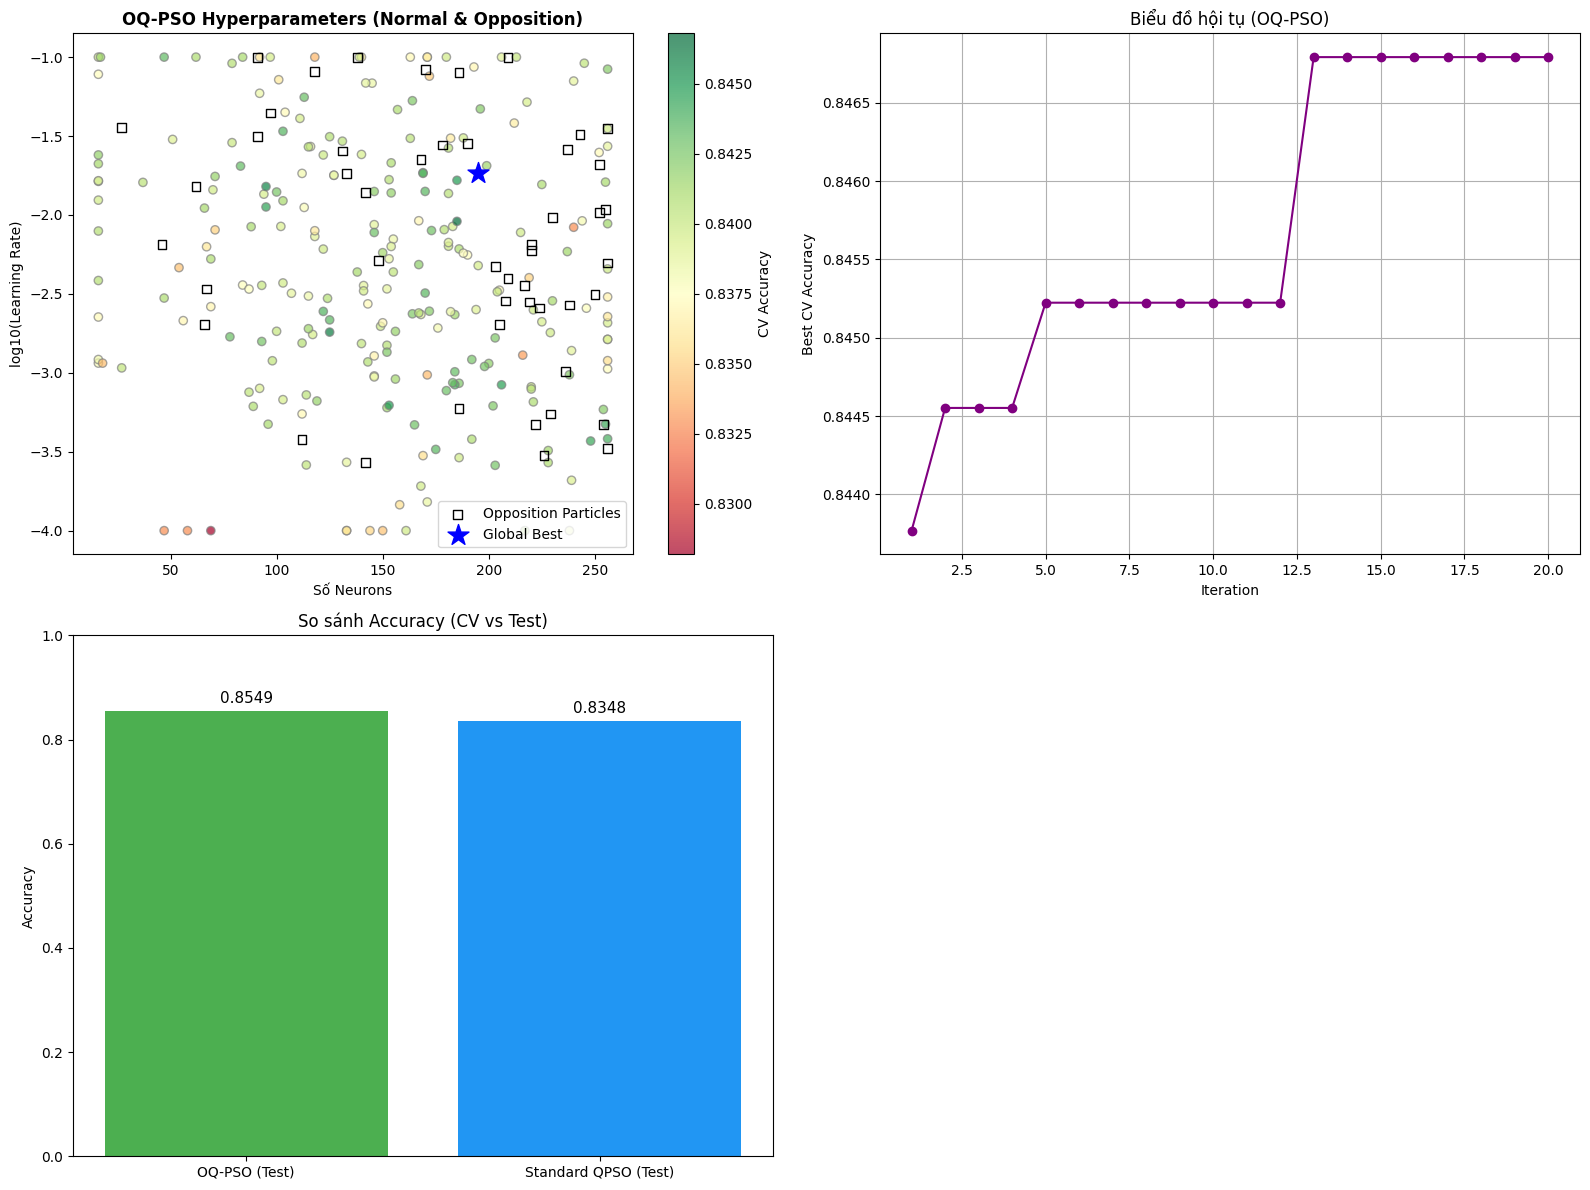

In [22]:
history_df_oq = pd.DataFrame(pso_oqpso_data['history'])
convergence_oq = pso_oqpso_data['convergence']

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()
axes[3].axis('off')

# Phân chia hạt normal và hạt opposition
hist_normal = history_df_oq[history_df_oq['type'] == 'normal']
hist_op = history_df_oq[history_df_oq['type'] == 'opposition']

# 1. Biểu đồ phân tán (Scatter plot)
scatter = axes[0].scatter(hist_normal['n_neurons'], np.log10(hist_normal['lr']), c=hist_normal['score'], cmap='RdYlGn', alpha=0.7, edgecolors='grey')
axes[0].scatter(hist_op['n_neurons'], np.log10(hist_op['lr']), c='none', edgecolors='black', marker='s', s=40, label='Opposition Particles')
axes[0].scatter(n_oq_best, np.log10(lr_oq_best), c='blue', s=250, marker='*', zorder=5, label='Global Best')
axes[0].set_xlabel('Số Neurons')
axes[0].set_ylabel('log10(Learning Rate)')
axes[0].set_title('OQ-PSO Hyperparameters (Normal & Opposition)', fontweight='bold')
axes[0].legend()
fig.colorbar(scatter, ax=axes[0], label='CV Accuracy')

# 2. Biểu đồ hội tụ (Convergence)
axes[1].plot(range(1, len(convergence_oq) + 1), convergence_oq, marker='o', linestyle='-', color='purple')
axes[1].set_xlabel('Iteration')
axes[1].set_ylabel('Best CV Accuracy')
axes[1].set_title('Biểu đồ hội tụ (OQ-PSO)')
axes[1].grid(True)

# 3. Biểu đồ cột Accuracy (So sánh CV và Test)
labels = ['OQ-PSO (Test)', 'Standard QPSO (Test)']
acc_values = [test_acc_oqpso, test_qpso]
bars = axes[2].bar(labels, acc_values, color=['#4CAF50', '#2196F3'])
axes[2].set_ylim(0, 1.0)
axes[2].set_ylabel('Accuracy')
axes[2].set_title('So sánh Accuracy (CV vs Test)')
for bar in bars:
    yval = bar.get_height()
    axes[2].text(bar.get_x() + bar.get_width()/2, yval + 0.01, f'{yval:.4f}', ha='center', va='bottom', fontsize=11)

plt.tight_layout()
plt.show()

## 🚀 Tổng hợp Trực quan hoá (Master Visualization)
Tổng hợp toàn bộ các biểu đồ phân tán, hội tụ và so sánh kết quả Test Accuracy của các ý tưởng đã triển khai.

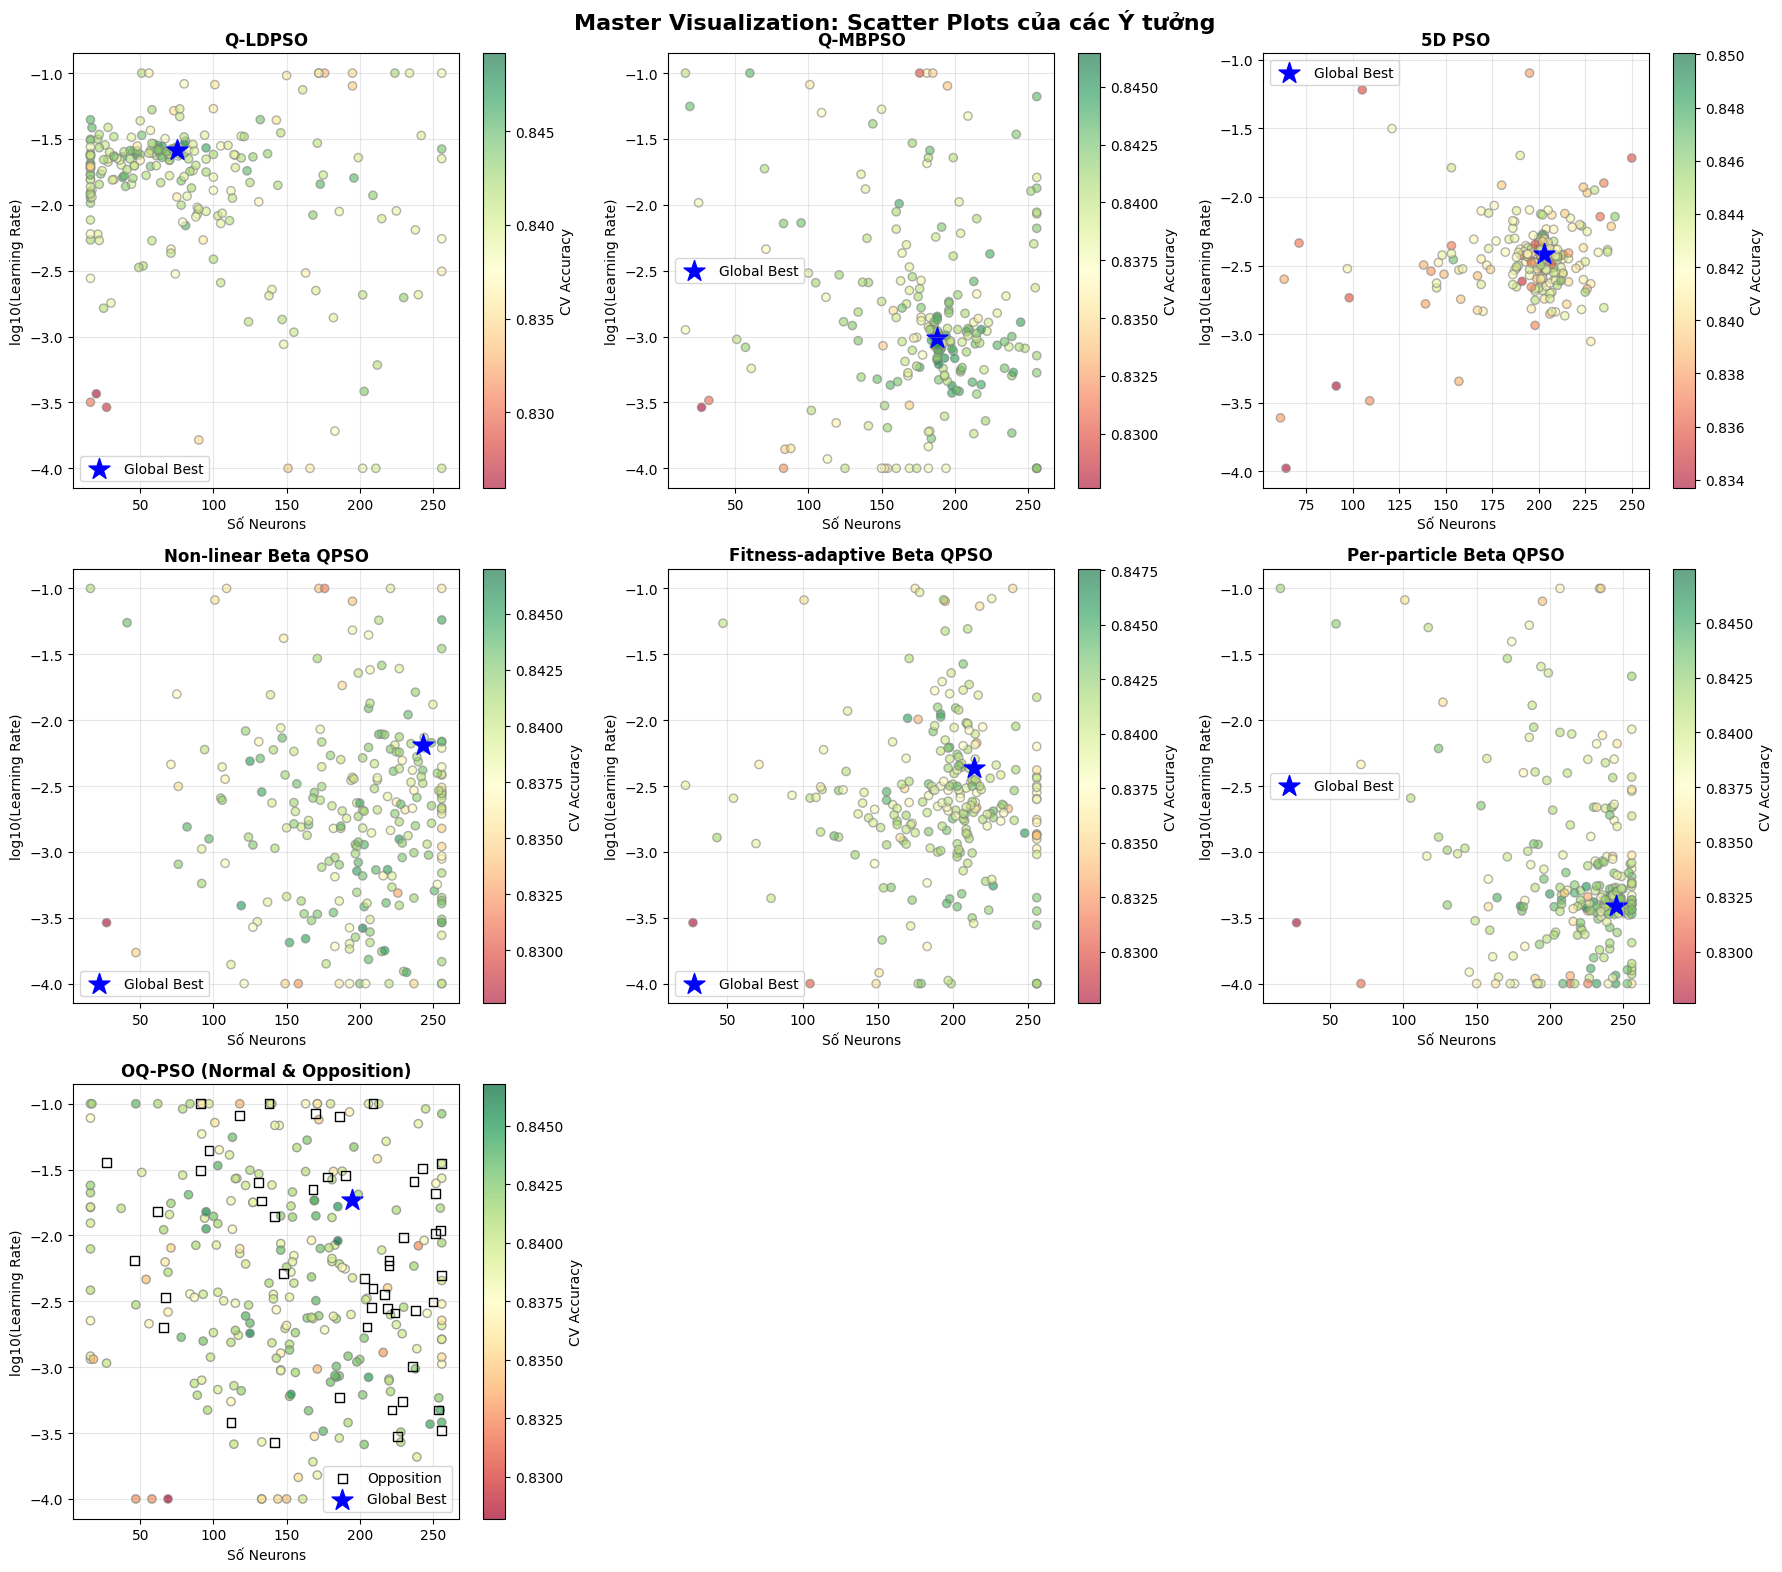

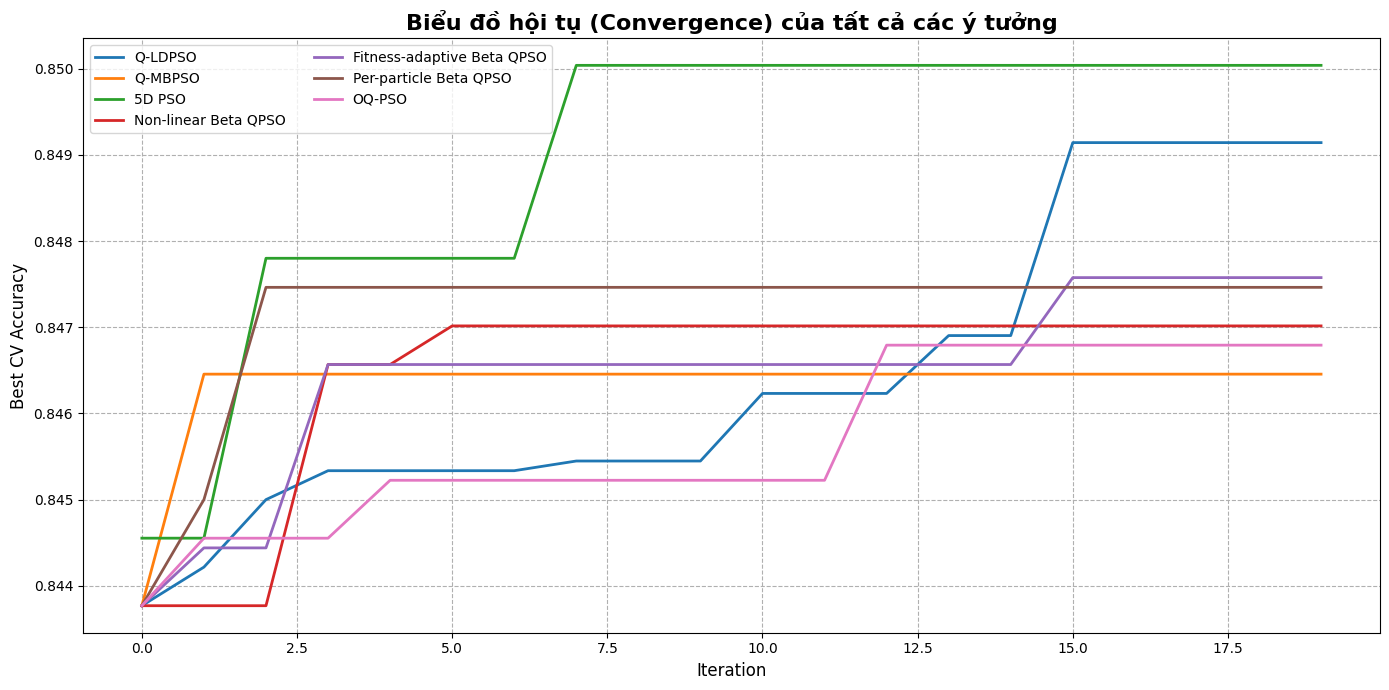

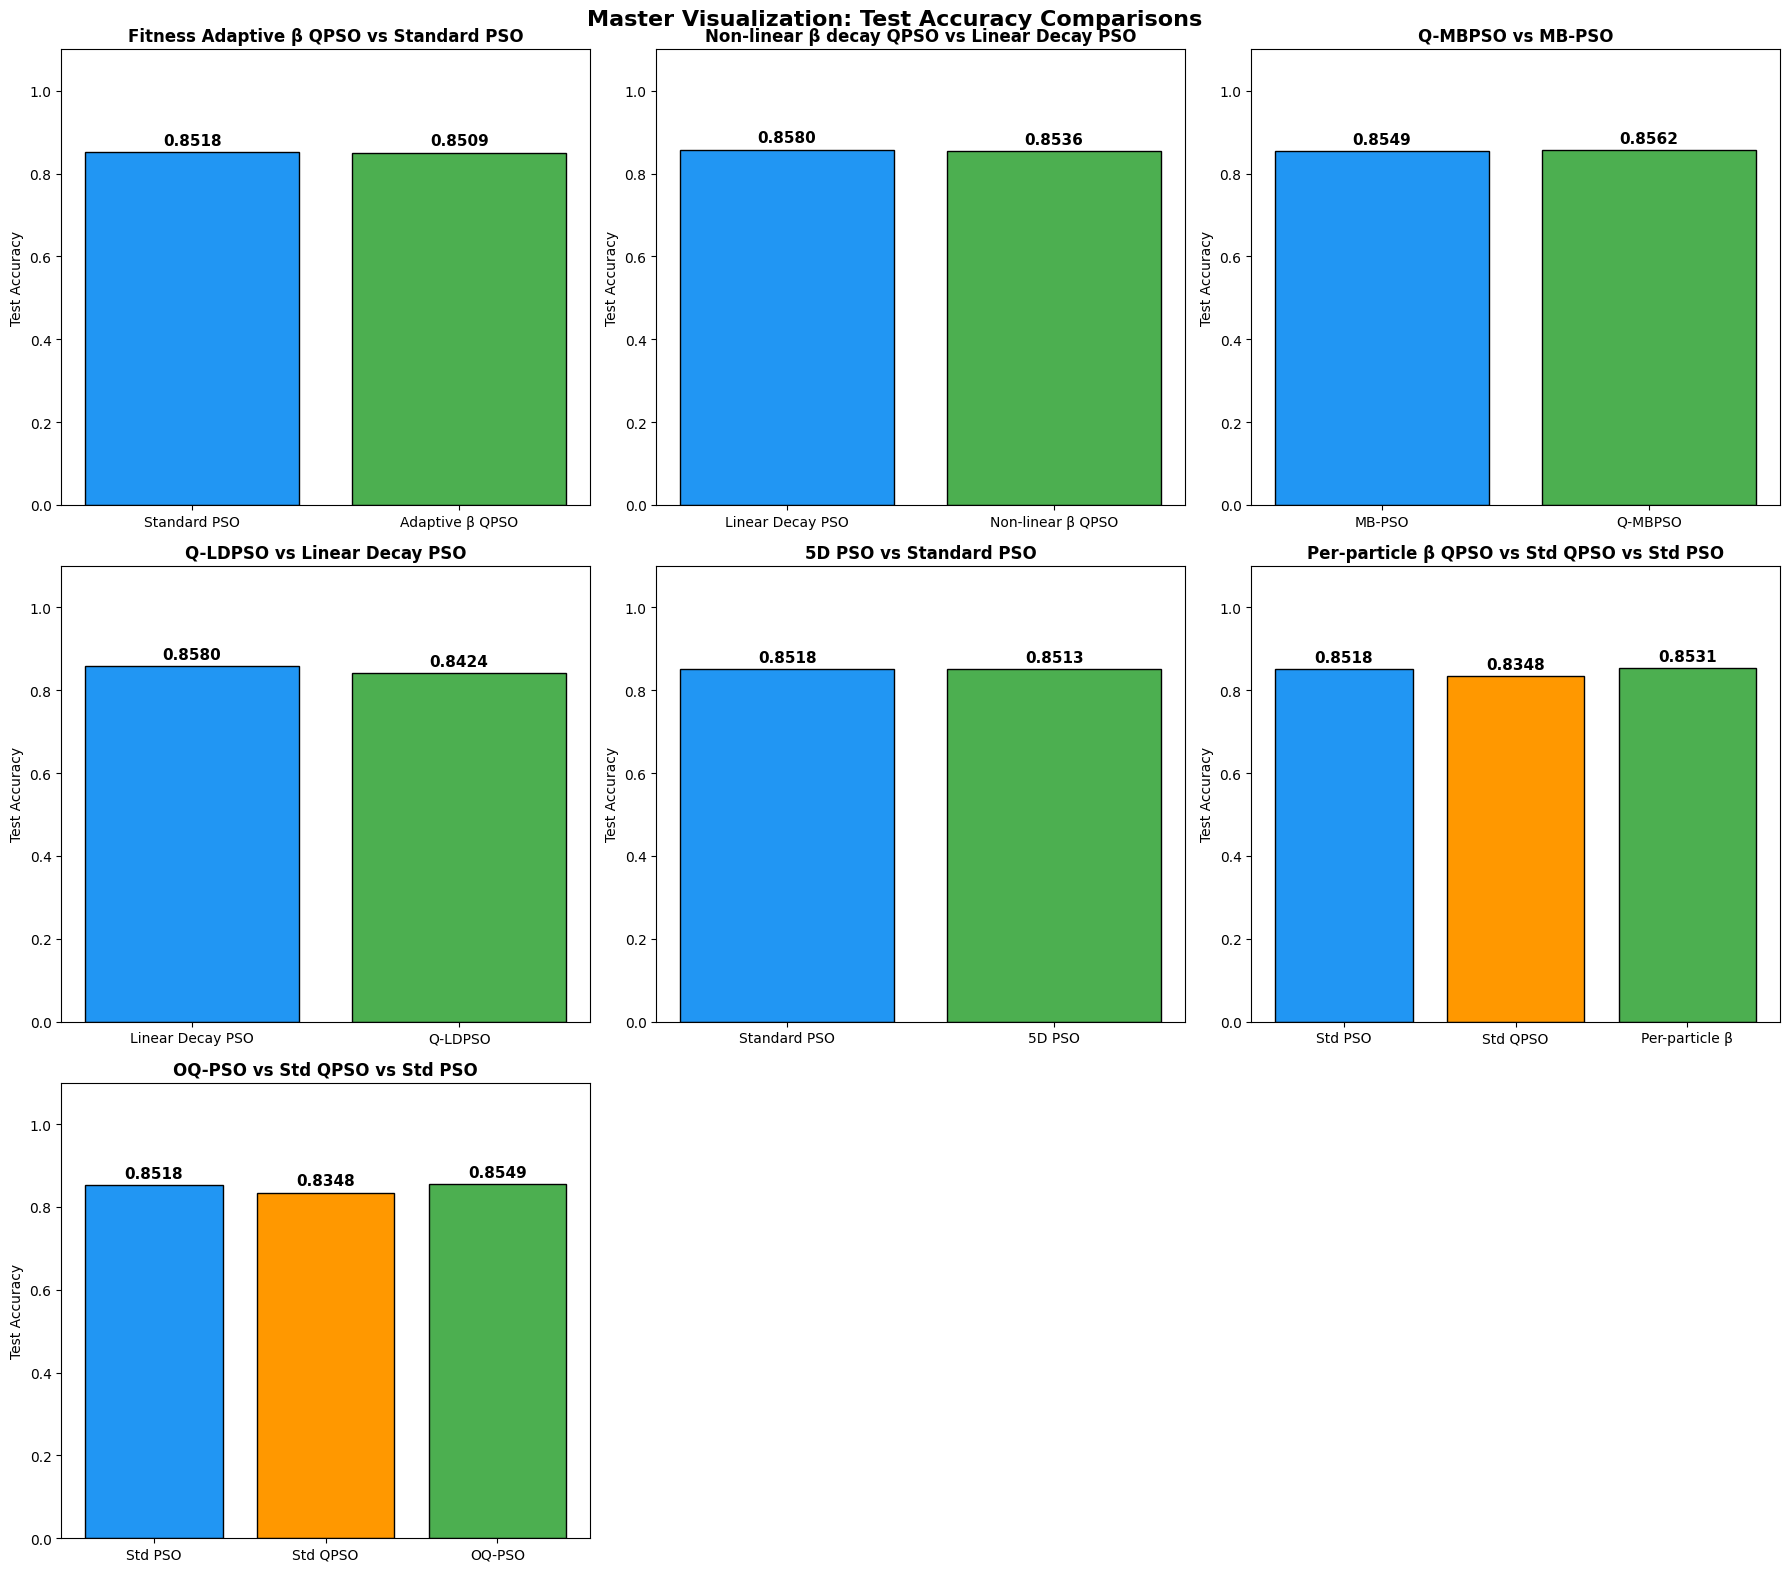

In [44]:

### =========================================================================
### TỔNG HỢP TRỰC QUAN HOÁ (MASTER VISUALIZATION) CHO CÁC Ý TƯỞNG
### =========================================================================
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. BIỂU ĐỒ PHÂN TÁN (SCATTER PLOTS) - LƯỚI 3x3
fig_scatter, axes_scatter = plt.subplots(3, 3, figsize=(18, 16))
axes_scatter = axes_scatter.flatten()

# Sử dụng dữ liệu từ biến Training (nếu có) hoặc từ biến Test (history_df_...) 
scatter_data = [
    (hist_qld, n_qld, lr_qld, 'Q-LDPSO'),
    (hist_qmb, n_qmb, lr_qmb, 'Q-MBPSO'),
    (pd.DataFrame(pso_5d_data['history']) if 'pso_5d_data' in globals() else hist_5d, n_5d, lr_5d, '5D PSO'),
    (history_df_nl if 'history_df_nl' in globals() else hist_qpso_nl, n_nl_best, lr_nl_best, 'Non-linear Beta QPSO'),
    (history_df_ad if 'history_df_ad' in globals() else hist_qpso_ad, n_ad_best, lr_ad_best, 'Fitness-adaptive Beta QPSO'),
    (history_df_pp if 'history_df_pp' in globals() else hist_qpso_pp, n_pp_best, lr_pp_best, 'Per-particle Beta QPSO')
]

for i, (hist, n_best, lr_best, title) in enumerate(scatter_data):
    if hist is not None:
        sc = axes_scatter[i].scatter(hist['n_neurons'], np.log10(hist['lr']),
                        c=hist['score'], cmap='RdYlGn', alpha=0.6, edgecolors='grey')
        axes_scatter[i].scatter(n_best, np.log10(lr_best), c='blue', s=250, marker='*', label='Global Best')
        axes_scatter[i].set_title(title, fontweight='bold')
        axes_scatter[i].set_xlabel('Số Neurons')
        axes_scatter[i].set_ylabel('log10(Learning Rate)')
        axes_scatter[i].legend()
        fig_scatter.colorbar(sc, ax=axes_scatter[i], label='CV Accuracy')
    axes_scatter[i].grid(True, alpha=0.3)

# Ô thứ 7: OQ-PSO
ax_oq = axes_scatter[6]
oq_data = history_df_oq if 'history_df_oq' in globals() else pd.DataFrame(hist_oqpso)
hist_normal = oq_data[oq_data['type'] == 'normal']
hist_op = oq_data[oq_data['type'] == 'opposition']

sc_oq = ax_oq.scatter(hist_normal['n_neurons'], np.log10(hist_normal['lr']), c=hist_normal['score'], cmap='RdYlGn', alpha=0.7, edgecolors='grey')
ax_oq.scatter(hist_op['n_neurons'], np.log10(hist_op['lr']), c='none', edgecolors='black', marker='s', s=40, label='Opposition')
ax_oq.scatter(n_oq_best, np.log10(lr_oq_best), c='blue', s=250, marker='*', label='Global Best')
ax_oq.set_title('OQ-PSO (Normal & Opposition)', fontweight='bold')
ax_oq.set_xlabel('Số Neurons')
ax_oq.set_ylabel('log10(Learning Rate)')
ax_oq.legend()
fig_scatter.colorbar(sc_oq, ax=ax_oq, label='CV Accuracy')
ax_oq.grid(True, alpha=0.3)

# Ẩn 2 ô cuối
axes_scatter[7].axis('off')
axes_scatter[8].axis('off')

plt.suptitle('Master Visualization: Scatter Plots của các Ý tưởng', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# 2. BIỂU ĐỒ HỘI TỤ CHUNG
fig_conv, ax_conv = plt.subplots(figsize=(14, 7))
ax_conv.plot(conv_qld, label='Q-LDPSO', linewidth=2)
ax_conv.plot(conv_qmb, label='Q-MBPSO', linewidth=2)
ax_conv.plot(pso_5d_data['convergence'] if 'pso_5d_data' in globals() else conv_5d, label='5D PSO', linewidth=2)
ax_conv.plot(convergence_nl if 'convergence_nl' in globals() else conv_qpso_nl, label='Non-linear Beta QPSO', linewidth=2)
ax_conv.plot(convergence_ad if 'convergence_ad' in globals() else conv_qpso_ad, label='Fitness-adaptive Beta QPSO', linewidth=2)
ax_conv.plot(convergence_pp if 'convergence_pp' in globals() else conv_qpso_pp, label='Per-particle Beta QPSO', linewidth=2)
ax_conv.plot(convergence_oq if 'convergence_oq' in globals() else conv_oqpso, label='OQ-PSO', linewidth=2)

ax_conv.set_title('Biểu đồ hội tụ (Convergence) của tất cả các ý tưởng', fontsize=16, fontweight='bold')
ax_conv.set_xlabel('Iteration', fontsize=12)
ax_conv.set_ylabel('Best CV Accuracy', fontsize=12)
ax_conv.legend(ncol=2)
ax_conv.grid(True, linestyle='--')
plt.tight_layout()
plt.show()

# 3. BIỂU ĐỒ CỘT SO SÁNH TEST ACCURACY
fig_bar, axes_bar = plt.subplots(3, 3, figsize=(18, 16))
axes_bar = axes_bar.flatten()

comparisons = [
    # (Title, labels, scores, colors)
    ('Fitness Adaptive β QPSO vs Standard PSO', 
     ['Standard PSO', 'Adaptive β QPSO'], 
     [test_std, test_acc_qpso_ad], 
     ['#2196F3', '#4CAF50']),
     
    ('Non-linear β decay QPSO vs Linear Decay PSO',
     ['Linear Decay PSO', 'Non-linear β QPSO'],
     [test_ld, test_acc_qpso_nl],
     ['#2196F3', '#4CAF50']),
     
    ('Q-MBPSO vs MB-PSO',
     ['MB-PSO', 'Q-MBPSO'],
     [test_mb, test_qmb],
     ['#2196F3', '#4CAF50']),
     
    ('Q-LDPSO vs Linear Decay PSO',
     ['Linear Decay PSO', 'Q-LDPSO'],
     [test_ld, test_qld],
     ['#2196F3', '#4CAF50']),
     
    ('5D PSO vs Standard PSO',
     ['Standard PSO', '5D PSO'],
     [test_std, test_acc_5d],
     ['#2196F3', '#4CAF50']),
     
    ('Per-particle β QPSO vs Std QPSO vs Std PSO',
     ['Std PSO', 'Std QPSO', 'Per-particle β'],
     [test_std, test_qpso, test_acc_qpso_pp],
     ['#2196F3', '#FF9800', '#4CAF50']),
     
    ('OQ-PSO vs Std QPSO vs Std PSO',
     ['Std PSO', 'Std QPSO', 'OQ-PSO'],
     [test_std, test_qpso, test_acc_oqpso],
     ['#2196F3', '#FF9800', '#4CAF50'])
]

for i, (title, labels, scores, colors) in enumerate(comparisons):
    bars = axes_bar[i].bar(labels, scores, color=colors, edgecolor='black')
    axes_bar[i].set_title(title, fontweight='bold')
    axes_bar[i].set_ylim(0, 1.1)
    axes_bar[i].set_ylabel('Test Accuracy')
    
    # Text on bars
    for bar in bars:
        yval = bar.get_height()
        axes_bar[i].text(bar.get_x() + bar.get_width()/2, yval + 0.01, f'{yval:.4f}', ha='center', va='bottom', fontsize=11, fontweight='bold')
    
axes_bar[7].axis('off')
axes_bar[8].axis('off')

plt.suptitle('Master Visualization: Test Accuracy Comparisons', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()


## 📋 Bảng tổng hợp Test Accuracy của tất cả các thuật toán

In [8]:
# Đọc và hiển thị toàn bộ kết quả đã lưu trong file test_accuracy.csv
df_summary = pd.read_csv(RESULT_CSV_PATH)
df_summary = df_summary.sort_values(by='Test_Accuracy', ascending=False).reset_index(drop=True)
print(f'✅ Tổng số thuật toán đã lưu: {len(df_summary)}')
df_summary

✅ Tổng số thuật toán đã lưu: 16


,Algorithm,Test_Accuracy,CV_Score,n_neurons,lr,alpha,n_layers,batch_size
0,PSO + Linear Decay w,0.8580,0.8461,194,0.00099,0.00195,2,200
1,FO-PSO,0.8562,0.8475,125,0.00149,0.00053,2,200
2,Q-MBPSO (Quantum Top-K MB),0.8562,0.8465,188,0.00098,0.00110,2,200
3,CPSO,0.8558,0.8468,206,0.00016,0.00035,2,200
4,PSO + Fitness Avg,0.8554,0.8450,175,0.00043,0.10000,2,200
5,MB-PSO,0.8549,0.8471,225,0.00043,0.00064,2,200
6,OQ-PSO,0.8549,0.8468,195,0.01845,0.07142,2,200
7,Non-linear Beta QPSO,0.8536,0.8470,243,0.00643,0.10000,2,200
8,NL-PSO,0.8531,0.8456,130,0.00177,0.00078,2,200
9,Per-particle Beta QPSO,0.8531,0.8475,245,0.00039,0.00930,2,200
